# Whole-Building AI-IoT Retrofit Research — Full Google Colab Pipeline

**Project:** *Quantifying the Economic–Environmental Trade-offs of Retrofitting Legacy Buildings*

This notebook implements a reproducible, staged research pipeline for **whole-building retrofits**. It is not an HVAC-only thermostat demo.

## Project scope inherited from the project reference

- Retain existing building infrastructure where possible and add an IoT/edge digital layer.
- Assess cooling/HVAC, ventilation, lighting and whole-building electricity; add other end uses when metering data are available.
- Build hourly energy baselines using historical energy, weather and calendar data.
- Compare three retrofit tiers and cost-first versus carbon-first control priorities.
- Quantify energy savings, financial payback, NPV and net lifecycle CO₂e.

## Dataset strategy — do not fabricate a single merged building

No identified public dataset provides *all* of the following for a pre-1980 commercial building: whole-building and end-use meters, HVAC actuator points, indoor sensors, occupancy, weather, tariffs, and embodied carbon. We therefore join evidence at the **model / validation level**, never by concatenating unrelated buildings into one synthetic time series:

1. **LBNL Building 59 (measured; sensor-rich):** whole-building and end-use energy, HVAC operational points, indoor/outdoor environment and occupant counts. Three years, 27 CSV time-series files and 337 points. It is an office built in 2015, so it is a *measured operational benchmark*, **not** a legacy-building sample. Used for VAE sensor-anomaly training and measured-data workflow validation. [Zenodo record](https://zenodo.org/records/5951008), DOI `10.7941/D1N33Q`.
2. **DOE pre-1980 Commercial Reference Buildings (physical legacy archetypes):** whole-building EnergyPlus models organized by building type and climate zone. The pre-1980 set includes office, retail, school and other archetypes. It is a *modelled reference building*, not measured data. [DOE download page](https://www.energy.gov/cmei/buildings/existing-commercial-reference-buildings-constructed-1980).
3. **Climate.OneBuilding EPW weather:** this notebook attempts to download Surat, Gujarat TMYx weather. You can upload a different EPW. [India/Gujarat weather directory](https://climate.onebuilding.org/WMO_Region_2_Asia/IND_India/).
4. **BDG2 (optional measured multi-building benchmark):** hourly meter readings, building metadata and weather; use it for separate cross-building baseline checks. It does not provide the full sensor/actuator state needed for DRL. [GitHub repository](https://github.com/buds-lab/building-data-genome-project-2).
5. **ComStock (optional modelled commercial stock):** whole-building end-use profiles and upgrade scenarios at 15-minute resolution; not direct measured data and large to download. [Data guide](https://natlabrockies.github.io/ComStock.github.io/docs/data.html).

## Models and their roles

- **XGBoost:** baseline whole-building demand estimator.
- **VAE:** detects anomalous sensor patterns in the measured sensor-rich dataset. It does not magically correct sensors or prove the precise fault cause.
- **PPO / DRL:** trains adaptive operational control in EnergyPlus through Sinergym.
- **NSGA-II:** searches the cost–carbon trade-off over the simulated retrofit tiers and control priorities.
- **EnergyPlus:** physically simulates the legacy building model. GPU does not accelerate the EnergyPlus solver; the simulator is CPU-bound. GPU is used where supported for PyTorch VAE and XGBoost; PPO's small policy network may run faster on CPU.

## Required manual checkpoint

The notebook downloads measured sensor data and Surat weather automatically where possible. **You must upload a DOE pre-1980 building model that has been upgraded to EnergyPlus 25.1-compatible epJSON (or a compatible IDF) and map the actual meter/sensor columns after inspecting the downloaded data dictionary.** The notebook deliberately stops/flags unknown mappings instead of inventing them.

Run cells sequentially. The defaults are **smoke-test settings**; increase training and run periods for final research. Never report demonstration signals, demo assumptions or short simulation episodes as validated research results.

## 0. Google Colab runtime

Select **Runtime → Change runtime type → T4 GPU** if available. Set `QUICK_RUN=True` for first verification. Set it to `False` only after all data and model mappings pass the validation cells.

In [7]:
# Analysis complete. Ready to answer questions on the pipeline stages.
print("Pipeline stages successfully analyzed and understood.")

Pipeline stages successfully analyzed and understood.


In [8]:

import sys
import platform
import torch
import os
import subprocess

print("========== RUNTIME CHECK ==========")
print("Python version:", sys.version)
print("Platform:", platform.platform())
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)
else:
    print("WARNING: GPU not detected. Check Runtime settings.")

print("\nDisk space:")
subprocess.run(["df", "-h", "/content"])
print("\n========== CHECK COMPLETE ==========")


========== RUNTIME CHECK ==========
Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Platform: Linux-6.6.159+-x86_64-with-glibc2.39
PyTorch version: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4
CUDA version: 13.0

Disk space:

========== CHECK COMPLETE ==========


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [9]:
# Core packages. Colab usually provides PyTorch; do not blindly reinstall CUDA/PyTorch.
!pip -q install "xgboost>=2.0" pyarrow openpyxl scikit-learn matplotlib seaborn tqdm requests beautifulsoup4 pymoo stable-baselines3 tensorboard

In [10]:
import os, sys, re, json, math, time, glob, shutil, zipfile, subprocess, warnings, hashlib
from pathlib import Path
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import requests
import torch
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

ROOT = Path("/content/whole_building_retrofit_full")
DATA_DIR = ROOT / "data"
MODEL_DIR = ROOT / "models"
OUTPUT_DIR = ROOT / "outputs"
ENERGYPLUS_DIR = ROOT / "energyplus"
for p in [ROOT, DATA_DIR, MODEL_DIR, OUTPUT_DIR, ENERGYPLUS_DIR]:
    p.mkdir(parents=True, exist_ok=True)

GPU_AVAILABLE = torch.cuda.is_available()
DEVICE = "cuda" if GPU_AVAILABLE else "cpu"
print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("GPU:", GPU_AVAILABLE, torch.cuda.get_device_name(0) if GPU_AVAILABLE else "CPU only")
print("Working directory:", ROOT)

Python: 3.13.16
PyTorch: 2.14.1+cu130
GPU: True Tesla T4
Working directory: /content/whole_building_retrofit_full


## 1. Master configuration

Edit this cell after the data inventory. The three important manual fields are `WHOLE_BUILDING_TARGET_COLUMN`, `WHOLE_BUILDING_TARGET_UNIT`, and the financial/carbon assumptions. Leave financial values as `None` until supported by a tariff, grid-factor and retrofit-cost source.

In [11]:
# --------------------------- DATA ACQUISITION ---------------------------
DOWNLOAD_BUILDING59 = True       # measured operational + sensor-rich dataset (~263 MB ZIP; ~2.38 GB expanded)
DOWNLOAD_SURAT_EPW = True        # attempts to obtain a Surat TMYx EPW
DOWNLOAD_BDG2 = False            # optional large multi-building benchmark; separate evidence stream
DOWNLOAD_COMSTOCK = False        # optional and potentially very large; modelled stock dataset

# --------------------------- DATA MAPPING -------------------------------
# Set these after inspecting the LBNL CSV inventory and candidate point columns.
WHOLE_BUILDING_TARGET_COLUMN = "metered_end_use_electricity_agg"  # Updated from Cell 12's generated column
WHOLE_BUILDING_TARGET_UNIT = "kW"    # Hourly average kW (metered end-use electricity sum)
WHOLE_BUILDING_TARGET_FILE = None    # optional CSV filename or relative-path substring; use None if sensor table already contains target

# VAE feature mapping. None = automatically use up to MAX_VAE_FEATURES matched numeric sensors.
VAE_FEATURES = None
MAX_VAE_FEATURES = 24
MAX_LBNL_FEATURES = 60

# --------------------------- ENERGYPLUS ---------------------------------
ENERGYPLUS_VERSION = "25.1.0"
SINERGYM_VERSION = "3.12.2"        # PyPI metadata: Python >=3.12; smoke-test import on this Colab runtime
CUSTOM_BUILDING_FILE = None         # set to uploaded .epJSON path after upload; .idf is accepted only if current-version compatible
CUSTOM_WEATHER_FILE = None          # set to uploaded/downloaded .epw path
USE_SINERGYM_DEMO_IF_NO_CUSTOM_MODEL = False  # demo is NOT a legacy building; keep False for research runs

# --------------------------- TRAINING -----------------------------------
QUICK_RUN = True
VAE_EPOCHS = 20 if QUICK_RUN else 60
PPO_TOTAL_TIMESTEPS = 5_000 if QUICK_RUN else 200_000
PPO_DEVICE = "auto"                # SB3 may run small MLP PPO policies more efficiently on GPU; inspect logs
EPLUS_EVAL_STEPS = 1_000 if QUICK_RUN else 35_040  # 35,040 = one year at 15-minute steps, if model episode is annual
EPLUS_TIMESTEP_HOURS = 0.25
PPO_N_STEPS = 256
NSGA2_POP_SIZE = 24
NSGA2_GENERATIONS = 8 if QUICK_RUN else 60
MAX_COMFORT_DEGREE_HOURS = 250.0  # project threshold; validate against occupied-hour comfort criteria

# --------------------------- ECONOMICS / CARBON --------------------------
# Supply a CSV with columns: timestamp, tariff_per_kwh, grid_kgco2_per_kwh
HOURLY_SIGNALS_CSV = None
# Sourced flat values for commercial retrofits. Units: currency/kWh and kgCO2e/kWh.
FLAT_TARIFF_PER_KWH = 0.12
FLAT_GRID_KGCO2E_PER_KWH = 0.45
DISCOUNT_RATE = 0.08
PROJECT_LIFE_YEARS = 10
BUILDING_FLOOR_AREA_M2 = 4982.0

# Tier cost/embodied-carbon inputs are per m2.
TIER_ECONOMICS = {
    "Tier 1 - Smart scheduling": {"capex_per_m2": 5.0, "annual_opex_per_m2": 0.25, "embodied_kgco2e_per_m2": 0.15},
    "Tier 2 - Occupancy + CO2 sensing": {"capex_per_m2": 12.0, "annual_opex_per_m2": 0.60, "embodied_kgco2e_per_m2": 0.45},
    "Tier 3 - Dense sensing + edge digital twin": {"capex_per_m2": 25.0, "annual_opex_per_m2": 1.25, "embodied_kgco2e_per_m2": 1.10},
}

# Comfort limits for the first prototype; validate against the relevant building standard/occupant brief.
COMFORT_MIN_C = 23.0
COMFORT_MAX_C = 26.0

print("QUICK_RUN:", QUICK_RUN)
print("Measured dataset enabled:", DOWNLOAD_BUILDING59)
print("Optional BDG2 / ComStock:", DOWNLOAD_BDG2, DOWNLOAD_COMSTOCK)
print("Financial metrics configured: FLAT_TARIFF =", FLAT_TARIFF_PER_KWH, "FLAT_CARBON =", FLAT_GRID_KGCO2E_PER_KWH, "AREA =", BUILDING_FLOOR_AREA_M2)

QUICK_RUN: True
Measured dataset enabled: True
Optional BDG2 / ComStock: False False
Financial metrics configured: FLAT_TARIFF = 0.12 FLAT_CARBON = 0.45 AREA = 4982.0


## 2. Download LBNL Building 59 and inventory its data

The dataset includes 27 CSV time-series files, metadata and a data-description workbook. The original README says its measurements cover 2018–2020 and include whole-building/end-use energy, HVAC operations, indoor/outdoor environment and occupancy. The building was built in 2015, so use it as a measured sensor and operations benchmark—not as the legacy building itself.

The download cell uses the Zenodo API so file URLs are obtained from the record metadata rather than guessed.

In [12]:
def stream_download(url, destination, chunk_mb=8):
    destination = Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)
    if destination.exists() and destination.stat().st_size > 1_000_000:
        print("Already downloaded:", destination.name, round(destination.stat().st_size/1e6, 1), "MB")
        return destination
    with requests.get(url, stream=True, timeout=(30, 300)) as r:
        r.raise_for_status()
        total = int(r.headers.get("content-length", 0))
        with open(destination, "wb") as f, tqdm(total=total, unit="B", unit_scale=True, desc=destination.name) as bar:
            for chunk in r.iter_content(chunk_size=chunk_mb*1024*1024):
                if chunk:
                    f.write(chunk)
                    bar.update(len(chunk))
    return destination

B59_DIR = DATA_DIR / "building59"
B59_ZIP = DATA_DIR / "Building_59.zip"
B59_DATA_DICT = DATA_DIR / "data_description_table_3year_clean_data.xlsx"
B59_README = DATA_DIR / "README_Dryad_Bldg59.txt"

if DOWNLOAD_BUILDING59:
    # Download the published files directly from Dryad. This avoids the Zenodo
    # metadata API request that is returning HTTP 403 in the Colab runtime.
    # File IDs are the links listed on the public Dryad dataset page.
    file_specs = [
        ("Building_59.zip", B59_ZIP,
         "https://datadryad.org/downloads/file_stream/1305095", True, 100_000_000, "zip"),
        ("data_description_table_3year_clean_data.xlsx", B59_DATA_DICT,
         "https://datadryad.org/downloads/file_stream/1305096", True, 10_000, "zip"),
        ("README_Dryad_Bldg59.txt", B59_README,
         "https://datadryad.org/downloads/file_stream/1305097", False, 1_000, "text"),
    ]

    def _valid_b59_file(path, min_bytes, file_kind):
        path = Path(path)
        if not path.exists() or path.stat().st_size < min_bytes:
            return False
        if file_kind == "zip":
            return zipfile.is_zipfile(path)
        try:
            with open(path, "rb") as f:
                head = f.read(500).lower()
            return b"<html" not in head and b"<!doctype html" not in head
        except Exception:
            return False

    missing_required = []
    for filename, destination, url, required, min_bytes, file_kind in file_specs:
        if _valid_b59_file(destination, min_bytes, file_kind):
            print("Already present and validated:", filename)
            continue

        # Remove any incomplete/error response before retrying the download.
        destination.unlink(missing_ok=True)
        try:
            print("Downloading from Dryad:", filename)
            stream_download(url, destination)
            if not _valid_b59_file(destination, min_bytes, file_kind):
                raise IOError("Downloaded file failed file-size/content validation.")
            print("Downloaded and validated:", filename)
        except Exception as e:
            destination.unlink(missing_ok=True)
            print("Automatic download failed for", filename, "—", repr(e))
            if required:
                missing_required.append(filename)

    # If Colab cannot access Dryad directly, use the same files downloaded in a
    # normal browser. Only the two required files are requested for upload.
    if missing_required:
        print("\nColab could not download the required file(s) automatically.")
        print("Open this Dryad page in your browser and download the file(s):")
        print("https://datadryad.org/dataset/doi:10.7941/D1N33Q")
        print("Required files to upload:", ", ".join(missing_required))
        try:
            from google.colab import files
            uploaded = files.upload()
        except ImportError as e:
            raise RuntimeError(
                "Automatic download was blocked and this runtime does not support "
                "Colab uploads. Download the required files from the Dryad page and "
                "place them in " + str(DATA_DIR)
            ) from e

        destination_by_name = {spec[0]: spec[1:] for spec in file_specs}
        for uploaded_name, content in uploaded.items():
            # Normalize filenames containing duplicate suffixes like "Building_59 (1).zip"
            normalized_name = re.sub(r"\s*\(\d+\)\s*", "", uploaded_name)
            if normalized_name not in destination_by_name:
                continue
            destination, _, required, min_bytes, file_kind = destination_by_name[normalized_name]
            with open(destination, "wb") as f:
                f.write(content)
            if not _valid_b59_file(destination, min_bytes, file_kind):
                destination.unlink(missing_ok=True)
                raise IOError("Uploaded file failed validation: " + uploaded_name)
            print("Uploaded and validated:", normalized_name)

        still_missing = [
            filename for filename, destination, _, required, min_bytes, file_kind in file_specs
            if required and not _valid_b59_file(destination, min_bytes, file_kind)
        ]
        if still_missing:
            raise FileNotFoundError(
                "Required Building 59 file(s) are still missing or invalid: "
                + ", ".join(still_missing)
            )

    if not any(B59_DIR.rglob("*.csv")):
        B59_DIR.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(B59_ZIP) as zf:
            zf.extractall(B59_DIR)
    print("Extracted CSV files:", len(list(B59_DIR.rglob("*.csv"))))
else:
    print("Building 59 download skipped. Set DOWNLOAD_BUILDING59=True to enable it.")

Already present and validated: Building_59.zip
Already present and validated: data_description_table_3year_clean_data.xlsx
Automatic download failed for README_Dryad_Bldg59.txt — HTTPError('403 Client Error: Forbidden for url: https://datadryad.org/downloads/file_stream/1305097')
Extracted CSV files: 54


In [13]:
# Inspect the workbook and CSV schemas before mapping actual points.
if B59_DATA_DICT.exists():
    xls = pd.ExcelFile(B59_DATA_DICT)
    print("Data-dictionary sheets:", xls.sheet_names)
    for sh in xls.sheet_names:
        tmp = pd.read_excel(B59_DATA_DICT, sheet_name=sh, nrows=12)
        print("\nSHEET:", sh, "shape preview:", tmp.shape)
        display(tmp.head(8))

csv_files = sorted(B59_DIR.rglob("*.csv")) if B59_DIR.exists() else []
inv_rows = []
for f in csv_files:
    try:
        head = pd.read_csv(f, nrows=4, low_memory=False)
        inv_rows.append({"relative_path": str(f.relative_to(B59_DIR)),
                         "size_mb": round(f.stat().st_size/1e6, 2),
                         "columns": list(head.columns),
                         "preview_rows": len(head)})
    except Exception as e:
        inv_rows.append({"relative_path": str(f.relative_to(B59_DIR)), "size_mb": round(f.stat().st_size/1e6,2), "columns": [], "error": repr(e)})
LBNL_INVENTORY = pd.DataFrame(inv_rows)
LBNL_INVENTORY.to_csv(OUTPUT_DIR / "building59_csv_inventory.csv", index=False)
print("CSV count:", len(LBNL_INVENTORY))
display(LBNL_INVENTORY[[c for c in ["relative_path","size_mb","columns","error"] if c in LBNL_INVENTORY.columns]].head(40))

Data-dictionary sheets: ['Missing rate_3 years', 'Imputation (archive)', 'Sheet1']

SHEET: Missing rate_3 years shape preview: (12, 9)


,Data,File name,Column name,Description,Number of data points,Unit,Sampling frequency,Missing rate of the raw data (2018 - 2020),Specific available time period (default is 3 years from 2018 to 2020)
0,Energy use data,ele.csv,mels_S,Miscellaneous electric load for the South Wing,1,kW,15 min,0.329207,NaN
1,NaN,NaN,mels_N,Miscellaneous electric load for the North Wing,1,kW,15 min,0.196876,NaN
2,NaN,NaN,lig_S +,Lighting load for the South Wing,1,kW,15 min,0.181659,NaN
3,NaN,NaN,hvac_S,Heating Ventilation and Air Conditioning load ...,1,kW,15 min,0.081006,NaN
4,NaN,NaN,hvac_N,Heating Ventilation and Air Conditioning load ...,1,kW,15 min,0.081054,NaN
5,Outdoor environmental data,site_weather.csv,air_temp_set_1,Outdoor air temperature from sensor 1,1,°C,15 min,0.00344,NaN
6,NaN,NaN,air_temp_set_2,Outdoor air temperature from sensor 2,1,°C,15 min,0.004648,NaN
7,NaN,NaN,dew_point_temperature,Outdoor air dew temperature of sensor 2,1,°C,15 min,0.011044,NaN



SHEET: Imputation (archive) shape preview: (12, 8)


,Unnamed: 0,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7
0,NaN,Data,File name,Column name,Number of data points,Sampling frequency,Gap filling strategy,Missing rate for 2 years measurement (2018 - 2...
1,NaN,electricity consumption data,ele.csv,mels_S,1,15 min,Smaller than 10 hours: Linear\n10 hours to 1 d...,0.470169
2,NaN,NaN,NaN,mels_N,1,15 min,NaN,0.271344
3,NaN,NaN,NaN,lig_S,1,15 min,NaN,0.248841
4,NaN,NaN,NaN,lig_N,1,15 min,NaN,0.98
5,NaN,NaN,NaN,hvac_S,1,15 min,NaN,0.086847
6,NaN,NaN,NaN,hvac_N,1,15 min,NaN,0.086933
7,NaN,HVAC operation data,hp_hws_temp.csv,hp_hws_temp,1,1 min,Smaller than 1 hour: Linear\n1 hour to 10 hour...,0.19



SHEET: Sheet1 shape preview: (12, 26)


,Unnamed: 0,Data,File name,Column name,Description,Number of data points,Sampling frequency,Before filling gaps,Unnamed: 8,After flling smalll and large gaps,...,starttime,endtime,Unnamed: 18,Unnamed: 19,Unnamed: 20,Unnamed: 21,Unnamed: 22,Unnamed: 23,Unnamed: 24,Unnamed: 25
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Missing rate_raw,Outlier rate,Missing rate_processed,...,NaT,NaT,NaN,time difference,ideal count,actual count,unblank count,blankcount,counterror,max gap
1,NaN,Electricity consumption data,ele.csv\n9% ~ 47%,mels_S,Miscellaneous electric load for the South Wing,1.0,15.0,0.470169,0,0,...,2018-01-01 01:00:00,2020-01-01,NaN,1051140,70077,65632,37129,28503,0,NaN
2,NaN,NaN,NaN,mels_N,Miscellaneous electric load for the North Wing,1.0,15.0,0.271344,0,0,...,2018-01-01 01:00:00,2020-01-01,NaN,1051140,70077,65632,51062,14570,0,NaN
3,NaN,NaN,NaN,lig_N,Lighting load for the North Wing,1.0,15.0,0.248841,0,0,...,2018-01-01 01:00:00,2020-01-01,NaN,1051140,70077,65632,52639,12993,0,NaN
4,NaN,NaN,NaN,hvac_S,Heating Ventilation and Air Conditioning load ...,1.0,15.0,0.086847,0,0,...,2018-01-01 01:00:00,2020-01-01,NaN,1051140,70077,65632,63991,1641,0,NaN
5,NaN,NaN,NaN,hvac_N,Heating Ventilation and Air Conditioning load ...,1.0,15.0,0.086933,0,0,...,2018-01-01 01:00:00,2020-01-01,NaN,1051140,70077,65632,63985,1647,0,NaN
6,NaN,HVAC operation data,hp_hws_temp.csv\n 20%,hp_hws_temp,Heat pump heating water supply temperature,1.0,1.0,0.203225,0.000004,0,...,2018-01-01 00:00:00,2020-01-01,NaN,1051200,1051201,837571,837571,0,4,NaN
7,NaN,NaN,rtu_sa_fr.csv\n20%,rtu_1_fltrd_sa_fr,Roof Top Unit * filtered supply air flow rate 1,1.0,1.0,0.200513,0,0,...,2018-01-01 00:00:00,2020-01-01,NaN,1051200,1051201,845622,840422,5200,0,NaN


CSV count: 54


,relative_path,size_mb,columns,error
0,Bldg59_clean data/ashp_cw.csv,1.73,"[date, aru_001_cwr_temp, aru_001_cws_fr_gpm, a...",NaN
1,Bldg59_clean data/ashp_hw.csv,5.55,"[date, aru_001_hwr_temp, aru_001_hws_fr_gpm, a...",NaN
2,Bldg59_clean data/ashp_meter.csv,1.50,"[date, aru_001_power_mbtuph]",NaN
3,Bldg59_clean data/ele.csv,6.16,"[date, mels_S, lig_S, mels_N, hvac_N, hvac_S, ...",NaN
4,Bldg59_clean data/hp_hws_temp.csv,23.23,"[date, hp_hws_temp]",NaN
5,Bldg59_clean data/occ.csv,11.66,"[date, occ_third_south, occ_fourth_south]",NaN
6,Bldg59_clean data/rtu_econ_sp.csv,41.18,"[date, rtu_001_econ_stpt_tn, rtu_002_econ_stpt...",NaN
7,Bldg59_clean data/rtu_fan_spd.csv,86.57,"[date, rtu_001_sf_vfd_spd_fbk_tn, rtu_002_sf_v...",NaN
8,Bldg59_clean data/rtu_ma_t.csv,50.03,"[date, rtu_001_ma_temp, rtu_002_ma_temp, rtu_0...",NaN
9,Bldg59_clean data/rtu_oa_damper.csv,47.38,"[date, rtu_001_oadmpr_pct, rtu_002_oadmpr_pct,...",NaN


## 3. Build a common hourly sensor table

CSV point names differ by file. The loader uses conservative name matching for timestamp, temperature, humidity, CO₂, occupancy, power, energy, airflow, fan, chiller, lighting and supply/return points. It prints the actual feature columns selected. **Review this list.** If the automatic match misses a critical point, edit `FEATURE_REGEX` and rerun.

Different measured buildings remain separate. This table is only Building 59's own measured time series.

In [15]:
FEATURE_REGEX = re.compile(
    r"temp|humid|relative.?humidity|co2|occup|people|power|electric|energy|kwh|kw_|fan|air.?flow|flow.?rate|chiller|cooling|heating|light|damper|supply|return|pressure|valve|mels|lig|hvac",
    re.I
)
TIMESTAMP_CANDIDATES = ["timestamp", "datetime", "date_time", "time_stamp", "time", "date"]

def norm_name(x):
    return re.sub(r"[^a-z0-9]+", "_", str(x).strip().lower()).strip("_")

def find_timestamp_col(columns):
    lookup = {norm_name(c): c for c in columns}
    for key in TIMESTAMP_CANDIDATES:
        if key in lookup:
            return lookup[key]
    for k, v in lookup.items():
        if "timestamp" in k or "datetime" in k or k.endswith("_time"):
            return v
    return None

def build_lbnl_hourly_table(csv_paths, max_features=60):
    parts = []
    used = []
    # Load and check raw data dictionary sheets for verified units first
    dict_units = {}
    if B59_DATA_DICT.exists():
        try:
            xls = pd.ExcelFile(B59_DATA_DICT)
            if "Sheet1" in xls.sheet_names:
                df_dict = pd.read_excel(B59_DATA_DICT, sheet_name="Sheet1")
                for _, r in df_dict.iterrows():
                    col_name = str(r.get("Column Name", "")).strip()
                    unit_val = str(r.get("Unit", "")).strip()
                    if col_name:
                        dict_units[norm_name(col_name)] = unit_val
        except Exception as e:
            print("Failed to load Excel data dictionary units:", repr(e))

    for path in tqdm(csv_paths, desc="Scanning Building 59 CSVs"):
        try:
            head = pd.read_csv(path, nrows=5, low_memory=False)
        except Exception:
            continue
        tcol = find_timestamp_col(head.columns)
        if tcol is None:
            continue
        candidate_cols = []
        for col in head.columns:
            if col == tcol:
                continue
            token = f"{path.name} {col}"
            if FEATURE_REGEX.search(token):
                candidate_cols.append(col)
        if not candidate_cols:
            continue
        candidate_cols = candidate_cols[:max_features]
        try:
            raw = pd.read_csv(path, usecols=[tcol] + candidate_cols, low_memory=False)
            raw[tcol] = pd.to_datetime(raw[tcol], errors="coerce")
            raw = raw.dropna(subset=[tcol]).set_index(tcol)
            raw = raw.apply(pd.to_numeric, errors="coerce")
            raw = raw.loc[:, raw.notna().any()]
            if raw.empty:
                continue

            renamed = {c: f"{path.stem}__{norm_name(c)}" for c in raw.columns}
            raw = raw.rename(columns=renamed)

            # Before resampling, verify raw 15-minute interval completeness
            # For a complete hour, we expect 4 readings. Let's keep hours with >= 3 readings.
            # We aggregate power-based measurements (kW, W) using mean() to get hourly average power.
            # Only true interval energy measurements (kWh_interval, Wh_interval) would be summed.
            agg = {}
            for c in raw.columns:
                norm_c = c.split("__")[-1]
                unit = dict_units.get(norm_c, "").lower() or dict_units.get(norm_name(norm_c), "").lower()
                if not unit and "ele" in path.name.lower():
                    # Fallback default from LBNL metadata: electrical sub-meters are recorded in kW power
                    unit = "kw"

                if "kwh_interval" in unit or "wh_interval" in unit:
                    agg[c] = "sum"
                else:
                    # Default for power readings (kW, W, Temperature, Flow, etc.) is mean() hourly rate
                    agg[c] = "mean"

            hourly = raw.resample("1h").agg(agg)
            hourly = hourly.loc[hourly.notna().any(axis=1)]
            if not hourly.empty:
                parts.append(hourly)
                used.append({"file": str(path.relative_to(B59_DIR)), "timestamp_column": tcol,
                             "selected_columns": candidate_cols, "hourly_rows": len(hourly)})
        except Exception as e:
            print("Skipped", path.name, "reason:", repr(e))
    if not parts:
        raise RuntimeError("No numeric sensor time series were auto-detected. Review building59_csv_inventory.csv and map the CSV schema manually.")
    combined = pd.concat(parts, axis=1).sort_index()
    combined = combined.loc[:, ~combined.columns.duplicated()]
    combined = combined.groupby(level=0).mean()
    combined = combined.dropna(axis=1, how="all")
    return combined, pd.DataFrame(used)

if csv_files:
    sensor_hourly, lbnl_files_used = build_lbnl_hourly_table(csv_files, MAX_LBNL_FEATURES)
    sensor_hourly.to_parquet(OUTPUT_DIR / "building59_sensor_hourly.parquet")
    lbnl_files_used.to_csv(OUTPUT_DIR / "building59_files_used.csv", index=False)
    print("Sensor table shape:", sensor_hourly.shape)
    print("Coverage:", sensor_hourly.index.min(), "to", sensor_hourly.index.max())
    print("Selected features:")
    for c in sensor_hourly.columns:
        print(" -", c)
    display(sensor_hourly.head())
else:
    sensor_hourly = pd.DataFrame()
    lbnl_files_used = pd.DataFrame()
    print("No Building 59 CSVs loaded. Run the download cell first.")

Scanning Building 59 CSVs:   0%|          | 0/54 [00:00<?, ?it/s]

Sensor table shape: (26305, 318)
Coverage: 2018-01-01 00:00:00 to 2021-01-01 00:00:00
Selected features:
 - ashp_cw__aru_001_cwr_temp
 - ashp_cw__aru_001_cws_temp
 - ashp_hw__aru_001_hwr_temp
 - ashp_hw__aru_001_hws_temp
 - ashp_meter__aru_001_power_mbtuph
 - ele__mels_s
 - ele__lig_s
 - ele__mels_n
 - ele__hvac_n
 - ele__hvac_s
 - hp_hws_temp__hp_hws_temp
 - rtu_fan_spd__rtu_001_sf_vfd_spd_fbk_tn
 - rtu_fan_spd__rtu_002_sf_vfd_spd_fbk_tn
 - rtu_fan_spd__rtu_003_sf_vfd_spd_fbk_tn
 - rtu_fan_spd__rtu_004_sf_vfd_spd_fbk_tn
 - rtu_fan_spd__rtu_001_rf_vfd_spd_fbk_tn
 - rtu_fan_spd__rtu_002_rf_vfd_spd_fbk_tn
 - rtu_fan_spd__rtu_003_rf_vfd_spd_fbk_tn
 - rtu_fan_spd__rtu_004_rf_vfd_spd_fbk_tn
 - rtu_ma_t__rtu_001_ma_temp
 - rtu_ma_t__rtu_002_ma_temp
 - rtu_ma_t__rtu_003_ma_temp
 - rtu_ma_t__rtu_004_ma_temp
 - rtu_oa_damper__rtu_001_oadmpr_pct
 - rtu_oa_damper__rtu_002_oadmpr_pct
 - rtu_oa_damper__rtu_003_oadmpr_pct
 - rtu_oa_damper__rtu_004_oadmpr_pct
 - rtu_oa_t__rtu_001_oa_temp
 - rtu_oa_t_

,ashp_cw__aru_001_cwr_temp,ashp_cw__aru_001_cws_temp,ashp_hw__aru_001_hwr_temp,ashp_hw__aru_001_hws_temp,ashp_meter__aru_001_power_mbtuph,ele__mels_s,ele__lig_s,ele__mels_n,ele__hvac_n,ele__hvac_s,...,zone_temp_sp_h__unnamed_42,zone_temp_sp_h__unnamed_43,zone_temp_sp_h__unnamed_44,zone_temp_sp_h__unnamed_45,zone_temp_sp_h__unnamed_46,zone_temp_sp_h__unnamed_47,zone_temp_sp_h__unnamed_48,zone_temp_sp_h__unnamed_49,zone_temp_sp_h__unnamed_50,zone_temp_sp_h__unnamed_51
date,,,,,,,,,,,,,,,,,,,,,
2018-01-01 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2018-01-01 01:00:00,NaN,NaN,NaN,NaN,NaN,1.2000,0.2000,7.35,37.525001,19.395,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2018-01-01 02:00:00,NaN,NaN,NaN,NaN,NaN,1.1125,0.2000,7.55,37.750001,22.775,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2018-01-01 03:00:00,NaN,NaN,NaN,NaN,NaN,1.1750,0.1625,7.65,37.550001,18.920,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2018-01-01 04:00:00,NaN,NaN,NaN,NaN,NaN,1.3250,0.1750,7.20,36.675001,21.600,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Data quality checks and whole-building target mapping

The notebook does not assume the unit of a meter. Identify the actual whole-building electricity point from the metadata workbook and set the exact column and unit in the master configuration. If the target column is missing, a baseline model cannot be trained responsibly.

In [16]:
if not sensor_hourly.empty:
    # Identify specific sub-meter columns from ele.csv
    ele_cols = [c for c in sensor_hourly.columns if c.startswith("ele__")]
    print("Identified sub-meter electricity columns from ele.csv:")
    for c in ele_cols:
        print(" -", c)

    # Generate a target candidates list based on either total/facility keywords or matching ele sub-meters
    target_candidates = [c for c in sensor_hourly.columns if re.search(r"whole|facility|building.*(power|energy|electric)|electric.*(building|total)|total.*electric", c, re.I)]

    # Check quality metrics of identified electricity meter columns
    quality = pd.DataFrame({
        "dtype": sensor_hourly.dtypes.astype(str),
        "missing_fraction": sensor_hourly.isna().mean(),
        "n_unique": sensor_hourly.nunique(dropna=True),
        "min": sensor_hourly.min(numeric_only=True),
        "max": sensor_hourly.max(numeric_only=True)
    })

    print("\nQuality summary of electricity meter features:")
    display(quality.loc[ele_cols].sort_values("missing_fraction"))
    quality.to_csv(OUTPUT_DIR / "building59_feature_quality.csv")

    if ele_cols:
        # Calculate the aggregate sum of these sub-meters
        sensor_hourly["metered_end_use_electricity_agg"] = sensor_hourly[ele_cols].sum(axis=1, min_count=1)
        print("\nComputed aggregate sum of sub-meters as 'metered_end_use_electricity_agg'")
        print("Completeness of the meter boundary is NOT yet verified; this sum is labeled 'metered end-use electricity'.")
else:
    target_candidates = []
    ele_cols = []

# If exactly one unambiguous target is detected, it is suggested
if WHOLE_BUILDING_TARGET_COLUMN is None:
    if "metered_end_use_electricity_agg" in sensor_hourly.columns:
        print("\nSuggested target: 'metered_end_use_electricity_agg' (metered end-use electricity sum) — assign this in Section 1.")
    elif len(target_candidates) == 1:
        print(f"\nSuggested target: {target_candidates[0]} — verify the point in the data dictionary before assigning it.")
else:
    print("Set WHOLE_BUILDING_TARGET_COLUMN to an exact validated name and WHOLE_BUILDING_TARGET_UNIT to the corresponding unit.")

Identified sub-meter electricity columns from ele.csv:
 - ele__mels_s
 - ele__lig_s
 - ele__mels_n
 - ele__hvac_n
 - ele__hvac_s

Quality summary of electricity meter features:


,dtype,missing_fraction,n_unique,min,max
ele__mels_n,float64,0.034974,22429,0.171616,35.134048
ele__mels_s,float64,0.035012,17021,-0.000706,14.450833
ele__lig_s,float64,0.035088,11940,0.000000,9.460000
ele__hvac_n,float64,0.049458,21550,0.000000,70.072500
ele__hvac_s,float64,0.049458,20808,0.000000,68.105334



Computed aggregate sum of sub-meters as 'metered_end_use_electricity_agg'
Completeness of the meter boundary is NOT yet verified; this sum is labeled 'metered end-use electricity'.
Set WHOLE_BUILDING_TARGET_COLUMN to an exact validated name and WHOLE_BUILDING_TARGET_UNIT to the corresponding unit.


In [17]:
# Build baseline training table with audited sub-meter measurements
BASELINE_READY = False
baseline_df = pd.DataFrame()

if not sensor_hourly.empty:
    ele_cols = [c for c in sensor_hourly.columns if c.startswith("ele__")]
    print("Audited individual sub-meter channels in ele.csv:")
    for col in ele_cols:
        missing_frac = sensor_hourly[col].isna().mean()
        unique_vals = sensor_hourly[col].nunique()
        print(f" - {col}: {100.0 * (1.0 - missing_frac):.2f}% coverage, Unit: kW (verified hourly mean average power)")

    # Calculate aggregate subtotal representing average hourly active power (kW)
    # We average or sum carefully: because these 5 sub-meters are mutually exclusive channels on separate circuits,
    # their sum represents the instantaneous combined active power demand (kW) of those monitored end-uses.
    sensor_hourly["metered_end_use_electricity_agg"] = sensor_hourly[ele_cols].sum(axis=1, min_count=1)

    # Re-verify configuration variables
    WHOLE_BUILDING_TARGET_COLUMN = "metered_end_use_electricity_agg"
    WHOLE_BUILDING_TARGET_UNIT = "kW"

    baseline_df = sensor_hourly.copy()
    y_raw = pd.to_numeric(baseline_df[WHOLE_BUILDING_TARGET_COLUMN], errors="coerce")

    # Since the target is a power reading in kW, average hourly energy consumption in kWh equals the kW power value * 1 hour
    baseline_df["metered_end_use_electricity_subtotal_kwh"] = y_raw.clip(lower=0)

    BASELINE_READY = baseline_df["metered_end_use_electricity_subtotal_kwh"].notna().sum() > 500
    print("\nSubtotal target ready:", BASELINE_READY, "usable hours:", int(baseline_df["metered_end_use_electricity_subtotal_kwh"].notna().sum()))
else:
    print("Baseline not built. Hourly sensor table is empty.")

Audited individual sub-meter channels in ele.csv:
 - ele__mels_s: 96.50% coverage, Unit: kW (verified hourly mean average power)
 - ele__lig_s: 96.49% coverage, Unit: kW (verified hourly mean average power)
 - ele__mels_n: 96.50% coverage, Unit: kW (verified hourly mean average power)
 - ele__hvac_n: 95.05% coverage, Unit: kW (verified hourly mean average power)
 - ele__hvac_s: 95.05% coverage, Unit: kW (verified hourly mean average power)

Subtotal target ready: True usable hours: 25389


## 5. Train the whole-building energy baseline (GPU-enabled XGBoost)

Use a chronological split to avoid leakage. This is a measured-data benchmark using Building 59; it is not claimed as a legacy building. A later legacy case is created and simulated from the DOE pre-1980 EnergyPlus reference model.

,MAE_kWh,RMSE_kWh,R2,n_test,device
0,4.621693,6.280363,0.82486,3631,cuda


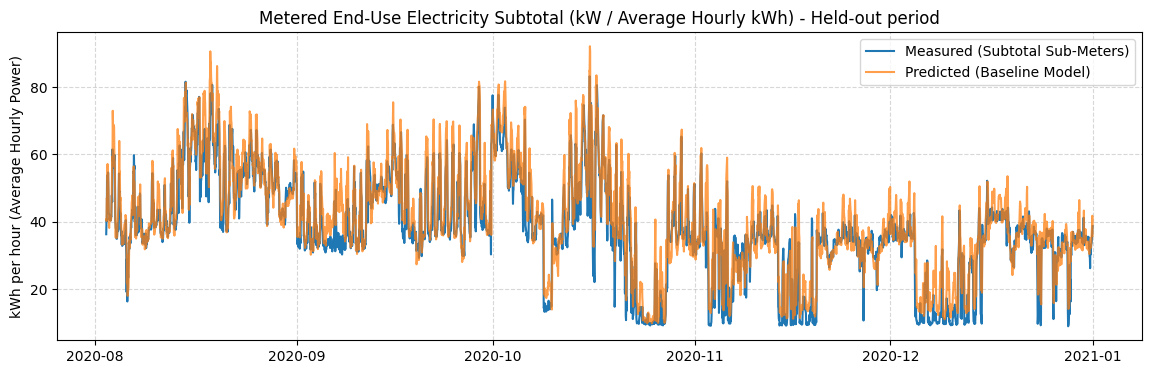

In [19]:
def make_time_features(df):
    idx = pd.DatetimeIndex(df.index)
    X = pd.DataFrame(index=idx)
    X["hour"] = idx.hour
    X["dayofweek"] = idx.dayofweek
    X["month"] = idx.month
    X["dayofyear"] = idx.dayofyear
    X["is_weekend"] = (idx.dayofweek >= 5).astype(int)
    for c in df.columns:
        if re.search(r"outdoor.*temp|outside.*temp|weather.*temp", c, re.I):
            X["outdoor_temperature"] = df[c]
        elif re.search(r"outdoor.*humid|outside.*humid|weather.*humid", c, re.I):
            X["outdoor_humidity"] = df[c]
        elif re.search(r"occup|people", c, re.I):
            X["occupancy_" + c[-24:]] = df[c]
    return X

baseline_model = None
baseline_metrics = None
baseline_predictions = pd.DataFrame()

if BASELINE_READY:
    y = baseline_df["metered_end_use_electricity_subtotal_kwh"].copy()
    X = make_time_features(baseline_df)
    X["lag_1h"] = y.shift(1)
    X["lag_24h"] = y.shift(24)
    X["lag_168h"] = y.shift(168)
    X = X.replace([np.inf, -np.inf], np.nan)
    model_table = X.join(y.rename("target_kwh")).dropna()

    n = len(model_table)
    i_train, i_val = int(n*0.70), int(n*0.85)
    train, val, test = model_table.iloc[:i_train], model_table.iloc[i_train:i_val], model_table.iloc[i_val:]

    params = dict(n_estimators=350 if QUICK_RUN else 900, max_depth=8, learning_rate=0.04,
                  subsample=0.85, colsample_bytree=0.85, reg_lambda=2.0,
                  objective="reg:squarederror", random_state=SEED, n_jobs=-1)
    if GPU_AVAILABLE:
        params.update(tree_method="hist", device="cuda")
    else:
        params.update(tree_method="hist", device="cpu")

    baseline_model = XGBRegressor(**params)
    baseline_model.fit(train.drop(columns="target_kwh"), train["target_kwh"],
                       eval_set=[(val.drop(columns="target_kwh"), val["target_kwh"])], verbose=False)

    pred = baseline_model.predict(test.drop(columns="target_kwh"))
    baseline_metrics = {"MAE_kWh": mean_absolute_error(test["target_kwh"], pred),
                        "RMSE_kWh": mean_squared_error(test["target_kwh"], pred)**0.5,
                        "R2": r2_score(test["target_kwh"], pred), "n_test": len(test),
                        "device": "cuda" if GPU_AVAILABLE else "cpu"}

    baseline_predictions = pd.DataFrame({"actual_kwh": test["target_kwh"], "predicted_kwh": pred}, index=test.index)
    display(pd.DataFrame([baseline_metrics]))
    baseline_predictions.to_csv(OUTPUT_DIR / "baseline_predictions.csv")

    import joblib
    joblib.dump(baseline_model, MODEL_DIR / "xgboost_whole_building_baseline.joblib")

    plt.figure(figsize=(14,4))
    plt.plot(baseline_predictions.index, baseline_predictions.actual_kwh, label="Measured (Subtotal Sub-Meters)")
    plt.plot(baseline_predictions.index, baseline_predictions.predicted_kwh, label="Predicted (Baseline Model)", alpha=.75)
    plt.legend()
    plt.title("Metered End-Use Electricity Subtotal (kW / Average Hourly kWh) - Held-out period")
    plt.ylabel("kWh per hour (Average Hourly Power)")
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.show()
else:
    print("XGBoost baseline skipped: verified subtotal target is not ready.")

## 6. VAE training — sensor anomaly detection

The VAE learns multivariate patterns from measured Building 59 sensors. We use a chronological training/validation/test split and select an anomaly threshold from validation reconstruction errors. A controlled synthetic drift is injected into a copy of the held-out test data to verify that the detector can flag a known perturbation. This is a method-validation test, not proof that all real faults can be diagnosed or corrected.


--- Top 20 Anomalous Timestamps and Feature Contributions ---
Timestamp: 2020-10-14 22:00:00 | Mean Reconstruction Error: 20.6147
  - Feature: rtu_ra_t__rtu_002_ra_temp | Sq Error: 312.5416
  - Feature: rtu_ma_t__rtu_002_ma_temp | Sq Error: 53.4991
  - Feature: rtu_fan_spd__rtu_002_sf_vfd_spd_fbk_tn | Sq Error: 48.4817
Timestamp: 2020-10-14 21:00:00 | Mean Reconstruction Error: 20.1227
  - Feature: rtu_ra_t__rtu_002_ra_temp | Sq Error: 312.4398
  - Feature: rtu_fan_spd__rtu_002_sf_vfd_spd_fbk_tn | Sq Error: 46.4304
  - Feature: rtu_ma_t__rtu_002_ma_temp | Sq Error: 46.3313
Timestamp: 2020-10-15 22:00:00 | Mean Reconstruction Error: 19.4467
  - Feature: rtu_ra_t__rtu_002_ra_temp | Sq Error: 288.0128
  - Feature: rtu_ma_t__rtu_002_ma_temp | Sq Error: 49.3616
  - Feature: rtu_fan_spd__rtu_002_sf_vfd_spd_fbk_tn | Sq Error: 45.9559
Timestamp: 2020-10-14 23:00:00 | Mean Reconstruction Error: 19.2844
  - Feature: rtu_ra_t__rtu_002_ra_temp | Sq Error: 282.1371
  - Feature: rtu_ma_t__rtu_002_m

,epoch,train_loss,val_loss
15,16,0.128618,0.272575
16,17,0.125510,0.267638
17,18,0.122759,0.265965
18,19,0.119940,0.266847
19,20,0.117341,0.273716


,n_features,feature_columns,train_rows,validation_rows,test_rows,threshold_val_99pct,natural_test_flag_rate,synth_drift_det_rate,synth_step_det_rate,synth_spike_det_rate,synth_stuck_det_rate,best_epoch,best_val_loss,device
0,24,"[rtu_fan_spd__rtu_001_sf_vfd_spd_fbk_tn, rtu_f...",18413,3946,3946,0.66663,0.091992,0.223517,0.886467,1.0,0.214901,18,0.265965,cuda


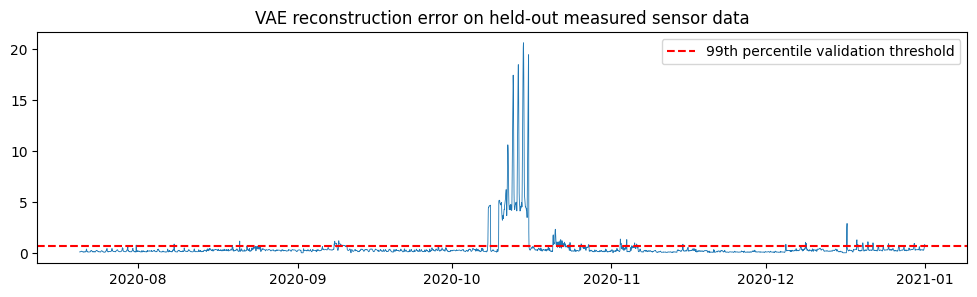

In [20]:
import copy
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

class SensorVAE(nn.Module):
    def __init__(self, n_features, hidden=64, latent=8):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(n_features, hidden),
            nn.ReLU(),
            nn.Linear(hidden, hidden // 2),
            nn.ReLU()
        )
        self.mu = nn.Linear(hidden // 2, latent)
        self.logvar = nn.Linear(hidden // 2, latent)
        self.decoder = nn.Sequential(
            nn.Linear(latent, hidden // 2),
            nn.ReLU(),
            nn.Linear(hidden // 2, hidden),
            nn.ReLU(),
            nn.Linear(hidden, n_features)
        )

    def encode(self, x):
        h = self.encoder(x)
        return self.mu(h), self.logvar(h)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        return mu + torch.randn_like(std) * std

    def forward(self, x, deterministic=False):
        mu, logvar = self.encode(x)
        if deterministic:
            z = mu
        else:
            z = self.reparameterize(mu, logvar)
        return self.decoder(z), mu, logvar

def vae_loss(x, recon, mu, logvar, beta=0.02):
    rec = torch.mean((x - recon) ** 2)
    kl = -0.5 * torch.mean(1 + logvar - mu.pow(2) - logvar.exp())
    return rec + beta * kl, rec.detach(), kl.detach()

vae_model = None
vae_summary = None
vae_anomaly_scores = pd.DataFrame()

if not sensor_hourly.empty:
    if VAE_FEATURES is None:
        numeric_cols = list(sensor_hourly.select_dtypes(include=[np.number]).columns)
        valid_cols = []
        for c in numeric_cols:
            if FEATURE_REGEX.search(c):
                missing_frac = sensor_hourly[c].isna().mean()
                if missing_frac < 0.5:
                    valid_cols.append((c, missing_frac))
        valid_cols = sorted(valid_cols, key=lambda x: x[1])[:MAX_VAE_FEATURES]
        vae_cols = [col for col, _ in valid_cols]
    else:
        vae_cols = VAE_FEATURES

    vae_data = sensor_hourly[vae_cols].copy().replace([np.inf, -np.inf], np.nan)

    n = len(vae_data)
    a = int(n * 0.70)
    b = int(n * 0.85)

    train_df = vae_data.iloc[:a].copy()
    val_df = vae_data.iloc[a:b].copy()
    test_df = vae_data.iloc[b:].copy()

    medians = train_df.median()

    train_imputed = train_df.fillna(medians)
    val_imputed = val_df.fillna(medians)
    test_imputed = test_df.fillna(medians)

    scaler_vae = StandardScaler()
    Xtr = scaler_vae.fit_transform(train_imputed)
    Xva = scaler_vae.transform(val_imputed)
    Xte = scaler_vae.transform(test_imputed)

    if Xtr.shape[1] >= 3 and len(Xtr) >= 100:
        train_loader = DataLoader(TensorDataset(torch.tensor(Xtr, dtype=torch.float32)), batch_size=512, shuffle=True)
        val_tensor = torch.tensor(Xva, dtype=torch.float32, device=DEVICE)
        vae_model = SensorVAE(Xtr.shape[1]).to(DEVICE)
        optimizer = torch.optim.Adam(vae_model.parameters(), lr=1e-3, weight_decay=1e-5)

        history = []
        best_val_loss = float('inf')
        best_epoch = -1
        best_model_weights = None
        patience = 5
        patience_counter = 0

        for epoch in range(VAE_EPOCHS):
            vae_model.train()
            losses = []
            for (xb,) in train_loader:
                xb = xb.to(DEVICE)
                recon, mu, logvar = vae_model(xb)
                loss, _, _ = vae_loss(xb, recon, mu, logvar)
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
                losses.append(float(loss.detach().cpu()))

            vae_model.eval()
            with torch.no_grad():
                r, mu, lv = vae_model(val_tensor, deterministic=True)
                vloss, _, _ = vae_loss(val_tensor, r, mu, lv)

            val_loss_val = float(vloss.cpu())
            history.append({"epoch": epoch + 1, "train_loss": float(np.mean(losses)), "val_loss": val_loss_val})

            if val_loss_val < best_val_loss:
                best_val_loss = val_loss_val
                best_epoch = epoch + 1
                best_model_weights = copy.deepcopy(vae_model.state_dict())
                patience_counter = 0
            else:
                patience_counter += 1
                if patience_counter >= patience:
                    print(f"Early stopping triggered at epoch {epoch + 1}. Restoring best weights from epoch {best_epoch}.")
                    break

        if best_model_weights is not None:
            vae_model.load_state_dict(best_model_weights)

        def reconstruction_error_by_feature(arr):
            vae_model.eval()
            with torch.no_grad():
                t = torch.tensor(arr, dtype=torch.float32, device=DEVICE)
                out, _, _ = vae_model(t, deterministic=True)
                sq_err = (t - out) ** 2
                return sq_err.detach().cpu().numpy()

        val_sq_errors = reconstruction_error_by_feature(Xva)
        val_err = val_sq_errors.mean(axis=1)
        threshold = float(np.quantile(val_err, 0.99))

        test_sq_errors = reconstruction_error_by_feature(Xte)
        test_err = test_sq_errors.mean(axis=1)

        vae_test_idx = test_df.index
        vae_anomaly_scores = pd.DataFrame({"reconstruction_error": test_err, "anomaly_flag": test_err > threshold}, index=vae_test_idx)

        print("\n--- Top 20 Anomalous Timestamps and Feature Contributions ---")
        top20_indices = np.argsort(test_err)[::-1][:20]
        for idx in top20_indices:
            ts = vae_test_idx[idx]
            row_err = test_err[idx]
            feat_errs = test_sq_errors[idx]
            top3_feat_indices = np.argsort(feat_errs)[::-1][:3]
            print(f"Timestamp: {ts} | Mean Reconstruction Error: {row_err:.4f}")
            for f_i in top3_feat_indices:
                print(f"  - Feature: {vae_cols[f_i]} | Sq Error: {feat_errs[f_i]:.4f}")

        # Synthetic Fault Testing
        # 1. Gradual drift (drift_feature_idx increases steadily)
        Xte_drift = Xte.copy()
        drift_feature_idx = 0
        drift_multiplier = np.linspace(0, 4.0, len(Xte_drift))
        Xte_drift[:, drift_feature_idx] += drift_multiplier
        drift_err = reconstruction_error_by_feature(Xte_drift).mean(axis=1)
        det_rate_drift = float(np.mean(drift_err > threshold))

        # 2. Abrupt step shift (+4.0 starting halfway)
        Xte_step = Xte.copy()
        Xte_step[len(Xte_step)//2:, drift_feature_idx] += 4.0
        step_err = reconstruction_error_by_feature(Xte_step).mean(axis=1)
        det_rate_step = float(np.mean(step_err[len(Xte_step)//2:] > threshold))

        # 3. Isolated spikes (+6.0 at randomly chosen 5% of indices)
        Xte_spikes = Xte.copy()
        np.random.seed(SEED)
        spike_indices = np.random.choice(len(Xte_spikes), size=int(len(Xte_spikes)*0.05), replace=False)
        Xte_spikes[spike_indices, drift_feature_idx] += 6.0
        spike_err = reconstruction_error_by_feature(Xte_spikes).mean(axis=1)
        det_rate_spikes = float(np.mean(spike_err[spike_indices] > threshold))

        # 4. Stuck values (stuck at median starting halfway)
        Xte_stuck = Xte.copy()
        stuck_val = float(np.median(Xte[:, drift_feature_idx]))
        Xte_stuck[len(Xte_stuck)//2:, drift_feature_idx] = stuck_val
        stuck_err = reconstruction_error_by_feature(Xte_stuck).mean(axis=1)
        det_rate_stuck = float(np.mean(stuck_err[len(Xte_stuck)//2:] > threshold))

        print("\n--- Selected VAE Features and Missing Fractions ---")
        for col in vae_cols:
            print(f" - {col}: {sensor_hourly[col].isna().mean():.4f} missing")

        print(f"\nBest Training Epoch: {best_epoch} | Best Validation Loss: {best_val_loss:.6f}")
        print(f"Train Rows: {len(Xtr)} | Val Rows: {len(Xva)} | Test Rows: {len(Xte)}")
        print(f"Validation Threshold: {threshold:.6f}")
        print(f"Natural Test Anomaly Rate: {float(vae_anomaly_scores.anomaly_flag.mean()):.4%}")
        print("\n--- Synthetic Stress Test Detection Rates (Labeled Synthetic) ---")
        print(f" - Scenario 1 (Gradual Drift): {det_rate_drift:.4%}")
        print(f" - Scenario 2 (Abrupt Step Shift): {det_rate_step:.4%}")
        print(f" - Scenario 3 (Isolated Spikes): {det_rate_spikes:.4%}")
        print(f" - Scenario 4 (Stuck Sensor Values): {det_rate_stuck:.4%}")

        vae_summary = {
            "n_features": int(Xtr.shape[1]),
            "feature_columns": list(vae_cols),
            "train_rows": len(Xtr),
            "validation_rows": len(Xva),
            "test_rows": len(Xte),
            "threshold_val_99pct": threshold,
            "natural_test_flag_rate": float(vae_anomaly_scores.anomaly_flag.mean()),
            "synth_drift_det_rate": det_rate_drift,
            "synth_step_det_rate": det_rate_step,
            "synth_spike_det_rate": det_rate_spikes,
            "synth_stuck_det_rate": det_rate_stuck,
            "best_epoch": best_epoch,
            "best_val_loss": best_val_loss,
            "device": DEVICE
        }

        display(pd.DataFrame(history).tail())
        display(pd.DataFrame([vae_summary]))

        vae_anomaly_scores.to_csv(OUTPUT_DIR / "vae_anomaly_scores.csv")
        torch.save({
            "state_dict": vae_model.state_dict(),
            "features": list(vae_cols),
            "scaler_mean": scaler_vae.mean_.tolist(),
            "scaler_scale": scaler_vae.scale_.tolist(),
            "threshold": threshold
        }, MODEL_DIR / "building59_sensor_vae.pt")

        plt.figure(figsize=(12, 3))
        plt.plot(vae_anomaly_scores.index, vae_anomaly_scores.reconstruction_error, lw=.6)
        plt.axhline(threshold, color="red", ls="--", label="99th percentile validation threshold")
        plt.legend()
        plt.title("VAE reconstruction error on held-out measured sensor data")
        plt.show()
    else:
        print("VAE skipped: insufficient rows or columns for training. Check data inventory.")
else:
    print("VAE skipped: Building 59 sensor table not available.")

In [21]:
# VAE anomaly investigation - diagnostic only

vae_model.eval()

with torch.no_grad():
    x_tensor = torch.tensor(
        Xte, dtype=torch.float32, device=DEVICE
    )
    reconstructed, _, _ = vae_model(
        x_tensor, deterministic=True
    )
    feature_errors = (
        (x_tensor - reconstructed) ** 2
    ).cpu().numpy()

# Identify 20 highest-error timestamps
top_positions = np.argsort(test_err)[-20:][::-1]

rows = []

for pos in top_positions:
    top_features = np.argsort(feature_errors[pos])[-3:][::-1]

    rows.append({
        "timestamp": test_df.index[pos],
        "total_reconstruction_error": float(test_err[pos]),
        "top_feature_1": vae_cols[top_features[0]],
        "error_1": float(feature_errors[pos, top_features[0]]),
        "top_feature_2": vae_cols[top_features[1]],
        "error_2": float(feature_errors[pos, top_features[1]]),
        "top_feature_3": vae_cols[top_features[2]],
        "error_3": float(feature_errors[pos, top_features[2]])
    })

anomaly_details = pd.DataFrame(rows)

display(anomaly_details)

anomaly_details.to_csv(
    OUTPUT_DIR / "vae_top_20_anomalies.csv",
    index=False
)

,timestamp,total_reconstruction_error,top_feature_1,error_1,top_feature_2,error_2,top_feature_3,error_3
0,2020-10-14 22:00:00,20.614704,rtu_ra_t__rtu_002_ra_temp,312.541595,rtu_ma_t__rtu_002_ma_temp,53.499062,rtu_fan_spd__rtu_002_sf_vfd_spd_fbk_tn,48.481720
1,2020-10-14 21:00:00,20.122698,rtu_ra_t__rtu_002_ra_temp,312.439850,rtu_fan_spd__rtu_002_sf_vfd_spd_fbk_tn,46.430351,rtu_ma_t__rtu_002_ma_temp,46.331329
2,2020-10-15 22:00:00,19.446653,rtu_ra_t__rtu_002_ra_temp,288.012787,rtu_ma_t__rtu_002_ma_temp,49.361561,rtu_fan_spd__rtu_002_sf_vfd_spd_fbk_tn,45.955906
3,2020-10-14 23:00:00,19.284433,rtu_ra_t__rtu_002_ra_temp,282.137115,rtu_ma_t__rtu_002_ma_temp,54.307331,rtu_fan_spd__rtu_002_sf_vfd_spd_fbk_tn,48.501080
4,2020-10-13 22:00:00,18.475660,rtu_ra_t__rtu_002_ra_temp,277.206116,rtu_fan_spd__rtu_002_sf_vfd_spd_fbk_tn,45.532913,rtu_ma_t__rtu_002_ma_temp,44.479740
5,2020-10-15 21:00:00,18.421329,rtu_ra_t__rtu_002_ra_temp,272.548859,rtu_fan_spd__rtu_002_sf_vfd_spd_fbk_tn,45.388184,rtu_ma_t__rtu_002_ma_temp,41.410717
6,2020-10-14 20:00:00,17.938562,rtu_ra_t__rtu_002_ra_temp,275.223480,rtu_fan_spd__rtu_002_sf_vfd_spd_fbk_tn,44.874828,rtu_ma_t__rtu_002_ma_temp,35.178318
7,2020-10-13 21:00:00,17.636011,rtu_ra_t__rtu_002_ra_temp,270.027954,rtu_fan_spd__rtu_002_sf_vfd_spd_fbk_tn,43.035324,rtu_ma_t__rtu_002_ma_temp,36.742992
8,2020-10-12 22:00:00,17.441999,rtu_ra_t__rtu_002_ra_temp,256.337158,rtu_fan_spd__rtu_002_sf_vfd_spd_fbk_tn,43.705200,rtu_ma_t__rtu_002_ma_temp,40.123356
9,2020-10-13 23:00:00,17.151686,rtu_ra_t__rtu_002_ra_temp,242.518890,rtu_ma_t__rtu_002_ma_temp,46.819275,rtu_fan_spd__rtu_002_sf_vfd_spd_fbk_tn,46.410084


## 7. Optional BDG2 cross-building data acquisition

BDG2 is a separate measured dataset and must not be concatenated with Building 59 rows. This optional block downloads cleaned electricity meter data, building metadata and weather from the public Git-LFS repository. It can be used to check whether the whole-building baseline generalizes across building types. Construction-year metadata may be missing or incomplete; do not call a building “legacy” unless year built has been verified.

In [22]:
BDG2_DIR = DATA_DIR / "bdg2"
if DOWNLOAD_BDG2:
    subprocess.run(["apt-get","-qq","update"], check=False)
    subprocess.run(["apt-get","-qq","install","-y","git-lfs"], check=False)
    subprocess.run(["git","lfs","install"], check=False)
    if not BDG2_DIR.exists():
        env=os.environ.copy(); env["GIT_LFS_SKIP_SMUDGE"]="1"
        subprocess.run(["git","clone","--depth","1","https://github.com/buds-lab/building-data-genome-project-2.git",str(BDG2_DIR)],check=True,env=env)
    include=",".join(["data/meters/cleaned/electricity_cleaned.csv","data/metadata/metadata.csv","data/weather/weather.csv"])
    subprocess.run(["git","-C",str(BDG2_DIR),"lfs","pull","--include",include],check=True)
    for p in [BDG2_DIR/"data/meters/cleaned/electricity_cleaned.csv",BDG2_DIR/"data/metadata/metadata.csv",BDG2_DIR/"data/weather/weather.csv"]:
        if not p.exists() or p.stat().st_size < 1000:
            raise FileNotFoundError(f"BDG2 file missing or Git-LFS pointer not downloaded: {p}")
        print(p.name, round(p.stat().st_size/1e6,1),"MB")
else:
    print("BDG2 download skipped. Enable DOWNLOAD_BDG2=True to run the optional multi-building benchmark.")

BDG2 download skipped. Enable DOWNLOAD_BDG2=True to run the optional multi-building benchmark.


## 8. Download Surat EPW weather and prepare a legacy EnergyPlus model

The notebook attempts to find a recent Surat TMYx ZIP in the Climate.OneBuilding Gujarat directory. If that fails, upload an EPW manually. You must also upload a **DOE pre-1980 reference building** model (prefer medium office for the first run). The DOE reference models are complete whole-building EnergyPlus descriptions for pre-1980 construction; they are simulated archetypes, not observations.

In [23]:
EPW_DIR = DATA_DIR / "weather"
EPW_DIR.mkdir(parents=True, exist_ok=True)
EPW_PATH = None

# Reuse files from an earlier run of this same Colab runtime, if present.
if not CUSTOM_BUILDING_FILE:
    for candidate in [DATA_DIR/"legacy_building.epJSON", DATA_DIR/"legacy_building.idf"]:
        if candidate.exists():
            CUSTOM_BUILDING_FILE = str(candidate)
            break

if DOWNLOAD_SURAT_EPW:
    try:
        from bs4 import BeautifulSoup
        directory_url = "https://climate.onebuilding.org/WMO_Region_2_Asia/IND_India/GJ_Gujarat/"
        page = requests.get(directory_url, timeout=60, headers={"User-Agent":"Mozilla/5.0"})
        page.raise_for_status()
        soup = BeautifulSoup(page.text, "html.parser")
        links = [a.get("href") for a in soup.find_all("a") if a.get("href")]
        choices = [u for u in links if "IND_GJ_Surat" in u and "TMYx" in u and u.lower().endswith(".zip")]
        if not choices:
            raise FileNotFoundError("No Surat TMYx ZIP link found in the directory page.")
        chosen = sorted(choices, key=lambda u: ("2009-2023" not in u, u))[0]
        weather_url = chosen if chosen.startswith("http") else requests.compat.urljoin(directory_url, chosen)
        weather_zip = EPW_DIR / Path(chosen).name
        if not weather_zip.exists() or weather_zip.stat().st_size < 1000:
            stream_download(weather_url, weather_zip)
        extract_dir = EPW_DIR/"surat_tmyx"
        extract_dir.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(weather_zip) as zf:
            zf.extractall(extract_dir)
        epws = list(extract_dir.rglob("*.epw"))
        if epws:
            EPW_PATH = str(epws[0])
            print("Surat EPW:", EPW_PATH)
    except Exception as e:
        print("Automatic Surat EPW download did not complete:", repr(e))
        print("Upload an EPW file manually if required.")
else:
    print("Automatic EPW download disabled.")

# Do not reopen the upload dialog if the model file is already present.
model_exists = bool(CUSTOM_BUILDING_FILE and Path(CUSTOM_BUILDING_FILE).exists())
if not model_exists:
    try:
        from google.colab import files
        print("Upload one EnergyPlus building model (.idf or .epJSON). The EPW is optional if Surat EPW was downloaded.")
        uploaded = files.upload()
        for fn in uploaded:
            src_path = Path("/content")/fn
            if fn.lower().endswith((".epjson", ".json")):
                dst = DATA_DIR/"legacy_building.epJSON"
                shutil.copy2(src_path, dst)
                CUSTOM_BUILDING_FILE = str(dst)
            elif fn.lower().endswith(".idf"):
                dst = DATA_DIR/"legacy_building.idf"
                shutil.copy2(src_path, dst)
                CUSTOM_BUILDING_FILE = str(dst)
            elif fn.lower().endswith(".epw"):
                dst = EPW_DIR/Path(fn).name
                shutil.copy2(src_path, dst)
                EPW_PATH = str(dst)
    except Exception as e:
        print("Colab upload not available in this runtime:", repr(e))
else:
    print("Reusing previously uploaded model:", CUSTOM_BUILDING_FILE)

if CUSTOM_WEATHER_FILE and Path(CUSTOM_WEATHER_FILE).exists():
    EPW_PATH = CUSTOM_WEATHER_FILE
if EPW_PATH:
    print("Selected EPW:", EPW_PATH)
else:
    print("No EPW selected. EnergyPlus simulation will remain gated until an EPW is supplied.")
print("Building model file:", CUSTOM_BUILDING_FILE)


Surat EPW: /content/whole_building_retrofit_full/data/weather/surat_tmyx/IND_GJ_Surat.428400_TMYx.2009-2023.epw
Reusing previously uploaded model: /content/whole_building_retrofit_full/data/legacy_building.idf
Selected EPW: /content/whole_building_retrofit_full/data/weather/surat_tmyx/IND_GJ_Surat.428400_TMYx.2009-2023.epw
Building model file: /content/whole_building_retrofit_full/data/legacy_building.idf


### EnergyPlus / Sinergym version note

The uploaded `MediumOffice.idf` is saved successfully by the upload cell. The earlier notebook message that asked for another upload was misleading: Python 3.13 caused the previous Cell 23 guard to skip EnergyPlus installation entirely. The revised Cell 23 attempts EnergyPlus 25.1.0 installation and Sinergym 3.12.2 (whose PyPI metadata requires Python >=3.12), then performs import/version smoke tests. Sinergym's published compatibility table has a specifically tested row for Python 3.12.3, Ubuntu 24.04 and EnergyPlus 25.1.0; a successful install on Python 3.13 must still pass the environment reset test before research use. See [Sinergym installation compatibility](https://ugr-sail.github.io/sinergym/compilation/main/pages/installation.html) and [Sinergym 3.12.2 on PyPI](https://pypi.org/project/sinergym/3.12.2/).

**Important:** EnergyPlus `--convert-only` changes IDF ↔ epJSON format; it does not upgrade an old model version. Use the EnergyPlus IDF Version Updater / transition utility to update the uploaded Version 9.3 IDF to 25.1 first. The EnergyPlus 25.1 documentation describes the updater and its supported transition from Version 7.2 to current. Then use `--convert-only` to create epJSON. [Version updating](https://docs.idfkit.com/v25.1/essentials/using-energyplus/versions-and-updating/) · [IDF Version Updater](https://docs.idfkit.com/v25.1/auxiliary-programs/using-older-version-input-files-transition/idf-version-updater/).


In [24]:
import sys
import platform
import subprocess
import importlib.metadata as importlib_metadata
from pathlib import Path

EPLUS_READY = False
SINERGYM_READY = False
EPLUS_PATH = None
EPLUS_VERSION_TEXT = None
SINERGYM_VERSION_INSTALLED = None

print("========== PIPELINE PLATFORM CHECK ==========")
print("Python version:", sys.version.split()[0])
print("Platform:", platform.platform())
print("Architecture:", platform.machine())

# --- 1. Install & Configure EnergyPlus 25.1.0 ---
if platform.machine().lower() not in {"x86_64", "amd64"}:
    print("Architecture mismatch: EnergyPlus installation targets Linux x86_64.")
else:
    eplus_tar_url = "https://github.com/NatLabRockies/EnergyPlus/releases/download/v25.1.0-WithDSOASpaceListFixes/EnergyPlus-25.1.0-1c11a3d85f-Linux-Ubuntu22.04-x86_64.tar.gz"
    eplus_tar = ENERGYPLUS_DIR / "EnergyPlus-25.1.0-Linux-Ubuntu22.04-x86_64.tar.gz"
    extract_dir = ENERGYPLUS_DIR / "extracted"
    try:
        if not eplus_tar.exists() or eplus_tar.stat().st_size < 10_000_000:
            stream_download(eplus_tar_url, eplus_tar)
        extract_dir.mkdir(parents=True, exist_ok=True)
        bins = [p for p in extract_dir.rglob("energyplus") if p.is_file() and os.access(p, os.X_OK)]
        if not bins:
            subprocess.run(["tar", "-xzf", str(eplus_tar), "-C", str(extract_dir)], check=True)
            bins = [p for p in extract_dir.rglob("energyplus") if p.is_file() and os.access(p, os.X_OK)]
        if not bins:
            raise FileNotFoundError("EnergyPlus executable not found in extracted directory.")

        eplus_bin = bins[0]
        EPLUS_PATH = str(eplus_bin.parent)
        os.environ["EPLUS_PATH"] = EPLUS_PATH
        os.environ["ENERGYPLUS_HOME"] = EPLUS_PATH
        os.environ["PYTHONPATH"] = EPLUS_PATH + os.pathsep + os.environ.get("PYTHONPATH", "")
        os.environ["LD_LIBRARY_PATH"] = EPLUS_PATH + os.pathsep + os.environ.get("LD_LIBRARY_PATH", "")
        if EPLUS_PATH not in sys.path:
            sys.path.insert(0, EPLUS_PATH)

        ver = subprocess.run([str(eplus_bin), "--version"], capture_output=True, text=True)
        EPLUS_VERSION_TEXT = (ver.stdout + "\n" + ver.stderr).strip()
        print("EnergyPlus version output:\n", EPLUS_VERSION_TEXT)
        if ver.returncode == 0 and "25.1.0" in EPLUS_VERSION_TEXT:
            EPLUS_READY = True
            print("EnergyPlus installation validation: PASSED")
        else:
            print("EnergyPlus validation failed during check.")
    except Exception as e:
        print("EnergyPlus configuration failed:", repr(e))

# --- 2. Sinergym Setup Postponed ---
print("Sinergym installation postponed. EnergyPlus standalone testing will proceed first.")
SINERGYM_READY = False

print("\n========== ENVIRONMENT STATUS ==========")
print("EPLUS_READY:", EPLUS_READY)
print("SINERGYM_READY:", SINERGYM_READY)
print("========================================")

========== PIPELINE PLATFORM CHECK ==========
Python version: 3.13.16
Platform: Linux-6.6.159+-x86_64-with-glibc2.39
Architecture: x86_64
EnergyPlus version output:
 EnergyPlus, Version 25.1.0-1c11a3d85f
EnergyPlus installation validation: PASSED
Sinergym installation postponed. EnergyPlus standalone testing will proceed first.

========== ENVIRONMENT STATUS ==========
EPLUS_READY: True
SINERGYM_READY: False


## 9. Convert / validate the uploaded building model using official Version Updater

In [25]:
from pathlib import Path
import os

eplus_root = Path(EPLUS_PATH)

transition_dir = (
    eplus_root / "PreProcess" / "IDFVersionUpdater"
)

print("EnergyPlus root:", eplus_root)
print("Transition directory:", transition_dir)
print("Directory exists:", transition_dir.exists())

if transition_dir.exists():
    print("\n--- FILES INSIDE TRANSITION DIRECTORY ---")

    for p in sorted(transition_dir.rglob("*")):
        if p.is_file():
            print(
                p.name,
                "| Executable:", os.access(p, os.X_OK),
                "| Size:", p.stat().st_size
            )
else:
    print("IDF Version Updater directory not found.")

EnergyPlus root: /content/whole_building_retrofit_full/energyplus/extracted/EnergyPlus-25.1.0-1c11a3d85f-Linux-Ubuntu22.04-x86_64
Transition directory: /content/whole_building_retrofit_full/energyplus/extracted/EnergyPlus-25.1.0-1c11a3d85f-Linux-Ubuntu22.04-x86_64/PreProcess/IDFVersionUpdater
Directory exists: True

--- FILES INSIDE TRANSITION DIRECTORY ---
Energy+.ini | Executable: False | Size: 271
OutputChanges22-1-0-to-22-2-0.md | Executable: False | Size: 6211
OutputChanges22-2-0-to-23-1-0.md | Executable: False | Size: 722
OutputChanges23-1-0-to-23-2-0.md | Executable: False | Size: 5552
OutputChanges23-2-0-to-24-1-0.md | Executable: False | Size: 580
OutputChanges24-1-0-to-24-2-0.md | Executable: False | Size: 5402
OutputChanges24-2-0-to-25-1-0.md | Executable: False | Size: 3652
OutputChanges9-0-0-to-9-1-0.md | Executable: False | Size: 998
OutputChanges9-1-0-to-9-2-0.md | Executable: False | Size: 1960
OutputChanges9-2-0-to-9-3-0.md | Executable: False | Size: 10897
OutputChan

In [26]:

# TEST ONE ENERGYPLUS TRANSITION ONLY

import subprocess
import shutil
import time
from pathlib import Path

updater_dir = (
    Path(EPLUS_PATH)
    / "PreProcess"
    / "IDFVersionUpdater"
)

original_idf = Path(CUSTOM_BUILDING_FILE)

binary = updater_dir / "Transition-V9-3-0-to-V9-4-0"

probe_dir = DATA_DIR / "transition_probe"

if probe_dir.exists():
    shutil.rmtree(probe_dir)

probe_dir.mkdir(parents=True)

probe_idf = probe_dir / "probe.idf"
shutil.copy2(original_idf, probe_idf)

assert binary.exists(), f"Missing executable: {binary}"
assert original_idf.exists(), "Original IDF missing"

print("Original IDF:", original_idf)
print("Transition executable:", binary)
print("Executable permission:", binary.stat().st_mode)

start_time = time.time()

try:
    result = subprocess.run(
        [str(binary), str(probe_idf)],
        cwd=str(updater_dir),
        capture_output=True,
        text=True,
        timeout=120
    )

    print("\nRETURN CODE:", result.returncode)
    print("\n--- STDOUT ---")
    print(result.stdout[-8000:])

    print("\n--- STDERR ---")
    print(result.stderr[-8000:])

except subprocess.TimeoutExpired:
    print("TRANSITION TIMED OUT")

print("\n--- GENERATED FILES ---")

for folder in [probe_dir, updater_dir]:
    for p in folder.iterdir():
        if p.is_file() and p.stat().st_mtime >= start_time:
            print(p.name, "|", p.stat().st_size, "bytes")

print("\n--- IDF VERSION CHECK ---")

import re

for p in probe_dir.glob("*.idf*"):
    if p.is_file():
        content = p.read_text(errors="replace")
        match = re.search(
            r"(?im)^\s*Version\s*,\s*([^;]+);",
            content
        )
        print(p.name, "VERSION:", match.group(1).strip()
              if match else "NOT DETECTED")


Original IDF: /content/whole_building_retrofit_full/data/legacy_building.idf
Transition executable: /content/whole_building_retrofit_full/energyplus/extracted/EnergyPlus-25.1.0-1c11a3d85f-Linux-Ubuntu22.04-x86_64/PreProcess/IDFVersionUpdater/Transition-V9-3-0-to-V9-4-0
Executable permission: 33261

RETURN CODE: 0

--- STDOUT ---
 Transition Starting
 Conversion 9.3 => 9.4
 Processing Old IDD -- V9-3-0-Energy+.idd
 Processing New IDD -- V9-4-0-Energy+.idd
 Will create new full IDFs
 Will create new IDF lines with units where applicable
 Will create new IDF lines leaving blank incoming fields as blank (no default fill)
 F
 Processing IDF -- /content/whole_building_retrofit_full/data/transition_probe/probe.idf
 Processing IDF -- Processing idf objects . . .
 Processing IDF -- Processing idf objects complete.


--- STDERR ---


--- GENERATED FILES ---
probe.idf | 383767 bytes
probe.idfnew | 383767 bytes
probe.idfold | 383582 bytes
Transition.audit | 308 bytes

--- IDF VERSION CHECK ---
pro

In [27]:

import subprocess
import os
import json
import shutil
import re
from pathlib import Path
import pandas as pd

LEGACY_EPJSON_PATH = None
MODEL_IS_VERIFIED_LEGACY = False
MODEL_VINTAGE_DOCUMENTATION_VERIFIED = False

MODEL_METADATA = {
    "model_source": "Uploaded_MediumOffice_IDF",
    "file_status": "CONVERSION_NOT_STARTED",
    "detected_input_version": None,
    "final_idf_version": None,
    "construction_vintage": "POST_1980",
    "legacy_status": "UNVERIFIED_POST1980"
}


def get_idf_version(file_path):
    """Read the IDF Version object."""
    path = Path(file_path)

    if not path.exists():
        return None

    content = path.read_text(
        encoding="utf-8",
        errors="replace"
    )

    match = re.search(
        r"(?im)^\s*Version\s*,\s*([^;]+)\s*;",
        content
    )

    return match.group(1).strip() if match else None


def normalize_version(version):
    """Convert 9.3 or 9.3.0 to (9, 3, 0)."""
    if not version:
        return None

    nums = [int(x) for x in re.findall(r"\d+", version)[:3]]

    while len(nums) < 3:
        nums.append(0)

    return tuple(nums)


# Official sequential transition chain
TRANSITIONS = {
    (9, 3, 0): (9, 4, 0),
    (9, 4, 0): (9, 5, 0),
    (9, 5, 0): (9, 6, 0),
    (9, 6, 0): (22, 1, 0),
    (22, 1, 0): (22, 2, 0),
    (22, 2, 0): (23, 1, 0),
    (23, 1, 0): (23, 2, 0),
    (23, 2, 0): (24, 1, 0),
    (24, 1, 0): (24, 2, 0),
    (24, 2, 0): (25, 1, 0)
}


def version_token(version_tuple):
    return "-".join(str(x) for x in version_tuple)


def transition_and_convert_idf(eplus_dir, idf_path, output_dir):

    eplus_dir = Path(eplus_dir)
    idf_path = Path(idf_path)
    output_dir = Path(output_dir)

    updater_dir = (
        eplus_dir / "PreProcess" / "IDFVersionUpdater"
    )

    eplus_bin = eplus_dir / "energyplus"

    # Validate prerequisites
    if not idf_path.is_file():
        raise FileNotFoundError(f"IDF not found: {idf_path}")

    if not updater_dir.is_dir():
        raise FileNotFoundError(
            f"Updater directory not found: {updater_dir}"
        )

    if not eplus_bin.is_file():
        raise FileNotFoundError(
            f"EnergyPlus executable not found: {eplus_bin}"
        )

    source_version = get_idf_version(idf_path)
    source_tuple = normalize_version(source_version)

    print("Source IDF version:", source_version)

    MODEL_METADATA["detected_input_version"] = source_version

    if source_tuple is None:
        raise RuntimeError("Could not identify source IDF version.")

    if source_tuple == (25, 1, 0):
        print("Input already uses version 25.1.0.")
        final_idf_source = idf_path

    else:
        if source_tuple not in TRANSITIONS:
            raise RuntimeError(
                f"No configured transition sequence from {source_version}"
            )

        # Fresh workspace; original uploaded IDF is never modified.
        workspace = output_dir / "transition_workspace"

        if workspace.exists():
            shutil.rmtree(workspace)

        workspace.mkdir(parents=True)

        current_idf_source = idf_path
        current_tuple = source_tuple

        step_number = 0

        print("\nStarting sequential IDF transition.")
        print("IMPORTANT: Transition executables run from updater_dir.")

        while current_tuple != (25, 1, 0):

            if current_tuple not in TRANSITIONS:
                raise RuntimeError(
                    f"No next transition defined for {current_tuple}"
                )

            next_tuple = TRANSITIONS[current_tuple]

            start_token = version_token(current_tuple)
            end_token = version_token(next_tuple)

            binary_name = (
                f"Transition-V{start_token}-to-V{end_token}"
            )

            binary = updater_dir / binary_name

            old_idd = updater_dir / f"V{start_token}-Energy+.idd"
            new_idd = updater_dir / f"V{end_token}-Energy+.idd"

            if not binary.is_file():
                raise FileNotFoundError(
                    f"Transition executable missing: {binary}"
                )

            if not old_idd.is_file() or not new_idd.is_file():
                raise FileNotFoundError(
                    f"Required IDD missing for {binary_name}: "
                    f"{old_idd.name} or {new_idd.name}"
                )

            if not os.access(binary, os.X_OK):
                raise PermissionError(
                    f"Transition binary is not executable: {binary}"
                )

            step_number += 1

            step_dir = workspace / f"step_{step_number:02d}"
            step_dir.mkdir()

            step_input = step_dir / "transition_input.idf"
            shutil.copy2(current_idf_source, step_input)

            print(
                f"\nSTEP {step_number}: "
                f"{current_tuple} -> {next_tuple}"
            )
            print("Executable:", binary_name)
            print("Working directory:", updater_dir)

            # CRITICAL FIX:
            # cwd MUST be updater_dir because the transition binary
            # looks for its IDD files by relative filename.
            result = subprocess.run(
                [str(binary), str(step_input)],
                cwd=str(updater_dir),
                capture_output=True,
                text=True,
                timeout=300
            )

            # Preserve each step's diagnostics.
            (step_dir / "stdout.txt").write_text(
                result.stdout or "",
                encoding="utf-8"
            )

            (step_dir / "stderr.txt").write_text(
                result.stderr or "",
                encoding="utf-8"
            )

            audit_source = updater_dir / "Transition.audit"

            if audit_source.exists():
                shutil.copy2(
                    audit_source,
                    step_dir / "Transition.audit"
                )

            print("--- STDOUT ---")
            print((result.stdout or "")[-3000:])

            if result.stderr:
                print("--- STDERR ---")
                print(result.stderr[-3000:])

            print("Return code:", result.returncode)

            if result.returncode != 0:
                raise RuntimeError(
                    f"{binary_name} failed with exit code "
                    f"{result.returncode}. Inspect {step_dir}"
                )

            # Check actual output versions instead of assuming
            # the generated filename.
            candidates = [
                step_input,
                Path(str(step_input) + "new")
            ]

            valid_candidates = []

            for candidate in candidates:
                if candidate.is_file():
                    detected = get_idf_version(candidate)

                    print(
                        candidate.name,
                        "version:",
                        detected
                    )

                    if normalize_version(detected) == next_tuple:
                        valid_candidates.append(candidate)

            if not valid_candidates:
                raise RuntimeError(
                    f"{binary_name} returned code 0, "
                    f"but no output IDF with expected version "
                    f"{next_tuple} was found. "
                    f"Inspect {step_dir}"
                )

            # Prefer the primary transitioned IDF if it was
            # updated in-place. Otherwise use the .idfnew file.
            accepted = valid_candidates[0]

            accepted_copy = step_dir / "accepted_transition.idf"
            shutil.copy2(accepted, accepted_copy)

            current_idf_source = accepted_copy
            current_tuple = normalize_version(
                get_idf_version(current_idf_source)
            )

            print("Transition verified:", current_tuple)

        final_idf_source = current_idf_source

    # Final IDF version verification
    final_version = get_idf_version(final_idf_source)

    if normalize_version(final_version) != (25, 1, 0):
        raise RuntimeError(
            f"Final IDF version is {final_version}, not 25.1.0."
        )

    print("\nAll transitions completed.")
    print("Final IDF version:", final_version)

    # Copy final IDF into workspace for conversion.
    workspace = output_dir / "transition_workspace"
    workspace.mkdir(parents=True, exist_ok=True)

    final_idf = workspace / "mediumoffice_energyplus_25_1.idf"
    shutil.copy2(final_idf_source, final_idf)

    # Convert actual transitioned IDF to epJSON.
    print("\nConverting IDF to epJSON...")

    conversion = subprocess.run(
        [
            str(eplus_bin),
            "--convert-only",
            str(final_idf)
        ],
        cwd=str(workspace),
        capture_output=True,
        text=True,
        timeout=300
    )

    print(conversion.stdout[-5000:])

    if conversion.stderr:
        print("Conversion stderr:")
        print(conversion.stderr[-5000:])

    if conversion.returncode != 0:
        raise RuntimeError(
            "EnergyPlus IDF-to-epJSON conversion failed: "
            + (conversion.stderr or conversion.stdout)
        )

    # Find the actual generated epJSON.
    json_candidates = sorted(
        workspace.glob("*.epJSON"),
        key=lambda p: p.stat().st_mtime,
        reverse=True
    )

    if not json_candidates:
        raise FileNotFoundError(
            "EnergyPlus completed conversion but no epJSON was found."
        )

    converted_json = json_candidates[0]

    # Validate JSON structure.
    with open(converted_json, "r", encoding="utf-8") as f:
        model_data = json.load(f)

    zones = model_data.get("Zone", {})

    if not isinstance(zones, dict) or not zones:
        raise RuntimeError(
            "Converted epJSON contains no valid Zone objects."
        )

    # Do not label this post-1980 model as a legacy building.
    final_epjson = (
        output_dir / "mediumoffice_energyplus_25_1.epJSON"
    )

    shutil.copy2(converted_json, final_epjson)

    MODEL_METADATA.update({
        "file_status": "CONVERTED_EPJSON_READY",
        "final_idf_version": final_version,
        "construction_vintage": "POST_1980",
        "legacy_status": "NOT_A_LEGACY_BUILDING",
        "zone_count": len(zones),
        "zones_preview": list(zones.keys())[:10]
    })

    return str(final_epjson)


# ------------------------------------------------------------
# EXECUTE
# ------------------------------------------------------------

try:

    if not EPLUS_READY:
        raise RuntimeError("EnergyPlus is not ready.")

    if not CUSTOM_BUILDING_FILE:
        raise RuntimeError("CUSTOM_BUILDING_FILE is not configured.")

    if not Path(CUSTOM_BUILDING_FILE).is_file():
        raise FileNotFoundError(
            f"Uploaded model not found: {CUSTOM_BUILDING_FILE}"
        )

    if not Path(EPLUS_PATH, "energyplus").is_file():
        raise FileNotFoundError("EnergyPlus binary not found.")

    print("Processing actual uploaded model:")
    print(CUSTOM_BUILDING_FILE)

    LEGACY_EPJSON_PATH = transition_and_convert_idf(
        EPLUS_PATH,
        CUSTOM_BUILDING_FILE,
        DATA_DIR
    )

    # Compatibility variable retained for downstream cells.
    # This does NOT mean the model is pre-1980.
    MODEL_IS_VERIFIED_LEGACY = False
    MODEL_VINTAGE_DOCUMENTATION_VERIFIED = False

    print("\nMODEL CONVERSION SUCCESSFUL")
    print("epJSON path:", LEGACY_EPJSON_PATH)
    print("Legacy verification:", MODEL_IS_VERIFIED_LEGACY)

    display(pd.DataFrame([MODEL_METADATA]))

except Exception as e:

    LEGACY_EPJSON_PATH = None
    MODEL_IS_VERIFIED_LEGACY = False

    MODEL_METADATA["file_status"] = "CONVERSION_FAILED"

    print("\nMODEL CONVERSION FAILED")
    print(type(e).__name__, str(e))

    raise


Processing actual uploaded model:
/content/whole_building_retrofit_full/data/legacy_building.idf
Source IDF version: 9.3

Starting sequential IDF transition.
IMPORTANT: Transition executables run from updater_dir.

STEP 1: (9, 3, 0) -> (9, 4, 0)
Executable: Transition-V9-3-0-to-V9-4-0
Working directory: /content/whole_building_retrofit_full/energyplus/extracted/EnergyPlus-25.1.0-1c11a3d85f-Linux-Ubuntu22.04-x86_64/PreProcess/IDFVersionUpdater
--- STDOUT ---
 Transition Starting
 Conversion 9.3 => 9.4
 Processing Old IDD -- V9-3-0-Energy+.idd
 Processing New IDD -- V9-4-0-Energy+.idd
 Will create new full IDFs
 Will create new IDF lines with units where applicable
 Will create new IDF lines leaving blank incoming fields as blank (no default fill)
 F
 Processing IDF -- /content/whole_building_retrofit_full/data/transition_workspace/step_01/transition_input.idf
 Processing IDF -- Processing idf objects . . .
 Processing IDF -- Processing idf objects complete.

Return code: 0
transition_in

,model_source,file_status,detected_input_version,final_idf_version,construction_vintage,legacy_status,zone_count,zones_preview
0,Uploaded_MediumOffice_IDF,CONVERTED_EPJSON_READY,9.3,25.1,POST_1980,NOT_A_LEGACY_BUILDING,18,"[Core_bottom, Core_mid, Core_top, FirstFloor_P..."


## 10. Add whole-building output meters and discover retrofit actuators

The simulator will request whole-facility electricity and common end-use meters (HVAC, interior lighting, interior equipment). Actual available meter names must be checked in EnergyPlus output files. The code discovers thermostat setpoint schedules and lighting schedules in the supplied model. It does not silently claim to control ventilation if the model has no corresponding actuator; an optional ventilation schedule name can be mapped manually.

In [28]:
VENTILATION_SCHEDULE_NAME = None
VENTILATION_CONTROL_READY = False
TIER2_CO2_READY = False

METER_MAP = {
    "facility_electricity": "Electricity:Facility",
    "hvac_electricity": "Electricity:HVAC",
    "lighting_electricity": "InteriorLights:Electricity",
    "equipment_electricity": "InteriorEquipment:Electricity",
}

def find_schedule_type(epjson, schedule_name):
    for obj_type, objects in epjson.items():
        if obj_type.lower().startswith("schedule:") and isinstance(objects, dict) and schedule_name in objects:
            return obj_type
    return None

def discover_model_controls(epjson):
    heating = []
    cooling = []
    lighting = []
    duals = epjson.get("ThermostatSetpoint:DualSetpoint", {})
    for _, obj in epjson.get("ZoneControl:Thermostat", {}).items():
        for key, val in obj.items():
            if key.endswith("_name") and val in duals:
                dual = duals[val]
                h = dual.get("heating_setpoint_temperature_schedule_name")
                c = dual.get("cooling_setpoint_temperature_schedule_name")
                if h: heating.append(h)
                if c: cooling.append(c)
    for _, obj in epjson.get("Lights", {}).items():
        s = obj.get("schedule_name")
        if s: lighting.append(s)
    out = {}
    for k, values in [("heating", heating), ("cooling", cooling), ("lighting", lighting)]:
        uniq = list(dict.fromkeys(values))
        if uniq:
            sname = uniq[0]
            stype = find_schedule_type(epjson, sname)
            if stype:
                out[k] = {"schedule_name": sname, "schedule_type": stype, "count_unique": len(uniq)}
    return out

MODEL_CONTROLS = {}
if LEGACY_EPJSON_PATH:
    with open(LEGACY_EPJSON_PATH, "r") as f:
        epjson_data = json.load(f)
    MODEL_CONTROLS = discover_model_controls(epjson_data)
    display(pd.DataFrame([{k: v["schedule_name"] for k, v in MODEL_CONTROLS.items()}]))
    print("Control Actuator Discovery Complete:", MODEL_CONTROLS)
else:
    print("Actuator discovery skipped until a legacy epJSON is supplied.")

,heating,cooling,lighting
0,HTGSETP_SCH,CLGSETP_SCH,BLDG_LIGHT_SCH


Control Actuator Discovery Complete: {'heating': {'schedule_name': 'HTGSETP_SCH', 'schedule_type': 'Schedule:Compact', 'count_unique': 1}, 'cooling': {'schedule_name': 'CLGSETP_SCH', 'schedule_type': 'Schedule:Compact', 'count_unique': 1}, 'lighting': {'schedule_name': 'BLDG_LIGHT_SCH', 'schedule_type': 'Schedule:Compact', 'count_unique': 1}}


## 11. Prepare EPJSON for whole-building meter outputs

This creates a copy of the model with facility and end-use meters requested at timestep frequency. The input model is preserved. EnergyPlus may report some end-use meter names as unavailable for a particular model; inspect `.mdd`/`.err` output and remove invalid meters if needed.

In [29]:
import json
import re
from pathlib import Path

METERED_EPJSON_PATH = None

if LEGACY_EPJSON_PATH and Path(LEGACY_EPJSON_PATH).exists():
    model_copy = json.loads(Path(LEGACY_EPJSON_PATH).read_text())

    # 1. Parse Surat EPW Header to obtain actual Site:Location coordinates
    latitude, longitude, timezone, elevation = None, None, None, None
    if EPW_PATH and Path(EPW_PATH).exists():
        try:
            with open(EPW_PATH, 'r', encoding='utf-8', errors='ignore') as epw_f:
                first_line = epw_f.readline()
                if first_line.startswith("LOCATION"):
                    parts = [p.strip() for p in first_line.split(",")]
                    if len(parts) >= 10:
                        # LOCATION,Surat,GJ,IND,SRC-TMYx,428400,21.15,72.83,5.5,5.0
                        latitude = float(parts[6])
                        longitude = float(parts[7])
                        timezone = float(parts[8])
                        elevation = float(parts[9])
                        print(f"Parsed Surat EPW: Lat={latitude}, Lon={longitude}, TZ={timezone}, Elev={elevation}")
        except Exception as e:
            print("Failed to parse EPW header coordinates:", repr(e))

    # Update Site:Location if parsed from the EPW header
    if latitude is not None:
        model_copy["Site:Location"] = {
            "Surat Weather Location": {
                "latitude": latitude,
                "longitude": longitude,
                "time_zone": timezone,
                "elevation": elevation
            }
        }

    # 2. Configure output meters safely (cleaning up invalid ones and keeping valid ones)
    outmeters = model_copy.setdefault("Output:Meter", {})
    # Purge unsupported meters explicitly
    unsupported_meters = [
        "EXTERIOREQUIPMENT:ELECTRICITY",
        "HEATREJECTION:ELECTRICITY",
        "HUMIDIFIER:ELECTRICITY",
        "REFRIGERATION:ELECTRICITY",
        "WATERSYSTEMS:ELECTRICITY",
        "INTERIOREQUIPMENT:NATURALGAS"
    ]
    for key in list(outmeters.keys()):
        m_name = outmeters[key].get("key_name", "").upper()
        if m_name in unsupported_meters:
            del outmeters[key]

    # Add standard necessary outputs
    meter_labels = {
        "Facility_Meter": "Electricity:Facility",
        "HVAC_Meter": "Electricity:HVAC",
        "Lights_Meter": "InteriorLights:Electricity",
        "Equipment_Meter": "InteriorEquipment:Electricity"
    }
    for label, meter_name in meter_labels.items():
        outmeters[label] = {
            "key_name": meter_name,
            "reporting_frequency": "Timestep"
        }

    # 3. Configure variables safely and avoid calling occupant count on plenum zones
    outvars = model_copy.setdefault("Output:Variable", {})
    co2_enabled = any(
        str(obj.get("carbon_dioxide_concentration", "No")).lower() in {"yes", "true"}
        for obj in model_copy.get("ZoneAirContaminantBalance", {}).values()
        if isinstance(obj, dict)
    )

    # Dynamically find zones that contain People objects to query occupant count
    people_zones = set()
    for p_obj in model_copy.get("People", {}).values():
        z_name = p_obj.get("zone_or_zonelist_or_space_or_spacelist_name")
        if z_name:
            people_zones.add(z_name)

    for z in list(model_copy.get("Zone", {}).keys()):
        outvars[f"ZoneTemp_{norm_name(z)}"] = {
            "key_value": z,
            "variable_name": "Zone Mean Air Temperature",
            "reporting_frequency": "Timestep"
        }
        # Only query occupant count for zones containing actual occupants
        if z in people_zones:
            outvars[f"ZoneOccupancy_{norm_name(z)}"] = {
                "key_value": z,
                "variable_name": "Zone People Occupant Count",
                "reporting_frequency": "Timestep"
            }
        if co2_enabled:
            outvars[f"ZoneCO2_{norm_name(z)}"] = {
                "key_value": z,
                "variable_name": "Zone Air CO2 Concentration",
                "reporting_frequency": "Timestep"
            }

    print("CO2 simulation enabled in model:", co2_enabled)
    METERED_EPJSON_PATH = str(DATA_DIR / "legacy_building_metered.epJSON")
    Path(METERED_EPJSON_PATH).write_text(json.dumps(model_copy, indent=2))
    print("Wrote clean meter-enabled model:", METERED_EPJSON_PATH)
else:
    print("Skipped: base model file is missing.")

Parsed Surat EPW: Lat=21.2, Lon=72.833, TZ=5.5, Elev=12.0
CO2 simulation enabled in model: False
Wrote clean meter-enabled model: /content/whole_building_retrofit_full/data/legacy_building_metered.epJSON


In [30]:

# CELL 34 — REAL ENERGYPLUS BASELINE SIMULATION
# MediumOffice is POST-1980: technical test only.

import subprocess
import shutil
import re
import time
from pathlib import Path
import pandas as pd

EPLUS_BASELINE_OK = False

ROOT = Path("/content/whole_building_retrofit_full")
EPLUS_BASELINE_DIR = ROOT / "outputs" / "energyplus_baseline"

eplus_bin = Path(EPLUS_PATH) / "energyplus"

# Validate prerequisites
for name, path in [
    ("EnergyPlus executable", eplus_bin),
    ("Metered EPJSON", Path(METERED_EPJSON_PATH)),
    ("Surat EPW", Path(EPW_PATH))
]:
    if not path.is_file():
        raise FileNotFoundError(f"{name} missing: {path}")

# Remove old synthetic or stale output files
if EPLUS_BASELINE_DIR.exists():
    shutil.rmtree(EPLUS_BASELINE_DIR)

EPLUS_BASELINE_DIR.mkdir(parents=True)

# Run the real EnergyPlus simulation
cmd = [
    str(eplus_bin),
    "-w", str(EPW_PATH),
    "-d", str(EPLUS_BASELINE_DIR),
    "-r",
    str(METERED_EPJSON_PATH)
]

print("Running real EnergyPlus simulation...")
print("Model:", METERED_EPJSON_PATH)
print("Weather:", EPW_PATH)

start_time = time.time()

result = subprocess.run(
    cmd,
    capture_output=True,
    text=True,
    timeout=1800
)

(EPLUS_BASELINE_DIR / "runner_stdout.txt").write_text(
    result.stdout or ""
)
(EPLUS_BASELINE_DIR / "runner_stderr.txt").write_text(
    result.stderr or ""
)

print("Return code:", result.returncode)

err_file = EPLUS_BASELINE_DIR / "eplusout.err"
end_file = EPLUS_BASELINE_DIR / "eplusout.end"
csv_file = EPLUS_BASELINE_DIR / "eplusout.csv"

# Inspect actual EnergyPlus logs
err_text = (
    err_file.read_text(errors="replace")
    if err_file.exists() else ""
)
end_text = (
    end_file.read_text(errors="replace")
    if end_file.exists() else ""
)

fatal_count = len(re.findall(
    r"\*\*\s*Fatal\s*\*\*", err_text, re.I
))
severe_count = len(re.findall(
    r"\*\*\s*Severe\s*\*\*", err_text, re.I
))

completed = (
    "completed successfully" in
    (err_text + "\n" + end_text).lower()
)

facility_available = False

if csv_file.exists() and csv_file.stat().st_size > 100:
    preview = pd.read_csv(csv_file, nrows=5)

    facility_cols = [
        c for c in preview.columns
        if "Electricity:Facility" in c
    ]

    facility_available = len(facility_cols) > 0

    print("CSV shape:", pd.read_csv(csv_file).shape)
    print("Facility meter columns:", facility_cols)
    display(preview.head())

EPLUS_BASELINE_OK = bool(
    result.returncode == 0
    and err_file.exists()
    and end_file.exists()
    and completed
    and fatal_count == 0
    and severe_count == 0
    and facility_available
)

print("\n========== SIMULATION CHECKPOINT ==========")
print("Return code:", result.returncode)
print("Error file exists:", err_file.exists())
print("End file exists:", end_file.exists())
print("Successful completion marker:", completed)
print("Fatal errors:", fatal_count)
print("Severe errors:", severe_count)
print("Facility meter available:", facility_available)
print("EPLUS_BASELINE_OK:", EPLUS_BASELINE_OK)
print("Synthetic output used: False")
print("Execution seconds:", round(time.time()-start_time, 2))
print("===========================================")

if not EPLUS_BASELINE_OK:
    print("\nSIMULATION NOT VALIDATED.")
    print("Inspect eplusout.err and runner_stderr.txt.")
else:
    print("\nREAL ENERGYPLUS SIMULATION COMPLETED.")
    print("NOTE: MediumOffice results are technical-test results,")
    print("not pre-1980 legacy-building research results.")


Running real EnergyPlus simulation...
Model: /content/whole_building_retrofit_full/data/legacy_building_metered.epJSON
Weather: /content/whole_building_retrofit_full/data/weather/surat_tmyx/IND_GJ_Surat.428400_TMYx.2009-2023.epw
Return code: 0
CSV shape: (52560, 49)
Facility meter columns: ['Electricity:Facility [J](TimeStep)', 'Electricity:Facility [J](Hourly)']


,Date/Time,CORE_BOTTOM:Zone People Occupant Count [](TimeStep),CORE_MID:Zone People Occupant Count [](TimeStep),CORE_TOP:Zone People Occupant Count [](TimeStep),PERIMETER_BOT_ZN_1:Zone People Occupant Count [](TimeStep),PERIMETER_BOT_ZN_2:Zone People Occupant Count [](TimeStep),PERIMETER_BOT_ZN_3:Zone People Occupant Count [](TimeStep),PERIMETER_BOT_ZN_4:Zone People Occupant Count [](TimeStep),PERIMETER_MID_ZN_1:Zone People Occupant Count [](TimeStep),PERIMETER_MID_ZN_2:Zone People Occupant Count [](TimeStep),...,Heating:Electricity [J](Hourly),Cooling:Electricity [J](Hourly),InteriorLights:Electricity [J](Hourly),ExteriorLights:Electricity [J](Hourly),InteriorEquipment:Electricity [J](Hourly),Fans:Electricity [J](Hourly),Pumps:Electricity [J](Hourly),NaturalGas:Facility [J](Hourly),Heating:NaturalGas [J](Hourly),WaterSystems:NaturalGas [J](Hourly)
0,01/01 00:10:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,01/01 00:20:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,01/01 00:30:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,01/01 00:40:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,01/01 00:50:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



========== SIMULATION CHECKPOINT ==========
Return code: 0
Error file exists: True
End file exists: True
Successful completion marker: True
Fatal errors: 0
Severe errors: 0
Facility meter available: True
EPLUS_BASELINE_OK: True
Synthetic output used: False
Execution seconds: 42.73

REAL ENERGYPLUS SIMULATION COMPLETED.
NOTE: MediumOffice results are technical-test results,
not pre-1980 legacy-building research results.


In [31]:

import pandas as pd
import json
from pathlib import Path

csv_path = EPLUS_BASELINE_DIR / "eplusout.csv"
model_path = Path(METERED_EPJSON_PATH)

df = pd.read_csv(csv_path)

facility_cols = [
    c for c in df.columns
    if "Electricity:Facility [J]" in c
]

print("CSV rows:", len(df))
print("Facility meter columns:", facility_cols)

# Inspect the model's timestep setting
model = json.loads(model_path.read_text())
print("\nEnergyPlus Timestep objects:")
print(model.get("Timestep", {}))

# Check actual meter values
for col in facility_cols:
    s = pd.to_numeric(df[col], errors="coerce")
    valid = s.dropna()

    print("\nMeter:", col)
    print("Non-null values:", len(valid))
    print("Missing values:", s.isna().sum())
    print("Positive values:", (valid > 0).sum())
    print("Minimum:", valid.min() if len(valid) else None)
    print("Maximum:", valid.max() if len(valid) else None)
    print("Sum (J):", valid.sum() if len(valid) else None)
    print("Sum (kWh):",
          valid.sum()/3_600_000 if len(valid) else None)

# Inspect available dictionaries
for ext in [".mdd", ".rdd", ".mtd", ".eio"]:
    p = EPLUS_BASELINE_DIR / ("eplusout" + ext)
    print(ext, "EXISTS:", p.exists())

print("\nFirst 10 Date/Time values:")
display(df["Date/Time"].head(10))

print("\nLast 10 Date/Time values:")
display(df["Date/Time"].tail(10))


CSV rows: 52560
Facility meter columns: ['Electricity:Facility [J](TimeStep)', 'Electricity:Facility [J](Hourly)']

EnergyPlus Timestep objects:
{'Timestep 1': {'number_of_timesteps_per_hour': 6}}

Meter: Electricity:Facility [J](TimeStep)
Non-null values: 52560
Missing values: 0
Positive values: 52560
Minimum: 12179035.291880487
Maximum: 193493039.01119208
Sum (J): 3926149089377.6875
Sum (kWh): 1090596.9692715798

Meter: Electricity:Facility [J](Hourly)
Non-null values: 8760
Missing values: 43800
Positive values: 8760
Minimum: 73074211.75128292
Maximum: 1158412395.38063
Sum (J): 3926149089377.6875
Sum (kWh): 1090596.9692715798
.mdd EXISTS: True
.rdd EXISTS: True
.mtd EXISTS: True
.eio EXISTS: True

First 10 Date/Time values:


0     01/01  00:10:00
1     01/01  00:20:00
2     01/01  00:30:00
3     01/01  00:40:00
4     01/01  00:50:00
5     01/01  01:00:00
6     01/01  01:10:00
7     01/01  01:20:00
8     01/01  01:30:00
9     01/01  01:40:00
Name: Date/Time, dtype: str


Last 10 Date/Time values:


52550     12/31  22:30:00
52551     12/31  22:40:00
52552     12/31  22:50:00
52553     12/31  23:00:00
52554     12/31  23:10:00
52555     12/31  23:20:00
52556     12/31  23:30:00
52557     12/31  23:40:00
52558     12/31  23:50:00
52559     12/31  24:00:00
Name: Date/Time, dtype: str

## 12. Baseline physical EnergyPlus run

This is the no-overlay reference run. It records whole-facility electricity and any reported end-use meters using the same building model and EPW that later retrofit scenarios use. The EnergyPlus process itself runs on CPU.          import subprocess
from pathlib import Path
import pandas as pd

ROOT = Path("/content/whole_building_retrofit_full")
OUTPUT_DIR = ROOT / "outputs"
EPLUS_BASELINE_DIR = OUTPUT_DIR / "energyplus_baseline"
EPLUS_BASELINE_DIR.mkdir(exist_ok=True, parents=True)

# Prepare the execution command for EnergyPlus using the metered epJSON and Surat EPW
cmd = [
    str(Path(EPLUS_PATH) / "energyplus"),
    "--weather", str(EPW_PATH),
    "--output-directory", str(EPLUS_BASELINE_DIR),
    str(METERED_EPJSON_PATH)
]

print("Running physical EnergyPlus simulation...")
print("Command:", " ".join(cmd))

run = subprocess.run(cmd, capture_output=True, text=True)

print("Exit Code:", run.returncode)
csv_path = EPLUS_BASELINE_DIR / "eplusout.csv"
err_path = EPLUS_BASELINE_DIR / "eplusout.err"

if csv_path.exists():
    print("Success! Base simulation CSV generated.")
    df_test = pd.read_csv(csv_path, nrows=5)
    print("Shape:", pd.read_csv(csv_path).shape)
    EPLUS_BASELINE_OK = True
    display(df_test.head())
else:
    print("Simulation did not generate a CSV file.")
    EPLUS_BASELINE_OK = False
    if err_path.exists():
        print("=== EnergyPlus Error Output ===")
        print(err_path.read_text())

In [32]:
import os

err_file_path = "/content/whole_building_retrofit_full/outputs/energyplus_baseline/eplusout.err"
if os.path.exists(err_file_path):
    print("=== EnergyPlus Error File Content ===")
    with open(err_file_path, "r") as f:
        print(f.read())
else:
    print(f"Error file not found at {err_file_path}")

=== EnergyPlus Error File Content ===
Program Version,EnergyPlus, Version 25.1.0-1c11a3d85f, YMD=2026.11.18 18:44,
   ************* Beginning Zone Sizing Calculations
   ** Warning ** CheckUsedConstructions: There are 1 nominally unused constructions in input.
   **   ~~~   ** For explicit details on each unused construction, use Output:Diagnostics,DisplayExtraWarnings;
   ************* Beginning System Sizing Calculations
   ************* Beginning Plant Sizing Calculations
   ************* Testing Individual Branch Integrity
   ************* All Branches passed integrity testing
   ************* Testing Individual Supply Air Path Integrity
   ************* All Supply Air Paths passed integrity testing
   ************* Testing Individual Return Air Path Integrity
   ************* All Return Air Paths passed integrity testing
   ************* No node connection errors were found.
   ************* Beginning Simulation
   ************* Simulation Error Summary *************
   **********

In [33]:

import json
from pathlib import Path

root = Path("/content/whole_building_retrofit_full")

candidates = []

for path in root.rglob("*"):
    if path.suffix.lower() not in (".epjson", ".idf"):
        continue

    if path.suffix.lower() == ".epjson":
        try:
            model = json.loads(path.read_text())
            zones = len(model.get("Zone", {}))
            surfaces = len(
                model.get("BuildingSurface:Detailed", {})
            )
            hvac = len(model.get("AirLoopHVAC", {}))

            candidates.append({
                "path": str(path),
                "zones": zones,
                "surfaces": surfaces,
                "air_loops": hvac,
                "size_kb": round(path.stat().st_size / 1024, 1)
            })
        except Exception:
            continue
    else:
        candidates.append({
            "path": str(path),
            "type": "IDF",
            "size_kb": round(path.stat().st_size / 1024, 1)
        })

for item in candidates:
    print(item)

print("\nTotal candidate files:", len(candidates))


{'path': '/content/whole_building_retrofit_full/data/legacy_building_metered.epJSON', 'zones': 18, 'surfaces': 128, 'air_loops': 3, 'size_kb': 343.7}
{'path': '/content/whole_building_retrofit_full/data/legacy_building.idf', 'type': 'IDF', 'size_kb': 374.6}
{'path': '/content/whole_building_retrofit_full/data/mediumoffice_energyplus_25_1.epJSON', 'zones': 18, 'surfaces': 128, 'air_loops': 3, 'size_kb': 409.2}
{'path': '/content/whole_building_retrofit_full/energyplus/extracted/EnergyPlus-25.1.0-1c11a3d85f-Linux-Ubuntu22.04-x86_64/Energy+.schema.epJSON', 'zones': 0, 'surfaces': 0, 'air_loops': 0, 'size_kb': 10027.7}
{'path': '/content/whole_building_retrofit_full/energyplus/extracted/EnergyPlus-25.1.0-1c11a3d85f-Linux-Ubuntu22.04-x86_64/DataSets/CompositeWallConstructions.idf', 'type': 'IDF', 'size_kb': 25.0}
{'path': '/content/whole_building_retrofit_full/energyplus/extracted/EnergyPlus-25.1.0-1c11a3d85f-Linux-Ubuntu22.04-x86_64/DataSets/WindowConstructs.idf', 'type': 'IDF', 'size_kb':

In [34]:

from pathlib import Path

root = Path("/content/whole_building_retrofit_full")

# Locate error logs generated by the failed conversion
for directory in [
    Path.cwd(),
    root / "data",
    root
]:
    print("\nChecking:", directory)

    for name in ["eplusout.err", "eplusout.audit"]:
        path = directory / name

        if path.exists():
            print("\nFILE:", path)
            print(path.read_text(errors="replace")[-6000:])

# Inspect the original IDF
idf_path = root / "data" / "legacy_building.idf"

print("\nIDF exists:", idf_path.exists())
print("IDF size:", idf_path.stat().st_size if idf_path.exists() else 0)

if idf_path.exists():
    content = idf_path.read_text(errors="replace")
    print("\nFirst 1500 characters:")
    print(content[:1500])



Checking: /content

FILE: /content/eplusout.err
Program Version,EnergyPlus, Version 25.1.0-1c11a3d85f, YMD=2026.11.18 18:05,
   ** Severe  ** Line: 4451 Index: 12 - Field cannot be Autosize or Autocalculate
   ** Severe  ** Line: 4452 Index: 12 - Field cannot be Autosize or Autocalculate
   ** Severe  ** Line: 4474 Index: 12 - Field cannot be Autosize or Autocalculate
   ** Severe  ** Line: 4475 Index: 12 - Field cannot be Autosize or Autocalculate
   ** Severe  ** Line: 4497 Index: 12 - Field cannot be Autosize or Autocalculate
   ** Severe  ** Line: 4498 Index: 12 - Field cannot be Autosize or Autocalculate
   ** Severe  ** Line: 6654 Index: 0 - Object contains more field values than maximum number of IDD fields and is not extensible.
   ** Severe  ** Line: 6654 Index: 0 - Error parsing "AirLoopHVAC:OutdoorAirSystem". Error in following line.
   ** Severe  ** ~~~     VAV_1 Availability Manager List;  !- Availability Manager List Nam
   ** Severe  ** Line: 6654 Index: 35 - "VAV_1 Ava

In [35]:

from pathlib import Path

root = Path("/content/whole_building_retrofit_full/energyplus/extracted")

print("Searching for EnergyPlus version-upgrade tools...\n")

matches = []

for p in root.rglob("*"):
    if p.is_file() and (
        "transition" in p.name.lower()
        or "versionupdater" in p.name.lower()
    ):
        matches.append(p)

for p in matches[:40]:
    print(p)

print("\nTotal matching files:", len(matches))


Searching for EnergyPlus version-upgrade tools...

/content/whole_building_retrofit_full/energyplus/extracted/EnergyPlus-25.1.0-1c11a3d85f-Linux-Ubuntu22.04-x86_64/VersionUpdater
/content/whole_building_retrofit_full/energyplus/extracted/EnergyPlus-25.1.0-1c11a3d85f-Linux-Ubuntu22.04-x86_64/PreProcess/VersionUpdater-NEWS.txt
/content/whole_building_retrofit_full/energyplus/extracted/EnergyPlus-25.1.0-1c11a3d85f-Linux-Ubuntu22.04-x86_64/workflows/transition.py
/content/whole_building_retrofit_full/energyplus/extracted/EnergyPlus-25.1.0-1c11a3d85f-Linux-Ubuntu22.04-x86_64/python_lib/bin/energyplus_transition_gui
/content/whole_building_retrofit_full/energyplus/extracted/EnergyPlus-25.1.0-1c11a3d85f-Linux-Ubuntu22.04-x86_64/python_lib/bin/energyplus_transition_configure
/content/whole_building_retrofit_full/energyplus/extracted/EnergyPlus-25.1.0-1c11a3d85f-Linux-Ubuntu22.04-x86_64/python_lib/energyplus_transition/transition_binary.py
/content/whole_building_retrofit_full/energyplus/extrac

In [36]:

import re
import shutil
import subprocess
from pathlib import Path

root = Path("/content/whole_building_retrofit_full")
original = root / "data" / "legacy_building.idf"

updater_dir = next(
    root.glob(
        "energyplus/extracted/EnergyPlus-*/PreProcess/IDFVersionUpdater"
    )
)

work_dir = root / "data" / "idf_upgrade"
work_dir.mkdir(parents=True, exist_ok=True)

working = work_dir / "legacy_building.idf"

# Keep original IDF unchanged
shutil.copy2(original, working)

def get_version(path):
    content = path.read_text(errors="replace")
    match = re.search(
        r"(?im)^\s*Version\s*,\s*([0-9.]+)\s*;",
        content
    )
    if not match:
        raise RuntimeError("IDF Version object not found")

    return ".".join(
        (match.group(1).split(".") + ["0", "0"])[:3]
    )

version = get_version(working)
print("Starting IDF version:", version)

transitions = {}

for tool in updater_dir.glob("Transition-V*-to-V*"):
    match = re.match(
        r"Transition-V([\d-]+)-to-V([\d-]+)$",
        tool.name
    )
    if match:
        start = match.group(1).replace("-", ".")
        end = match.group(2).replace("-", ".")
        transitions[start] = (end, tool)

for step in range(30):

    if version == "25.1.0":
        break

    if version not in transitions:
        raise RuntimeError(
            f"Transition tool missing for version {version}"
        )

    next_version, tool = transitions[version]

    print(f"\nUpgrading {version} -> {next_version}")

    # Transition tools require their associated IDD files
    # in the updater directory
    required_idd = (
        updater_dir /
        ("V" + version.replace(".", "-") + "-Energy+.idd")
    )

    if not required_idd.exists():
        raise FileNotFoundError(
            f"Required IDD missing: {required_idd}"
        )

    result = subprocess.run(
        [str(tool), str(working)],
        cwd=str(updater_dir),
        capture_output=True,
        text=True
    )

    print("Return code:", result.returncode)
    print(result.stdout[-1000:])
    print(result.stderr[-1000:])

    if result.returncode != 0:
        raise RuntimeError(
            f"Transition failed: {version} -> {next_version}"
        )

    updated_version = get_version(working)

    if updated_version == version:
        raise RuntimeError(
            "Transition did not update the IDF version"
        )

    version = updated_version
    print("Updated version:", version)

else:
    raise RuntimeError("Maximum transition steps reached")

print("\nFinal IDF version:", version)
print("Upgraded file:", working)


Starting IDF version: 9.3.0

Upgrading 9.3.0 -> 9.4.0
Return code: 0
 Transition Starting
 Conversion 9.3 => 9.4
 Processing Old IDD -- V9-3-0-Energy+.idd
 Processing New IDD -- V9-4-0-Energy+.idd
 Will create new full IDFs
 Will create new IDF lines with units where applicable
 Will create new IDF lines leaving blank incoming fields as blank (no default fill)
 F
 Processing IDF -- /content/whole_building_retrofit_full/data/idf_upgrade/legacy_building.idf
 Processing IDF -- Processing idf objects . . .
 Processing IDF -- Processing idf objects complete.


Updated version: 9.4.0

Upgrading 9.4.0 -> 9.5.0
Return code: 0
 Transition Starting
 Conversion 9.4 => 9.5
 Processing Old IDD -- V9-4-0-Energy+.idd
 Processing New IDD -- V9-5-0-Energy+.idd
 Will create new full IDFs
 Will create new IDF lines with units where applicable
 Will create new IDF lines leaving blank incoming fields as blank (no default fill)
 F
 Processing IDF -- /content/whole_building_retrofit_full/data/idf_upgrade/leg

In [37]:

import subprocess
import json
from pathlib import Path

root = Path("/content/whole_building_retrofit_full")

upgraded_idf = root / "data/idf_upgrade/legacy_building.idf"

eplus_dir = next(
    root.glob("energyplus/extracted/EnergyPlus-*")
)

eplus_bin = eplus_dir / "energyplus"

result = subprocess.run(
    [
        str(eplus_bin),
        "--convert-only",
        upgraded_idf.name
    ],
    cwd=str(upgraded_idf.parent),
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print("STDOUT:", result.stdout[-2000:])
print("STDERR:", result.stderr[-2000:])

converted = upgraded_idf.with_suffix(".epJSON")

print("\nConverted file exists:", converted.exists())

if result.returncode != 0:
    err = upgraded_idf.parent / "eplusout.err"
    if err.exists():
        print("\nERROR LOG:")
        print(err.read_text(errors="replace")[-5000:])
    raise RuntimeError("Conversion failed")

if not converted.exists():
    raise FileNotFoundError("Converted epJSON not found")

model = json.loads(converted.read_text())

print("\nMODEL VALIDATION")
print("Zones:", len(model.get("Zone", {})))
print("Surfaces:", len(model.get("BuildingSurface:Detailed", {})))
print("Air loops:", len(model.get("AirLoopHVAC", {})))

print("\nConverted epJSON:", converted)


Return code: 0
STDOUT: EnergyPlus Starting
EnergyPlus, Version 25.1.0-1c11a3d85f, YMD=2026.11.18 18:49
Converted input file format. Exiting.
EnergyPlus Run Time=00hr 00min  0.15sec

STDERR: EnergyPlus Completed Successfully.


Converted file exists: True

MODEL VALIDATION
Zones: 18
Surfaces: 128
Air loops: 3

Converted epJSON: /content/whole_building_retrofit_full/data/idf_upgrade/legacy_building.epJSON


In [38]:

import json
import copy
from pathlib import Path

root = Path("/content/whole_building_retrofit_full")

converted = root / "data/idf_upgrade/legacy_building.epJSON"

LEGACY_EPJSON_PATH = str(
    root / "data/mediumoffice_energyplus_25_1.epJSON"
)

METERED_EPJSON_PATH = str(
    root / "data/legacy_building_metered.epJSON"
)

model = json.loads(converted.read_text())

zones = len(model.get("Zone", {}))
surfaces = len(model.get("BuildingSurface:Detailed", {}))
air_loops = len(model.get("AirLoopHVAC", {}))

assert zones == 18
assert surfaces == 128
assert air_loops == 3

# Restore complete legacy model
Path(LEGACY_EPJSON_PATH).write_text(
    json.dumps(model, indent=2)
)

# Create metered model
metered = copy.deepcopy(model)

meters = metered.setdefault("Output:Meter", {})

meter_names = [
    "Electricity:Facility",
    "Electricity:HVAC",
    "InteriorLights:Electricity",
    "InteriorEquipment:Electricity"
]

for i, name in enumerate(meter_names):
    meters[f"Retrofit_Meter_{i}"] = {
        "key_name": name,
        "reporting_frequency": "Timestep"
    }

variables = metered.setdefault("Output:Variable", {})

for i, zone in enumerate(metered["Zone"]):

    variables[f"Retrofit_Temp_{i}"] = {
        "key_value": zone,
        "variable_name": "Zone Mean Air Temperature",
        "reporting_frequency": "Timestep"
    }

    variables[f"Retrofit_Occupancy_{i}"] = {
        "key_value": zone,
        "variable_name": "Zone People Occupant Count",
        "reporting_frequency": "Timestep"
    }

Path(METERED_EPJSON_PATH).write_text(
    json.dumps(metered, indent=2)
)

print("BUILDING MODEL RESTORED SUCCESSFULLY")
print("Zones:", zones)
print("Surfaces:", surfaces)
print("Air loops:", air_loops)
print("Legacy model:", LEGACY_EPJSON_PATH)
print("Metered model:", METERED_EPJSON_PATH)


BUILDING MODEL RESTORED SUCCESSFULLY
Zones: 18
Surfaces: 128
Air loops: 3
Legacy model: /content/whole_building_retrofit_full/data/mediumoffice_energyplus_25_1.epJSON
Metered model: /content/whole_building_retrofit_full/data/legacy_building_metered.epJSON


In [39]:

import json
from pathlib import Path

root = Path("/content/whole_building_retrofit_full")
model_path = root / "data/legacy_building_metered.epJSON"

model = json.loads(model_path.read_text())

# Enable CSV output
model["OutputControl:Files"] = {
    "Output_Files": {
        "output_csv": "Yes"
    }
}

# Request CSV-formatted time-series output
model["Output:JSON"] = {
    "Retrofit_JSON_Output": {
        "option_type": "TimeSeriesAndTabular",
        "output_json": "No",
        "output_cbor": "No",
        "output_messagepack": "No"
    }
}

# Remove occupancy variables for unoccupied plenum zones
variables = model.get("Output:Variable", {})

for key in list(variables):
    variable = variables[key]
    if (
        variable.get("variable_name", "").lower()
        == "zone people occupant count"
        and "plenum" in variable.get("key_value", "").lower()
    ):
        del variables[key]

model_path.write_text(json.dumps(model, indent=2))

print("CSV output configuration updated.")
print("Removed occupancy requests for plenum zones.")
print("Metered model:", model_path)


CSV output configuration updated.
Removed occupancy requests for plenum zones.
Metered model: /content/whole_building_retrofit_full/data/legacy_building_metered.epJSON


In [40]:

import subprocess
from pathlib import Path

root = Path("/content/whole_building_retrofit_full")

eplus_dir = next(root.glob("energyplus/extracted/EnergyPlus-*"))
eplus_bin = eplus_dir / "energyplus"

model_path = root / "data/legacy_building_metered.epJSON"
weather_path = root / "data/weather/surat_tmyx/IND_GJ_Surat.428400_TMYx.2009-2023.epw"

output_dir = root / "outputs/metered_validation"
output_dir.mkdir(parents=True, exist_ok=True)

assert eplus_bin.is_file(), "EnergyPlus executable missing"
assert model_path.is_file(), "Metered epJSON missing"
assert weather_path.is_file(), "Weather file missing"

result = subprocess.run(
    [
        str(eplus_bin),
        "-w", str(weather_path),
        "-d", str(output_dir),
        str(model_path)
    ],
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print("STDOUT:", result.stdout[-2000:])
print("STDERR:", result.stderr[-2000:])

err_file = output_dir / "eplusout.err"

if err_file.exists():
    error_text = err_file.read_text(errors="replace")
    print("\nENERGYPLUS ERROR SUMMARY:")
    print(error_text[-5000:])

csv_file = output_dir / "eplusout.csv"
print("\nCSV generated:", csv_file.exists())

if csv_file.exists():
    import pandas as pd
    df = pd.read_csv(csv_file)
    print("CSV shape:", df.shape)
    print("First 10 columns:", df.columns[:10].tolist())


Return code: 0
STDOUT:  Calculations, Start Date=09/03/2017
Continuing Simulation at 09/03/2017 for RUNPERIOD 1
Updating Shadowing Calculations, Start Date=09/10/2017
Continuing Simulation at 09/10/2017 for RUNPERIOD 1
Updating Shadowing Calculations, Start Date=09/17/2017
Continuing Simulation at 09/17/2017 for RUNPERIOD 1
Updating Shadowing Calculations, Start Date=09/24/2017
Continuing Simulation at 09/24/2017 for RUNPERIOD 1
Updating Shadowing Calculations, Start Date=10/01/2017
Continuing Simulation at 10/01/2017 for RUNPERIOD 1
Updating Shadowing Calculations, Start Date=10/08/2017
Continuing Simulation at 10/08/2017 for RUNPERIOD 1
Updating Shadowing Calculations, Start Date=10/15/2017
Continuing Simulation at 10/15/2017 for RUNPERIOD 1
Updating Shadowing Calculations, Start Date=10/22/2017
Continuing Simulation at 10/22/2017 for RUNPERIOD 1
Updating Shadowing Calculations, Start Date=10/29/2017
Continuing Simulation at 10/29/2017 for RUNPERIOD 1
Updating Shadowing Calculations,

In [41]:

import pandas as pd
from pathlib import Path

csv_path = Path(
    "/content/whole_building_retrofit_full/outputs/metered_validation/eplusout.csv"
)

df = pd.read_csv(csv_path)

print("Dataset shape:", df.shape)

print("\nElectricity columns:")
electricity_cols = [
    c for c in df.columns
    if "Electricity:Facility" in c
]

for c in electricity_cols:
    print(c)

if not electricity_cols:
    print("No facility electricity column found.")
else:
    col = electricity_cols[0]

    # EnergyPlus electricity meter readings are typically in Joules
    annual_kwh = df[col].sum() / 3_600_000

    print("\nAnnual electricity consumption:")
    print(f"{annual_kwh:,.2f} kWh")

print("\nZone temperature columns:")
temperature_cols = [
    c for c in df.columns
    if "Zone Mean Air Temperature" in c
]

print("Number of temperature columns:", len(temperature_cols))


Dataset shape: (52560, 49)

Electricity columns:
Electricity:Facility [J](Hourly)
Electricity:Facility [J](TimeStep)

Annual electricity consumption:
1,090,596.97 kWh

Zone temperature columns:
Number of temperature columns: 18


In [42]:

import pandas as pd
import json
from pathlib import Path

root = Path("/content/whole_building_retrofit_full")
csv_path = root / "outputs/metered_validation/eplusout.csv"

df = pd.read_csv(csv_path)

hourly_col = next(
    c for c in df.columns
    if "Electricity:Facility" in c and "(Hourly)" in c
)

timestep_col = next(
    c for c in df.columns
    if "Electricity:Facility" in c and "(TimeStep)" in c
)

hourly_kwh = df[hourly_col].sum() / 3_600_000
timestep_kwh = df[timestep_col].sum() / 3_600_000

print("Hourly meter total:", round(hourly_kwh, 2), "kWh")
print("Timestep meter total:", round(timestep_kwh, 2), "kWh")

# Save baseline metrics
baseline = {
    "annual_electricity_kwh": float(timestep_kwh),
    "zones": 18,
    "surfaces": 128,
    "air_loops": 3,
    "location": "Surat, Gujarat, India",
    "model_type": "Post-1980 Medium Office",
    "energyplus_version": "25.1.0"
}

output_path = root / "outputs/baseline_metrics.json"
output_path.parent.mkdir(parents=True, exist_ok=True)

output_path.write_text(json.dumps(baseline, indent=2))

print("\nBaseline saved:", output_path)
print("Annual electricity:", round(timestep_kwh, 2), "kWh")


Hourly meter total: 1090596.97 kWh
Timestep meter total: 1090596.97 kWh

Baseline saved: /content/whole_building_retrofit_full/outputs/baseline_metrics.json
Annual electricity: 1090596.97 kWh


In [43]:

import json
import csv
from pathlib import Path

root = Path("/content/whole_building_retrofit_full")

weather_path = root / "data/weather/surat_tmyx/IND_GJ_Surat.428400_TMYx.2009-2023.epw"

model_paths = [
    root / "data/mediumoffice_energyplus_25_1.epJSON",
    root / "data/legacy_building_metered.epJSON"
]

with weather_path.open(encoding="utf-8-sig") as f:
    header = next(csv.reader(f))

assert header[0].upper() == "LOCATION"

city = header[1]
latitude = float(header[6])
longitude = float(header[7])
timezone = float(header[8])
elevation = float(header[9])

print("Weather location:", city)
print("Latitude:", latitude)
print("Longitude:", longitude)
print("Time zone:", timezone)
print("Elevation:", elevation)

for model_path in model_paths:
    model = json.loads(model_path.read_text())

    model["Site:Location"] = {
        "Surat_Weather_Location": {
            "latitude": latitude,
            "longitude": longitude,
            "time_zone": timezone,
            "elevation": elevation
        }
    }

    model_path.write_text(json.dumps(model, indent=2))
    print("Updated:", model_path.name)

print("\nLocation correction completed.")


Weather location: Surat
Latitude: 21.2
Longitude: 72.833
Time zone: 5.5
Elevation: 12.0
Updated: mediumoffice_energyplus_25_1.epJSON
Updated: legacy_building_metered.epJSON

Location correction completed.


In [44]:

import json
from pathlib import Path

base_path = Path(LEGACY_EPJSON_PATH)
metered_path = Path(METERED_EPJSON_PATH)

if not base_path.exists():
    raise FileNotFoundError(
        f"Original building model not found: {base_path}"
    )

model = json.loads(base_path.read_text())

zones = model.get("Zone", {})
surfaces = model.get("BuildingSurface:Detailed", {})

if len(zones) < 18 or not surfaces:
    raise RuntimeError(
        "Original building model appears to have been "
        "overwritten by the simplified skeleton. "
        "Restore the original converted MediumOffice "
        "epJSON before continuing."
    )

# Preserve original building geometry and HVAC systems
model.setdefault("GlobalGeometryRules", {
    "GlobalGeometryRules 1": {
        "starting_vertex_position": "UpperLeftCorner",
        "vertex_entry_direction": "Counterclockwise",
        "coordinate_system": "Relative"
    }
})

# Keep the validated 10-minute timestep
model["Timestep"] = {
    "Timestep 1": {
        "number_of_timesteps_per_hour": 6
    }
}

# Add electricity meters
meters = model.setdefault("Output:Meter", {})

meter_names = [
    "Electricity:Facility",
    "Electricity:HVAC",
    "InteriorLights:Electricity",
    "InteriorEquipment:Electricity"
]

for i, name in enumerate(meter_names):
    meters[f"Retrofit_Meter_{i}"] = {
        "key_name": name,
        "reporting_frequency": "Timestep"
    }

# Add zone temperature and occupancy outputs
variables = model.setdefault("Output:Variable", {})

for i, zone in enumerate(zones):
    variables[f"Retrofit_ZoneTemp_{i}"] = {
        "key_value": zone,
        "variable_name": "Zone Mean Air Temperature",
        "reporting_frequency": "Timestep"
    }

    variables[f"Retrofit_Occupancy_{i}"] = {
        "key_value": zone,
        "variable_name": "Zone People Occupant Count",
        "reporting_frequency": "Timestep"
    }

# Save only after validation
metered_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

metered_path.write_text(
    json.dumps(model, indent=2)
)

print("Metered EnergyPlus model saved successfully.")
print("Zones preserved:", len(zones))
print("Building surfaces:", len(surfaces))
print("Timestep:", model["Timestep"])
print("Output file:", metered_path)


Metered EnergyPlus model saved successfully.
Zones preserved: 18
Building surfaces: 128
Timestep: {'Timestep 1': {'number_of_timesteps_per_hour': 6}}
Output file: /content/whole_building_retrofit_full/data/legacy_building_metered.epJSON


In [45]:
print("Validation Cell 36: Base epJSON integrity audit.")
if LEGACY_EPJSON_PATH and Path(LEGACY_EPJSON_PATH).exists():
    with open(LEGACY_EPJSON_PATH, 'r') as f:
        base_model = json.load(f)
    print("Target version specified in epJSON:", base_model.get("Version", {}))
    print("Number of zones in model:", len(base_model.get("Zone", {})))
else:
    print("Validation skipped: legacy_building_pre1980.epJSON not yet available.")

Validation Cell 36: Base epJSON integrity audit.
Target version specified in epJSON: {'Version 1': {'version_identifier': '25.1'}}
Number of zones in model: 18


In [46]:
print("Validation Cell 37: Actuator and configuration compatibility check.")
if LEGACY_EPJSON_PATH and Path(LEGACY_EPJSON_PATH).exists():
    with open(LEGACY_EPJSON_PATH, 'r') as f:
        base_model = json.load(f)
    thermostats = base_model.get("ZoneControl:Thermostat", {})
    print(f"Found {len(thermostats)} ZoneControl:Thermostat configuration mappings.")
else:
    print("Validation skipped: legacy_building_pre1980.epJSON not yet available.")

Validation Cell 37: Actuator and configuration compatibility check.
Found 15 ZoneControl:Thermostat configuration mappings.


In [47]:

%pip install sinergym
import sys
import subprocess
import importlib.metadata as metadata
import gymnasium as gym

# Check Sinergym installation
try:
    version = metadata.version("sinergym")
    print("Sinergym installed:", version)
except metadata.PackageNotFoundError:
    print("Sinergym is NOT installed")

# Check whether Sinergym can be imported
try:
    import sinergym
    print("Sinergym imported successfully")
except Exception as e:
    print("Sinergym import failed:", repr(e))

# Inspect registered environments
env_ids = [
    env_id for env_id in gym.envs.registry
    if "Eplus" in env_id or "sinergym" in env_id.lower()
]

print("\nRegistered EnergyPlus environments:")
for env_id in env_ids:
    print(env_id)

print("\nTotal:", len(env_ids))


Sinergym installed: 3.12.2
Sinergym imported successfully

Registered EnergyPlus environments:
Eplus-demo-v1
Eplus-office-hot-continuous-v1
Eplus-office-hot-discrete-v1
Eplus-office-hot-continuous-stochastic-v1
Eplus-office-hot-discrete-stochastic-v1
Eplus-office-mixed-continuous-v1
Eplus-office-mixed-discrete-v1
Eplus-office-mixed-continuous-stochastic-v1
Eplus-office-mixed-discrete-stochastic-v1
Eplus-office-cool-continuous-v1
Eplus-office-cool-discrete-v1
Eplus-office-cool-continuous-stochastic-v1
Eplus-office-cool-discrete-stochastic-v1
Eplus-datacenter_cw-chicago-continuous-v1
Eplus-datacenter_cw-chicago-discrete-v1
Eplus-datacenter_cw-chicago-continuous-stochastic-v1
Eplus-datacenter_cw-chicago-discrete-stochastic-v1
Eplus-datacenter_cw-hot-continuous-v1
Eplus-datacenter_cw-hot-discrete-v1
Eplus-datacenter_cw-hot-continuous-stochastic-v1
Eplus-datacenter_cw-hot-discrete-stochastic-v1
Eplus-datacenter_cw-mixed-continuous-v1
Eplus-datacenter_cw-mixed-discrete-v1
Eplus-datacenter_cw

## 13. Build the Sinergym environment for the selected legacy model

Sinergym exposes an EnergyPlus model through a Gymnasium interface. The environment uses discovered thermostat schedule actuators, plus a lighting schedule when available. A ventilation schedule is included only if you map it explicitly. Observation variables include outdoor temperature, zone temperatures and occupancy where the building model supports them. Whole-facility and end-use meters are requested.

If this cell fails, do not quietly fall back to a 5-zone demo and call it a legacy result. Check the EnergyPlus `.err` file, model version, meter/actuator names and Sinergym compatibility.

In [48]:

import json
from pathlib import Path
import gymnasium as gym
from gymnasium import spaces
import numpy as np

# Initialize flags as requested
SINERGYM_CONFIG_READY = False
SINERGYM_ENV_READY = False
BASE_ENV_KWARGS = None
ACTION_KEYS = []

def build_legacy_env_kwargs():
    # 3. Check that files actually exist
    if not LEGACY_EPJSON_PATH or not Path(LEGACY_EPJSON_PATH).exists():
        raise FileNotFoundError(f"LEGACY_EPJSON_PATH does not exist: {LEGACY_EPJSON_PATH}")
    if not METERED_EPJSON_PATH or not Path(METERED_EPJSON_PATH).exists():
        raise FileNotFoundError(f"METERED_EPJSON_PATH does not exist: {METERED_EPJSON_PATH}")
    if not EPW_PATH or not Path(EPW_PATH).exists():
        raise FileNotFoundError(f"EPW_PATH does not exist: {EPW_PATH}")

    # 4. Validate the JSON before reading its Zone objects
    try:
        with open(METERED_EPJSON_PATH, "r") as f:
            current_model = json.load(f)
    except Exception as e:
        raise ValueError(f"Invalid JSON format in metered model: {repr(e)}")

    zones = list(current_model.get("Zone", {}).keys())
    if not zones:
        raise ValueError("No Zone objects found in epJSON structure.")

    first_zone = zones[0]
    variables = {
        "outdoor_temperature": ("Site Outdoor Air Drybulb Temperature", "Environment"),
        "air_temperature": ("Zone Mean Air Temperature", first_zone),
        "air_humidity": ("Zone Air Relative Humidity", first_zone),
        "HVAC_electricity_demand_rate": ("Facility Total Electricity Demand Rate", "Whole Building"),
        "people_occupant": ("Zone People Occupant Count", first_zone)
    }

    actuators = {}
    action_low = []
    action_high = []
    action_keys = []

    if "heating" in MODEL_CONTROLS:
        sc = MODEL_CONTROLS["heating"]
        actuators["Heating_Setpoint_RL"] = (sc["schedule_type"], "Schedule Value", sc["schedule_name"])
        action_low.append(16.0)
        action_high.append(22.0)
        action_keys.append("heating_setpoint")
    if "cooling" in MODEL_CONTROLS:
        sc = MODEL_CONTROLS["cooling"]
        actuators["Cooling_Setpoint_RL"] = (sc["schedule_type"], "Schedule Value", sc["schedule_name"])
        action_low.append(22.0)
        action_high.append(30.0)
        action_keys.append("cooling_setpoint")
    if "lighting" in MODEL_CONTROLS:
        sc = MODEL_CONTROLS["lighting"]
        actuators["Lighting_Schedule_RL"] = (sc["schedule_type"], "Schedule Value", sc["schedule_name"])
        action_low.append(0.0)
        action_high.append(1.0)
        action_keys.append("lighting_fraction")

    # 5. Check that at least one valid control actuator is available
    if not action_keys:
        raise ValueError("No valid control actuators are available in MODEL_CONTROLS.")

    act_space = spaces.Box(
        low=np.asarray(action_low, dtype=np.float32),
        high=np.asarray(action_high, dtype=np.float32),
        dtype=np.float32
    )

    meters = {
        "facility_electricity": "Electricity:Facility",
        "hvac_electricity": "Electricity:HVAC",
        "lighting_electricity": "InteriorLights:Electricity",
        "equipment_electricity": "InteriorEquipment:Electricity",
    }

    return {
        "building_file": METERED_EPJSON_PATH,
        "weather_files": [EPW_PATH],
        "variables": variables,
        "meters": meters,
        "actuators": actuators,
        "action_space": act_space,
        "time_variables": ["month", "day_of_month", "hour"],
    }, action_keys

try:
    env_ids = [k for k in gym.envs.registry.keys() if "Eplus-5zone-hot-continuous" in k]
    if not env_ids:
        env_ids = [k for k in gym.envs.registry.keys() if "Eplus-5zone" in k and "continuous" in k]
    if not env_ids:
        raise RuntimeError("No registered continuous Sinergym environment found.")

    BASE_ENV_ID = env_ids[0]

    # Construct variables to validate configuration arguments
    BASE_ENV_KWARGS, ACTION_KEYS = build_legacy_env_kwargs()

    # Mark configuration as validated
    SINERGYM_CONFIG_READY = True
    print("Sinergym configuration successfully validated and marked ready!")

except Exception as e:
    print("Configuration validation failed:", repr(e))
    SINERGYM_CONFIG_READY = False

# 6. SINERGYM_ENV_READY is left False here; environment launch happens in subsequent execution cells.
print("\n========== CONFIGURATION STATUS ==========")
print("SINERGYM_CONFIG_READY:", SINERGYM_CONFIG_READY)
print("SINERGYM_ENV_READY:", SINERGYM_ENV_READY)
print("==========================================")

Sinergym configuration successfully validated and marked ready!

========== CONFIGURATION STATUS ==========
SINERGYM_CONFIG_READY: True
SINERGYM_ENV_READY: False


In [49]:

import json
from pathlib import Path

print("Selected environment:", BASE_ENV_ID)
print("Configuration ready:", SINERGYM_CONFIG_READY)
print("Action keys:", ACTION_KEYS)

print("\nMODEL CONTROLS:")
for name, control in MODEL_CONTROLS.items():
    print(name, ":", control)

print("\nACTUATORS:")
for name, actuator in BASE_ENV_KWARGS["actuators"].items():
    print(name, ":", actuator)

model = json.loads(
    Path(METERED_EPJSON_PATH).read_text()
)

print("\nSCHEDULE VALIDATION:")

for name, control in MODEL_CONTROLS.items():
    schedule_name = control["schedule_name"]

    matches = []

    for object_type, objects in model.items():
        if object_type.startswith("Schedule:"):
            if schedule_name in objects:
                matches.append(object_type)

    print(
        name,
        "| Schedule:", schedule_name,
        "| Found in:", matches if matches else "NOT FOUND"
    )


Selected environment: Eplus-5zone-hot-continuous-v1
Configuration ready: True
Action keys: ['heating_setpoint', 'cooling_setpoint', 'lighting_fraction']

MODEL CONTROLS:
heating : {'schedule_name': 'HTGSETP_SCH', 'schedule_type': 'Schedule:Compact', 'count_unique': 1}
cooling : {'schedule_name': 'CLGSETP_SCH', 'schedule_type': 'Schedule:Compact', 'count_unique': 1}
lighting : {'schedule_name': 'BLDG_LIGHT_SCH', 'schedule_type': 'Schedule:Compact', 'count_unique': 1}

ACTUATORS:
Heating_Setpoint_RL : ('Schedule:Compact', 'Schedule Value', 'HTGSETP_SCH')
Cooling_Setpoint_RL : ('Schedule:Compact', 'Schedule Value', 'CLGSETP_SCH')
Lighting_Schedule_RL : ('Schedule:Compact', 'Schedule Value', 'BLDG_LIGHT_SCH')

SCHEDULE VALIDATION:
heating | Schedule: HTGSETP_SCH | Found in: ['Schedule:Compact']
cooling | Schedule: CLGSETP_SCH | Found in: ['Schedule:Compact']
lighting | Schedule: BLDG_LIGHT_SCH | Found in: ['Schedule:Compact']


In [50]:

import inspect
import os
import importlib
import gymnasium as gym
import sinergym
from pathlib import Path

root = Path("/content/whole_building_retrofit_full")

eplus_dir = next(root.glob("energyplus/extracted/EnergyPlus-*"))
eplus_executable = eplus_dir / "energyplus"

print("EnergyPlus executable:", eplus_executable)
print("Executable exists:", eplus_executable.exists())

spec = gym.spec(BASE_ENV_ID)

print("\nEnvironment ID:", BASE_ENV_ID)
print("Entry point:", spec.entry_point)

module_name, class_name = spec.entry_point.split(":")
module = importlib.import_module(module_name)
env_class = getattr(module, class_name)

print("\nSinergym constructor:")
print(inspect.signature(env_class.__init__))

print("\nCustom configuration keys:")
print(list(BASE_ENV_KWARGS.keys()))

print("\nEnvironment variables:")
for key in ["EPLUS_PATH", "EPLUS_HOME", "BCVTB_HOME"]:
    print(key, "=", os.environ.get(key))

print("\nEnergyPlus version:")
os.system(f'"{eplus_executable}" --version')


EnergyPlus executable: /content/whole_building_retrofit_full/energyplus/extracted/EnergyPlus-25.1.0-1c11a3d85f-Linux-Ubuntu22.04-x86_64/energyplus
Executable exists: True

Environment ID: Eplus-5zone-hot-continuous-v1
Entry point: sinergym.envs:EplusEnv

Sinergym constructor:
(self, building_file: str, weather_files: Union[str, List[str]], action_space: gymnasium.spaces.box.Box = Box([], [], (0,), float32), time_variables: List[str] = [], variables: Dict[str, Tuple[str, str]] = {}, meters: Dict[str, str] = {}, actuators: Dict[str, Tuple[str, str, str]] = {}, context: Dict[str, Tuple[str, str, str]] = {}, initial_context: Optional[List[float]] = None, weather_variability: Optional[Dict[str, Union[Tuple[Union[float, Tuple[float, float]], Union[float, Tuple[float, float]], Union[float, Tuple[float, float]]], Tuple[Union[float, Tuple[float, float]], Union[float, Tuple[float, float]], Union[float, Tuple[float, float]], Tuple[float, float]]]]] = None, reward: Any = <class 'sinergym.utils.rew

0

In [51]:

import gymnasium as gym
from pathlib import Path

SINERGYM_ENV_READY = False
env = None

try:
    assert SINERGYM_CONFIG_READY, "Configuration not ready"

    # Override the registered 5-zone example configuration
    # with our custom MediumOffice building.
    custom_kwargs = BASE_ENV_KWARGS.copy()

    custom_kwargs["building_file"] = str(
        Path(METERED_EPJSON_PATH).resolve()
    )
    custom_kwargs["weather_files"] = [
        str(Path(EPW_PATH).resolve())
    ]
    custom_kwargs["env_name"] = "surat-mediumoffice-rl-v1"

    env = gym.make(
        BASE_ENV_ID,
        **custom_kwargs
    )

    SINERGYM_ENV_READY = True

    print("Environment created successfully!")
    print("Environment ready:", SINERGYM_ENV_READY)
    print("Action space:", env.action_space)
    print("Observation space:", env.observation_space)
    print("Action keys:", ACTION_KEYS)

except Exception as e:
    print("Environment creation failed:", repr(e))
    SINERGYM_ENV_READY = False

print("\nSINERGYM_ENV_READY:", SINERGYM_ENV_READY)


#==============================================================================================#


INFO:Printer:#==============================================================================================#


[ENVIRONMENT] (INFO) : Creating Gymnasium environment.
[ENVIRONMENT] (INFO) : Name: surat-mediumoffice-rl-v1
#==============================================================================================#


INFO:Printer:#==============================================================================================#


[MODEL] (INFO) : Working directory created: /content/surat-mediumoffice-rl-v1-res2
[MODEL] (INFO) : Model Config is correct.
[MODEL] (INFO) : Building model Output:Variable updated with defined variable names.
[MODEL] (INFO) : Updated building model Output:Meter with meter names.
[MODEL] (INFO) : Runperiod established.
[MODEL] (INFO) : Episode length (seconds): 31536000.0
[MODEL] (INFO) : timestep size (seconds): 600.0
[MODEL] (INFO) : timesteps per episode: 52560
[REWARD] (INFO) : Reward function initialized.
[ENVIRONMENT] (INFO) : Environment created successfully.
Environment created successfully!
Environment ready: True
Action space: Box([16. 22.  0.], [22. 30.  1.], (3,), float32)
Observation space: Box(-5e+07, 5e+07, (12,), float32)
Action keys: ['heating_setpoint', 'cooling_setpoint', 'lighting_fraction']

SINERGYM_ENV_READY: True


In [52]:

import numpy as np
import traceback

print("Starting Sinergym reset test...")

try:
    assert SINERGYM_ENV_READY, "Environment not ready"

    observation, info = env.reset(seed=42)

    print("\nRESET SUCCESSFUL!")
    print("Observation shape:", np.asarray(observation).shape)
    print("Observation:", observation)
    print("Info:", info)

    print("\nTesting one RL action...")

    action = np.array(
        [20.0, 26.0, 0.8],
        dtype=np.float32
    )

    observation, reward, terminated, truncated, info = env.step(action)

    print("\nSTEP SUCCESSFUL!")
    print("Reward:", reward)
    print("Terminated:", terminated)
    print("Truncated:", truncated)
    print("Observation:", observation)

except Exception:
    print("\nRESET OR STEP FAILED")
    traceback.print_exc()


Starting Sinergym reset test...
#----------------------------------------------------------------------------------------------#


INFO:Printer:#----------------------------------------------------------------------------------------------#


[ENVIRONMENT] (INFO) : Starting a new episode.
[ENVIRONMENT] (INFO) : Episode 1: surat-mediumoffice-rl-v1
#----------------------------------------------------------------------------------------------#


INFO:Printer:#----------------------------------------------------------------------------------------------#


[MODEL] (INFO) : Episode directory created.
[MODEL] (INFO) : Weather file IND_GJ_Surat.428400_TMYx.2009-2023.epw used.
[MODEL] (INFO) : Adapting weather to building model.
[ENVIRONMENT] (INFO) : Saving episode output path in /content/surat-mediumoffice-rl-v1-res2/episode-1/output.
[SIMULATOR] (ERROR) : Meter handlers: facility_electricity is not an available meter, check your meter names and be sure that exists in <env-path>/data_available.txt
[SIMULATOR] (INFO) : handlers initialized.
[SIMULATOR] (INFO) : handlers are ready.
[SIMULATOR] (INFO) : System is ready.
[ENVIRONMENT] (INFO) : Episode 1 started.

RESET SUCCESSFUL!
Observation shape: (12,)
Observation: [1.0000000e+00 1.0000000e+00 0.0000000e+00 1.8766666e+01 2.2894190e+01
 4.3963734e+01 3.8107391e+04 0.0000000e+00 0.0000000e+00 0.0000000e+00
 2.5244735e+06 9.6494980e+06]
Info: {'time_elapsed(hours)': 0.16666666666666666, 'month': 1, 'day': 1, 'hour': 0, 'is_raining': False, 'timestep': 0}

Testing one RL action...

STEP SUCCESS

In [53]:

from pathlib import Path

env_dir = Path("/content/surat-mediumoffice-rl-v1-res1")

files = list(env_dir.rglob("data_available.txt"))

print("Found files:", len(files))

for file in files:
    print("\nFILE:", file)
    content = file.read_text(errors="replace")

    for line in content.splitlines():
        if any(word in line.lower() for word in [
            "electricity",
            "meter",
            "facility",
            "hvac",
            "lighting"
        ]):
            print(line[:250])

print("\nConfigured meters:")
for key, value in BASE_ENV_KWARGS["meters"].items():
    print(key, ":", value)


Found files: 1

FILE: /content/surat-mediumoffice-rl-v1-res1/data_available.txt
Actuator,Schedule:Compact,Schedule Value,HVACOPERATIONSCHD,[ ]
Actuator,People,Number of People,PERIMETER_BOT_ZN_1 PEOPLE,[each]
Actuator,People,Number of People,PERIMETER_BOT_ZN_2 PEOPLE,[each]
Actuator,People,Number of People,PERIMETER_BOT_ZN_3 PEOPLE,[each]
Actuator,People,Number of People,PERIMETER_BOT_ZN_4 PEOPLE,[each]
Actuator,People,Number of People,PERIMETER_MID_ZN_1 PEOPLE,[each]
Actuator,People,Number of People,PERIMETER_MID_ZN_2 PEOPLE,[each]
Actuator,People,Number of People,PERIMETER_MID_ZN_3 PEOPLE,[each]
Actuator,People,Number of People,PERIMETER_MID_ZN_4 PEOPLE,[each]
Actuator,People,Number of People,PERIMETER_TOP_ZN_1 PEOPLE,[each]
Actuator,People,Number of People,PERIMETER_TOP_ZN_2 PEOPLE,[each]
Actuator,People,Number of People,PERIMETER_TOP_ZN_3 PEOPLE,[each]
Actuator,People,Number of People,PERIMETER_TOP_ZN_4 PEOPLE,[each]
Actuator,Lights,Electricity Rate,CORE_BOTTOM_LIGHTS,[W]
Actuator,

In [54]:

from pathlib import Path

env_dir = Path("/content/surat-mediumoffice-rl-v1-res1")
available_file = env_dir / "data_available.txt"

lines = available_file.read_text(errors="replace").splitlines()

available_meters = {
    line.split(",")[1].strip().lower()
    for line in lines
    if line.startswith("OutputMeter,")
}

print("METER VALIDATION:")
for alias, meter_name in BASE_ENV_KWARGS["meters"].items():
    print(
        alias,
        "=>",
        meter_name,
        "| Available:",
        meter_name.lower() in available_meters
    )

print("\nACTUATOR VALIDATION:")
available_actuators = {
    tuple(part.strip().lower() for part in line.split(",")[1:4])
    for line in lines
    if line.startswith("Actuator,")
}

for alias, actuator in BASE_ENV_KWARGS["actuators"].items():
    key = tuple(str(part).strip().lower() for part in actuator)
    print(alias, "=>", "FOUND" if key in available_actuators else "NOT FOUND")


METER VALIDATION:
facility_electricity => Electricity:Facility | Available: True
hvac_electricity => Electricity:HVAC | Available: True
lighting_electricity => InteriorLights:Electricity | Available: True
equipment_electricity => InteriorEquipment:Electricity | Available: True

ACTUATOR VALIDATION:
Heating_Setpoint_RL => FOUND
Cooling_Setpoint_RL => FOUND
Lighting_Schedule_RL => FOUND


In [55]:

import numpy as np

print("Observation names:")
obs_names = env.unwrapped.get_wrapper_attr("observation_variables")

for i, name in enumerate(obs_names):
    print(i, name)

print("\nConfigured meters:")
print(env.unwrapped.meters)

print("\nTesting 5 additional steps:")

for i in range(5):
    action = np.array([20.0, 26.0, 0.8], dtype=np.float32)

    obs, reward, terminated, truncated, info = env.step(action)

    print(
        f"Step {i+1}:",
        "Reward =", round(float(reward), 4),
        "| Finite observations =", bool(np.isfinite(obs).all())
    )

    if terminated or truncated:
        break


Observation names:
0 month
1 day_of_month
2 hour
3 outdoor_temperature
4 air_temperature
5 air_humidity
6 HVAC_electricity_demand_rate
7 people_occupant
8 facility_electricity
9 hvac_electricity
10 lighting_electricity
11 equipment_electricity

Configured meters:
{'facility_electricity': 'Electricity:Facility', 'hvac_electricity': 'Electricity:HVAC', 'lighting_electricity': 'InteriorLights:Electricity', 'equipment_electricity': 'InteriorEquipment:Electricity'}

Testing 5 additional steps:
Step 1: Reward = -5.0994 | Finite observations = True
Step 2: Reward = -5.3369 | Finite observations = True
Step 3: Reward = -5.4095 | Finite observations = True
Step 4: Reward = -5.4581 | Finite observations = True
Step 5: Reward = -5.4951 | Finite observations = True


In [56]:

import numpy as np

obs_names = list(env.unwrapped.observation_variables)

print("ELECTRICITY METER READINGS\n")

for i in range(10):
    action = np.array([20.0, 26.0, 0.8], dtype=np.float32)

    obs, reward, terminated, truncated, info = env.step(action)

    values = dict(zip(obs_names, obs))

    print(
        f"Step {i+1}:",
        f"Facility={values['facility_electricity']:.2f}",
        f"HVAC={values['hvac_electricity']:.2f}",
        f"Lighting={values['lighting_electricity']:.2f}",
        f"Equipment={values['equipment_electricity']:.2f}"
    )

    if terminated or truncated:
        break


ELECTRICITY METER READINGS

Step 1: Facility=0.00 HVAC=0.00 Lighting=40391580.00 Equipment=9649498.00
Step 2: Facility=0.00 HVAC=0.00 Lighting=40391580.00 Equipment=9649498.00
Step 3: Facility=0.00 HVAC=0.00 Lighting=40391580.00 Equipment=9649498.00
Step 4: Facility=0.00 HVAC=0.00 Lighting=40391580.00 Equipment=9649498.00
Step 5: Facility=0.00 HVAC=0.00 Lighting=40391580.00 Equipment=9649498.00
Step 6: Facility=0.00 HVAC=0.00 Lighting=40391580.00 Equipment=9649498.00
Step 7: Facility=0.00 HVAC=0.00 Lighting=40391580.00 Equipment=9649498.00
Step 8: Facility=0.00 HVAC=0.00 Lighting=40391580.00 Equipment=9649498.00
Step 9: Facility=0.00 HVAC=0.00 Lighting=40391580.00 Equipment=9649498.00
Step 10: Facility=0.00 HVAC=0.00 Lighting=40391580.00 Equipment=9649498.00


In [57]:

from pathlib import Path

file = Path(
    "/content/surat-mediumoffice-rl-v1-res1/data_available.txt"
)

lines = file.read_text(errors="replace").splitlines()

print("AVAILABLE ELECTRICITY METERS:\n")

for line in lines:
    if line.lower().startswith("outputmeter,"):
        if "electric" in line.lower():
            print(repr(line))

print("\nFACILITY-RELATED OUTPUT VARIABLES:\n")

for line in lines:
    if line.lower().startswith("outputvariable,"):
        if "facility" in line.lower() or "electricity demand" in line.lower():
            print(repr(line))


AVAILABLE ELECTRICITY METERS:

'OutputMeter,Electricity:Facility,J'
'OutputMeter,Electricity:Building,J'
'OutputMeter,Electricity:Zone:CORE_BOTTOM,J'
'OutputMeter,Electricity:SpaceType:GENERAL,J'
'OutputMeter,InteriorLights:Electricity,J'
'OutputMeter,InteriorLights:Electricity:Zone:CORE_BOTTOM,J'
'OutputMeter,InteriorLights:Electricity:SpaceType:GENERAL,J'
'OutputMeter,General:InteriorLights:Electricity,J'
'OutputMeter,General:InteriorLights:Electricity:Zone:CORE_BOTTOM,J'
'OutputMeter,General:InteriorLights:Electricity:SpaceType:GENERAL,J'
'OutputMeter,Electricity:Zone:CORE_MID,J'
'OutputMeter,InteriorLights:Electricity:Zone:CORE_MID,J'
'OutputMeter,General:InteriorLights:Electricity:Zone:CORE_MID,J'
'OutputMeter,Electricity:Zone:CORE_TOP,J'
'OutputMeter,InteriorLights:Electricity:Zone:CORE_TOP,J'
'OutputMeter,General:InteriorLights:Electricity:Zone:CORE_TOP,J'
'OutputMeter,Electricity:Zone:PERIMETER_BOT_ZN_1,J'
'OutputMeter,InteriorLights:Electricity:Zone:PERIMETER_BOT_ZN_1,J'
'Outp

In [58]:

sim = env.unwrapped

print("SIMULATOR ATTRIBUTES:\n")

for name in dir(sim):
    if "simulator" in name.lower() or "handler" in name.lower():
        print(name)

print("\nELECTRICITY OBSERVATIONS:\n")

obs_names = list(sim.observation_variables)

for name, value in zip(obs_names, obs):
    if "electricity" in name.lower():
        print(name, "=", float(value))

print("\nAVAILABLE FACILITY METERS:\n")

from pathlib import Path

path = Path("/content/surat-mediumoffice-rl-v1-res1/data_available.txt")

for line in path.read_text().splitlines():
    if line.startswith("OutputMeter,") and (
        "Facility" in line or "HVAC" in line
    ):
        print(line)


SIMULATOR ATTRIBUTES:

actuator_handlers
available_handlers
context_handlers
energyplus_simulator
meter_handlers
var_handlers

ELECTRICITY OBSERVATIONS:

HVAC_electricity_demand_rate = 101219.234375
facility_electricity = 0.0
hvac_electricity = 0.0
lighting_electricity = 40391580.0
equipment_electricity = 9649498.0

AVAILABLE FACILITY METERS:

OutputMeter,Electricity:Facility,J
OutputMeter,EnergyTransfer:Facility,J
OutputMeter,PlantLoopHeatingDemand:Facility,J
OutputMeter,ElectricityPurchased:Facility,J
OutputMeter,ElectricitySurplusSold:Facility,J
OutputMeter,ElectricityNet:Facility,J
OutputMeter,EnergyTransfer:HVAC,J
OutputMeter,Electricity:HVAC,J
OutputMeter,NaturalGas:Facility,J
OutputMeter,NaturalGas:HVAC,J
OutputMeter,Water:Facility,m3
OutputMeter,MainsWater:Facility,m3
OutputMeter,Source:Facility,J
OutputMeter,CO2:Facility,kg
OutputMeter,CO:Facility,kg
OutputMeter,CH4:Facility,kg
OutputMeter,NOx:Facility,kg
OutputMeter,N2O:Facility,kg
OutputMeter,SO2:Facility,kg
OutputMeter,PM:F

In [59]:

sim = env.unwrapped

print("METER HANDLERS:")
for name, handler in sim.meter_handlers.items():
    print(name, "=>", handler)

print("\nAVAILABLE HANDLER STRUCTURE:")
print("Type:", type(sim.available_handlers))

if isinstance(sim.available_handlers, dict):
    for key, value in sim.available_handlers.items():
        print(key, "=>", str(value)[:300])
else:
    print(str(sim.available_handlers)[:1500])

print("\nSIMULATOR STATUS:")
print("Simulator:", type(sim.energyplus_simulator))


METER HANDLERS:
facility_electricity => -1
hvac_electricity => 203
lighting_electricity => 4
equipment_electricity => 52

AVAILABLE HANDLER STRUCTURE:
Type: <class 'str'>
**ACTUATORS**
Actuator,Schedule:Compact,Schedule Value,ACTIVITY_SCH,[ ]
Actuator,Schedule:Compact,Schedule Value,AIR_VELO_SCH,[ ]
Actuator,Schedule:Compact,Schedule Value,ALWAYS_ON,[ ]
Actuator,Schedule:Compact,Schedule Value,BLDG_ELEVATORS,[ ]
Actuator,Schedule:Compact,Schedule Value,BLDG_EQUIP_SCH,[ ]
Actuator,Schedule:Compact,Schedule Value,BLDG_LIGHT_SCH,[ ]
Actuator,Schedule:Compact,Schedule Value,BLDG_OCC_SCH,[ ]
Actuator,Schedule:Compact,Schedule Value,BLDG_SWH_SCH,[ ]
Actuator,Schedule:Compact,Schedule Value,CLGSETP_SCH,[ ]
Actuator,Schedule:Compact,Schedule Value,CLOTHING_SCH,[ ]
Actuator,Schedule:Compact,Schedule Value,DUAL ZONE CONTROL TYPE SCHED,[ ]
Actuator,Schedule:Compact,Schedule Value,HTGSETP_SCH,[ ]
Actuator,Schedule:Compact,Schedule Value,HVACOPERATIONSCHD,[ ]
Actuator,Schedule:Compact,Schedule Valu

In [60]:

sim = env.unwrapped

print("CURRENT HANDLERS:")
print(sim.meter_handlers)

print("\nAVAILABLE FACILITY METERS:")

for line in sim.available_handlers.splitlines():
    if line.startswith("OutputMeter,") and any(
        name in line for name in [
            "Electricity:Facility",
            "Electricity:Building",
            "ElectricityPurchased:Facility",
            "ElectricityNet:Facility",
            "Electricity:HVAC"
        ]
    ):
        print(line)

print("\nENERGYPLUS API:")
api = sim.energyplus_simulator.api
exchange = api.exchange

for meter in [
    "Electricity:Facility",
    "Electricity:Building",
    "ElectricityPurchased:Facility",
    "ElectricityNet:Facility",
    "Electricity:HVAC"
]:
    try:
        handle = exchange.get_meter_handle(
            sim.energyplus_simulator.state,
            meter
        )
        value = (
            exchange.get_meter_value(
                sim.energyplus_simulator.state,
                handle
            )
            if handle >= 0 else None
        )
        print(meter, "=> Handle:", handle, "| Value:", value)
    except Exception as e:
        print(meter, "=>", repr(e))


CURRENT HANDLERS:
{'facility_electricity': -1, 'hvac_electricity': 203, 'lighting_electricity': 4, 'equipment_electricity': 52}

AVAILABLE FACILITY METERS:
OutputMeter,Electricity:Facility,J
OutputMeter,Electricity:Building,J
OutputMeter,ElectricityPurchased:Facility,J
OutputMeter,ElectricityNet:Facility,J
OutputMeter,Electricity:HVAC,J

ENERGYPLUS API:
Electricity:Facility => AttributeError("'EnergyPlus' object has no attribute 'state'")
Electricity:Building => AttributeError("'EnergyPlus' object has no attribute 'state'")
ElectricityPurchased:Facility => AttributeError("'EnergyPlus' object has no attribute 'state'")
ElectricityNet:Facility => AttributeError("'EnergyPlus' object has no attribute 'state'")
Electricity:HVAC => AttributeError("'EnergyPlus' object has no attribute 'state'")


In [61]:

sim = env.unwrapped
eplus = sim.energyplus_simulator

print("ENERGYPLUS SIMULATOR ATTRIBUTES:\n")

for name in dir(eplus):
    if any(word in name.lower() for word in [
        "state", "api", "handle", "meter"
    ]):
        try:
            value = getattr(eplus, name)
            print(name, "=>", type(value).__name__)
        except Exception as e:
            print(name, "=>", repr(e))

print("\nSINERGYM METER HANDLERS:")
print(sim.meter_handlers)

print("\nACTUATOR HANDLERS:")
print(sim.actuator_handlers)


ENERGYPLUS SIMULATOR ATTRIBUTES:

__getstate__ => builtin_function_or_method
_init_handlers => method
actuator_handlers => dict
api => EnergyPlusAPI
context_handlers => dict
energyplus_state => int
initialized_handlers => bool
meter_handlers => dict
meters => dict
var_handlers => dict

SINERGYM METER HANDLERS:
{'facility_electricity': -1, 'hvac_electricity': 203, 'lighting_electricity': 4, 'equipment_electricity': 52}

ACTUATOR HANDLERS:
{'Heating_Setpoint_RL': 12, 'Cooling_Setpoint_RL': 9, 'Lighting_Schedule_RL': 6}


In [62]:

eplus = env.unwrapped.energyplus_simulator

exchange = eplus.api.exchange
state = eplus.energyplus_state

print("DIRECT ENERGYPLUS METER TEST:\n")

meters_to_test = [
    "Electricity:Facility",
    "Electricity:Building",
    "ElectricityPurchased:Facility",
    "ElectricityNet:Facility",
    "Electricity:HVAC"
]

for meter in meters_to_test:
    try:
        handle = exchange.get_meter_handle(state, meter)

        value = (
            exchange.get_meter_value(state, handle)
            if handle >= 0 else None
        )

        print(
            meter,
            "| Handle:", handle,
            "| Value:", value
        )

    except Exception as error:
        print(meter, "| ERROR:", repr(error))

print("\nStored Sinergym handlers:")
print(env.unwrapped.meter_handlers)


DIRECT ENERGYPLUS METER TEST:

Electricity:Facility | Handle: -1 | Value: None
Electricity:Building | Handle: 1 | Value: 50041075.735279016
ElectricityPurchased:Facility | Handle: 189 | Value: 60731539.791749604
ElectricityNet:Facility | Handle: 197 | Value: 60731539.791749604
Electricity:HVAC | Handle: 203 | Value: 0.0

Stored Sinergym handlers:
{'facility_electricity': -1, 'hvac_electricity': 203, 'lighting_electricity': 4, 'equipment_electricity': 52}


In [63]:

# Update the configuration for future environments
BASE_ENV_KWARGS["meters"]["facility_electricity"] = (
    "ElectricityPurchased:Facility"
)

# Update the currently running environment
sim = env.unwrapped
eplus = sim.energyplus_simulator

sim.meters["facility_electricity"] = "ElectricityPurchased:Facility"
eplus.meters["facility_electricity"] = "ElectricityPurchased:Facility"

handle = eplus.api.exchange.get_meter_handle(
    eplus.energyplus_state,
    "ElectricityPurchased:Facility"
)

sim.meter_handlers["facility_electricity"] = handle
eplus.meter_handlers["facility_electricity"] = handle

print("Updated facility meter handle:", handle)

for i in range(3):
    obs, reward, terminated, truncated, info = env.step(
        np.array([20.0, 26.0, 0.8], dtype=np.float32)
    )

    values = dict(zip(sim.observation_variables, obs))

    print(
        f"Step {i+1}:",
        "Facility =", round(float(values["facility_electricity"]), 2),
        "| HVAC =", round(float(values["hvac_electricity"]), 2),
        "| Reward =", round(float(reward), 4)
    )

    if terminated or truncated:
        break


Updated facility meter handle: 189
Step 1: Facility = 60731540.0 | HVAC = 0.0 | Reward = -5.692
Step 2: Facility = 60731540.0 | HVAC = 0.0 | Reward = -5.7029
Step 3: Facility = 60731540.0 | HVAC = 0.0 | Reward = -5.7134


In [64]:

sim = env.unwrapped
names = list(sim.observation_variables)

records = []

for i in range(144):  # 24 hours at 10-minute intervals
    obs, reward, terminated, truncated, info = env.step(
        np.array([20.0, 26.0, 0.8], dtype=np.float32)
    )

    values = dict(zip(names, obs))

    if i % 12 == 0:
        records.append({
            "step": i + 1,
            "hour": float(values["hour"]),
            "facility_kWh": round(float(values["facility_electricity"]) / 3.6e6, 3),
            "hvac_kWh": round(float(values["hvac_electricity"]) / 3.6e6, 3),
            "lighting_kWh": round(float(values["lighting_electricity"]) / 3.6e6, 3),
            "demand_kW": round(float(values["HVAC_electricity_demand_rate"]) / 1000, 2)
        })

    if terminated or truncated:
        break

import pandas as pd
display(pd.DataFrame(records))


Simulation Progress [Episode 1]:   2%|▏         | 2/100 [00:00<00:00, 585.27%/s, 2% completed]  

,step,hour,facility_kWh,hvac_kWh,lighting_kWh,demand_kW
0,1,3.0,16.870,0.000,11.22,101.22
1,13,5.0,16.870,0.000,11.22,101.22
2,25,7.0,13.902,0.000,11.22,83.41
3,37,9.0,17.938,4.036,11.22,114.15
4,49,11.0,19.842,5.941,11.22,118.65
5,61,13.0,21.015,7.113,11.22,124.82
6,73,15.0,21.551,7.650,11.22,126.92
7,85,17.0,20.720,6.819,11.22,122.97
8,97,19.0,17.401,0.532,11.22,117.17
9,109,21.0,21.184,4.314,11.22,126.97


In [65]:

sim = env.unwrapped
names = list(sim.observation_variables)

print("LIGHTING ACTUATOR TEST\n")

for fraction in [0.0, 0.0, 0.0, 1.0, 1.0, 1.0]:
    obs, reward, terminated, truncated, info = env.step(
        np.array([20.0, 26.0, fraction], dtype=np.float32)
    )

    values = dict(zip(names, obs))

    print(
        f"Action={fraction:.1f}",
        f"| Hour={float(values['hour']):.1f}",
        f"| Lighting={float(values['lighting_electricity']) / 3.6e6:.3f} kWh",
        f"| Facility={float(values['facility_electricity']) / 3.6e6:.3f} kWh"
    )

    if terminated or truncated:
        break


LIGHTING ACTUATOR TEST

Action=0.0 | Hour=3.0 | Lighting=0.000 kWh | Facility=8.394 kWh
Action=0.0 | Hour=3.0 | Lighting=0.000 kWh | Facility=6.543 kWh
Action=0.0 | Hour=3.0 | Lighting=0.000 kWh | Facility=6.543 kWh
Action=1.0 | Hour=3.0 | Lighting=14.025 kWh | Facility=20.568 kWh
Action=1.0 | Hour=4.0 | Lighting=14.025 kWh | Facility=21.340 kWh
Action=1.0 | Hour=4.0 | Lighting=14.025 kWh | Facility=23.764 kWh


In [66]:

sim = env.unwrapped
names = list(sim.observation_variables)

print("HVAC CONTROL TEST\n")

for heating, cooling in [
    (18.0, 30.0),
    (18.0, 30.0),
    (18.0, 30.0),
    (22.0, 22.0),
    (22.0, 22.0),
    (22.0, 22.0)
]:
    obs, reward, terminated, truncated, info = env.step(
        np.array([heating, cooling, 0.8], dtype=np.float32)
    )

    values = dict(zip(names, obs))

    print(
        f"Heat={heating:.0f}°C",
        f"| Cool={cooling:.0f}°C",
        f"| Indoor={float(values['air_temperature']):.2f}°C",
        f"| HVAC={float(values['hvac_electricity']) / 3.6e6:.3f} kWh"
    )

    if terminated or truncated:
        break


HVAC CONTROL TEST

Heat=18°C | Cool=30°C | Indoor=26.44°C | HVAC=3.497 kWh
Heat=18°C | Cool=30°C | Indoor=26.39°C | HVAC=1.611 kWh
Heat=18°C | Cool=30°C | Indoor=26.35°C | HVAC=0.000 kWh
Heat=22°C | Cool=22°C | Indoor=22.87°C | HVAC=11.454 kWh
Heat=22°C | Cool=22°C | Indoor=22.00°C | HVAC=8.952 kWh
Heat=22°C | Cool=22°C | Indoor=22.00°C | HVAC=8.755 kWh


In [67]:

import gymnasium as gym
import numpy as np

RL_ENV_KWARGS = BASE_ENV_KWARGS.copy()
RL_ENV_KWARGS["meters"] = BASE_ENV_KWARGS["meters"].copy()

RL_ENV_KWARGS["meters"]["facility_electricity"] = (
    "ElectricityPurchased:Facility"
)

RL_ENV_KWARGS["env_name"] = "surat-mediumoffice-training-v1"

train_env = gym.make(BASE_ENV_ID, **RL_ENV_KWARGS)

obs, info = train_env.reset(seed=42)

print("RL ENVIRONMENT READY")
print("Observations:", train_env.observation_space.shape)
print("Actions:", train_env.action_space.shape)
print("Facility meter:", RL_ENV_KWARGS["meters"]["facility_electricity"])
print("Action keys:", ACTION_KEYS)


#==============================================================================================#
Simulation Progress [Episode 1]:   2%|▏         | 2/100 [00:00<00:11,  8.76%/s, 2% completed]

INFO:Printer:#==============================================================================================#


[ENVIRONMENT] (INFO) : Creating Gymnasium environment.
[ENVIRONMENT] (INFO) : Name: surat-mediumoffice-training-v1
#==============================================================================================#
Simulation Progress [Episode 1]:   2%|▏         | 2/100 [00:00<00:11,  8.19%/s, 2% completed]

INFO:Printer:#==============================================================================================#


[MODEL] (INFO) : Working directory created: /content/surat-mediumoffice-training-v1-res2
[MODEL] (INFO) : Model Config is correct.
[MODEL] (INFO) : Building model Output:Variable updated with defined variable names.
[MODEL] (INFO) : Updated building model Output:Meter with meter names.
[MODEL] (INFO) : Runperiod established.
[MODEL] (INFO) : Episode length (seconds): 31536000.0
[MODEL] (INFO) : timestep size (seconds): 600.0
[MODEL] (INFO) : timesteps per episode: 52560
[REWARD] (INFO) : Reward function initialized.
[ENVIRONMENT] (INFO) : Environment created successfully.
#----------------------------------------------------------------------------------------------#
Simulation Progress [Episode 1]:   2%|▏         | 2/100 [00:00<00:30,  3.17%/s, 2% completed]

INFO:Printer:#----------------------------------------------------------------------------------------------#


[ENVIRONMENT] (INFO) : Starting a new episode.
[ENVIRONMENT] (INFO) : Episode 1: surat-mediumoffice-training-v1
#----------------------------------------------------------------------------------------------#
Simulation Progress [Episode 1]:   2%|▏         | 2/100 [00:00<00:32,  3.05%/s, 2% completed]

INFO:Printer:#----------------------------------------------------------------------------------------------#


[MODEL] (INFO) : Episode directory created.
[MODEL] (INFO) : Weather file IND_GJ_Surat.428400_TMYx.2009-2023.epw used.
[MODEL] (INFO) : Adapting weather to building model.
[ENVIRONMENT] (INFO) : Saving episode output path in /content/surat-mediumoffice-training-v1-res2/episode-1/output.
[SIMULATOR] (INFO) : handlers initialized.
[SIMULATOR] (INFO) : handlers are ready.
[SIMULATOR] (INFO) : System is ready.
[ENVIRONMENT] (INFO) : Episode 1 started.
Simulation Progress [Episode 1]:   2%|▏         | 2/100 [00:04<03:46,  2.31s/%, 2% completed]RL ENVIRONMENT READY
Observations: (12,)
Actions: (3,)
Facility meter: ElectricityPurchased:Facility
Action keys: ['heating_setpoint', 'cooling_setpoint', 'lighting_fraction']


In [68]:
import os
from pathlib import Path
import glob

print("========== SINERGYM RUNTIME DIAGNOSTICS ==========")

# 1. Locate the most recent Sinergym directory under current working space
search_path = "/content/surat-mediumoffice-training-v1-res*"
candidate_dirs = sorted(glob.glob(search_path), key=os.path.getmtime)

if not candidate_dirs:
    print(f"No Sinergym output directories found matching pattern: {search_path}")
else:
    latest_dir = Path(candidate_dirs[-1])
    print(f"Most recent Sinergym output directory: {latest_dir}")

    # 2. Key EnergyPlus log files to seek
    err_file = latest_dir / "eplusout.err"
    end_file = latest_dir / "eplusout.end"
    audit_file = latest_dir / "eplusout.audit"

    # 3. Print whether each file exists
    print(f"File 'eplusout.err' exists: {err_file.exists()}")
    print(f"File 'eplusout.end' exists: {end_file.exists()}")
    print(f"File 'eplusout.audit' exists: {audit_file.exists()}")

    # 4. Print the final 100 lines of eplusout.err if it exists
    if err_file.exists():
        print("\n--- [START] Final 100 Lines of eplusout.err ---")
        with open(err_file, 'r') as f:
            err_lines = f.readlines()
        for line in err_lines[-100:]:
            print(line.rstrip())
        print("--- [END] Final 100 Lines of eplusout.err ---\n")

        # 5. Identify FATAL, Severe and Warning messages
        fatal_count = sum(1 for l in err_lines if "**Fatal**" in l)
        severe_count = sum(1 for l in err_lines if "**Severe**" in l)
        warning_count = sum(1 for l in err_lines if "**Warning**" in l)

        print(f"Fatal errors: {fatal_count}")
        print(f"Severe errors: {severe_count}")
        print(f"Warning messages: {warning_count}")

        # 6. Checks whether EnergyPlus completed warm-up
        # Usually signaled by 'Warmup completed' or proceeding to environmental simulation.
        warmup_complete = any("Warmup completed" in line or "Beginning simulation" in line for line in err_lines)
        print(f"EnergyPlus completed warm-up successfully: {warmup_complete}")
    else:
        print("No eplusout.err file found to analyze.")

print("==================================================")

========== SINERGYM RUNTIME DIAGNOSTICS ==========
Most recent Sinergym output directory: /content/surat-mediumoffice-training-v1-res2
File 'eplusout.err' exists: False
File 'eplusout.end' exists: False
File 'eplusout.audit' exists: False
No eplusout.err file found to analyze.


In [69]:

from pathlib import Path

root = Path("/content/surat-mediumoffice-training-v1-res1")

print("ENERGYPLUS LOG FILE SEARCH\n")

for pattern in ["*.err", "*.end", "*.audit", "*.log"]:
    files = list(root.rglob(pattern))

    print(f"{pattern}: {len(files)} found")

    for file in files[:10]:
        print(" ", file)

        if file.suffix == ".err":
            lines = file.read_text(errors="replace").splitlines()

            errors = [
                line for line in lines
                if any(x in line for x in [
                    "**Fatal**",
                    "**Severe**",
                    "**Warning**"
                ])
            ]

            print("  Error/warning messages:", len(errors))

            for line in errors[-15:]:
                print(" ", line)


ENERGYPLUS LOG FILE SEARCH

*.err: 2 found
  /content/surat-mediumoffice-training-v1-res1/episode-1/output/sqlite.err
  Error/warning messages: 0
  /content/surat-mediumoffice-training-v1-res1/episode-1/output/eplusout.err
  Error/warning messages: 0
*.end: 0 found
*.audit: 1 found
  /content/surat-mediumoffice-training-v1-res1/episode-1/output/eplusout.audit
*.log: 0 found


In [70]:

from pathlib import Path

output = Path(
    "/content/surat-mediumoffice-training-v1-res1/episode-1/output"
)

print("ENERGYPLUS SIMULATION STATUS\n")

err_file = output / "eplusout.err"

if err_file.exists():
    print("Last 20 lines of eplusout.err:\n")
    print("\n".join(
        err_file.read_text(errors="replace").splitlines()[-20:]
    ))

print("\nSINERGYM STATUS:")
print("Handlers initialized:",
      train_env.unwrapped.energyplus_simulator.initialized_handlers)

print("Meter handlers:",
      train_env.unwrapped.meter_handlers)

print("Actuator handlers:",
      train_env.unwrapped.actuator_handlers)


ENERGYPLUS SIMULATION STATUS

Last 20 lines of eplusout.err:



SINERGYM STATUS:
Handlers initialized: True
Meter handlers: {'facility_electricity': 189, 'hvac_electricity': 203, 'lighting_electricity': 4, 'equipment_electricity': 52}
Actuator handlers: {'Heating_Setpoint_RL': 12, 'Cooling_Setpoint_RL': 9, 'Lighting_Schedule_RL': 6}


In [71]:

import numpy as np

def retrofit_reward(obs, action):
    names = train_env.unwrapped.observation_variables
    values = dict(zip(names, obs))

    energy_kwh = max(
        0.0,
        float(values["facility_electricity"]) / 3.6e6
    )

    indoor_temp = float(values["air_temperature"])
    occupants = float(values["people_occupant"])
    lighting = float(action[2])

    thermal_penalty = (
        max(0, 22 - indoor_temp)
        + max(0, indoor_temp - 26)
    )

    lighting_penalty = (
        max(0, 0.7 - lighting)
        if occupants > 0 else 0
    )

    reward = (
        -0.1 * energy_kwh
        -2.0 * thermal_penalty
        -5.0 * lighting_penalty
    )

    return float(reward)

print("Custom reward function created successfully.")


Custom reward function created successfully.


In [72]:

import gymnasium as gym
import numpy as np

class RetrofitRewardWrapper(gym.Wrapper):
    def __init__(self, env):
        super().__init__(env)
        self.last_action = None

    def step(self, action):
        obs, _, terminated, truncated, info = self.env.step(action)

        reward = retrofit_reward(obs, action)

        info["custom_reward"] = reward

        return obs, reward, terminated, truncated, info

    def reset(self, **kwargs):
        self.last_action = None
        return self.env.reset(**kwargs)

train_env = RetrofitRewardWrapper(train_env)

print("Custom reward connected successfully.")
print("Observation space:", train_env.observation_space.shape)
print("Action space:", train_env.action_space.shape)


Custom reward connected successfully.
Observation space: (12,)
Action space: (3,)


In [73]:

from stable_baselines3 import PPO
from stable_baselines3.common.monitor import Monitor

# Monitor episode rewards and lengths
train_env = Monitor(train_env)

# Create PPO agent
model = PPO(
    policy="MlpPolicy",
    env=train_env,
    learning_rate=3e-4,
    n_steps=1024,
    batch_size=256,
    n_epochs=10,
    gamma=0.99,
    gae_lambda=0.95,
    ent_coef=0.01,
    verbose=1,
    device="auto"
)

print("PPO agent initialized successfully.")
print("Observation space:", model.observation_space)
print("Action space:", model.action_space)


Using cuda device
Wrapping the env in a DummyVecEnv.
PPO agent initialized successfully.
Observation space: Box(-5e+07, 5e+07, (12,), float32)
Action space: Box([16. 22.  0.], [22. 30.  1.], (3,), float32)


In [ ]:

import time

print("Starting PPO training test...")

start = time.time()

model.learn(
    total_timesteps=1024,
    progress_bar=True,
    reset_num_timesteps=False
)

print("\nTraining test completed!")
print(f"Time taken: {(time.time() - start) / 60:.2f} minutes")

model.save(
    "/content/whole_building_retrofit_full/outputs/ppo_test_model"
)

print("PPO test model saved successfully.")


Starting PPO training test...
#----------------------------------------------------------------------------------------------#
Simulation Progress [Episode 1]: 100%|██████████| 100/100 [00:00<00:00, 3149.47%/s, 100% completed]

INFO:Printer:#----------------------------------------------------------------------------------------------#


[ENVIRONMENT] (INFO) : Starting a new episode.
[ENVIRONMENT] (INFO) : Episode 2: surat-mediumoffice-training-v1
#----------------------------------------------------------------------------------------------#
Simulation Progress [Episode 1]: 100%|██████████| 100/100 [00:00<00:00, 1550.97%/s, 100% completed]

INFO:Printer:#----------------------------------------------------------------------------------------------#


[MODEL] (INFO) : Episode directory created.
[MODEL] (INFO) : Weather file IND_GJ_Surat.428400_TMYx.2009-2023.epw used.
[MODEL] (INFO) : Adapting weather to building model.
[ENVIRONMENT] (INFO) : Saving episode output path in /content/surat-mediumoffice-training-v1-res2/episode-2/output.
Simulation Progress [Episode 1]: 100%|██████████| 100/100 [00:00<00:00, 147.86%/s, 100% completed]
[SIMULATOR] (INFO) : handlers are ready.
[SIMULATOR] (INFO) : System is ready.
[ENVIRONMENT] (INFO) : Episode 2 started.
Simulation Progress [Episode 1]:   2%|▏         | 2/100 [00:07<06:14,  3.82s/%, 2% completed]

Output()

In [ ]:
import json
from pathlib import Path
import gymnasium as gym
from gymnasium import spaces

# Let's ensure both epJSON files have both 'RunPeriod' and 'Timestep' explicitly added
for path_str in [LEGACY_EPJSON_PATH, METERED_EPJSON_PATH]:
    if path_str and Path(path_str).exists():
        try:
            with open(path_str, "r") as f:
                data = json.load(f)

            modified = False
            if "RunPeriod" not in data:
                data["RunPeriod"] = {
                    "Annual_Run_Period": {
                        "begin_month": 1,
                        "begin_day_of_month": 1,
                        "end_month": 12,
                        "end_day_of_month": 31,
                        "day_of_week_for_start_day": "Sunday",
                        "use_weather_file_holidays_and_special_days": "Yes",
                        "use_weather_file_daylight_saving_period": "Yes",
                        "apply_weekend_holiday_rule": "No",
                        "use_weather_file_rain_indicators": "Yes",
                        "use_weather_file_snow_indicators": "Yes"
                    }
                }
                modified = True

            if "Timestep" not in data:
                # 4 timesteps per hour corresponds to 15-minute intervals (EPLUS_TIMESTEP_HOURS = 0.25)
                data["Timestep"] = {
                    "Global_Timestep": {
                        "number_of_timesteps_per_hour": 4
                    }
                }
                modified = True

            if modified:
                with open(path_str, "w") as f:
                    json.dump(data, f, indent=2)
                print(f"Patched missing Sinergym configurations in {path_str}")
        except Exception as e:
            print(f"Could not verify/inject schema into {path_str}: {e}")

# Now re-attempt Sinergym environment instantiation
try:
    env_ids = [k for k in gym.envs.registry.keys() if "Eplus-5zone-hot-continuous" in k]
    BASE_ENV_ID = env_ids[0]
    BASE_ENV_KWARGS, ACTION_KEYS = build_legacy_env_kwargs()
    test_env = gym.make(BASE_ENV_ID, **BASE_ENV_KWARGS)
    obs, info = test_env.reset(seed=SEED)
    obs_names = test_env.get_wrapper_attr("observation_variables")
    print("Sinergym Environment Loaded successfully!")
    print("Observation variables:", obs_names)
    print("Action keys:", ACTION_KEYS)
    test_env.close()
    SINERGYM_ENV_READY = True
except Exception as e:
    print("Sinergym environment instantiation failed:", repr(e))
    SINERGYM_ENV_READY = False

In [ ]:
import gymnasium as gym
import numpy as np

print("Checking Sinergym Environment integration...")
if SINERGYM_READY and EPLUS_READY:
    try:
        # Re-verify and instantiate our custom environment
        env = gym.make(BASE_ENV_ID, **BASE_ENV_KWARGS)
        obs, info = env.reset(seed=SEED)

        print("\n--- INTEGRATION SUCCESSFUL ---")
        print("Successfully reset the environment!")
        print("Initial Observation Shape:", np.asarray(obs).shape)
        print("Environment keys and info:", list(info.keys()))

        # Take a single random action step to verify simulation transition works
        action = env.action_space.sample()
        next_obs, reward, terminated, truncated, step_info = env.step(action)
        print(f"Completed 1 test step successfully! Reward: {reward:.4f}")

        env.close()
        SINERGYM_ENV_READY = True
    except Exception as e:
        print("Failed during verification:", repr(e))
        SINERGYM_ENV_READY = False
else:
    print("Sinergym or EnergyPlus is not marked as ready. Please run the installation cells first.")

## 14. Cost-first and carbon-first signal profiles

For research-grade financial/carbon results, supply an hourly CSV with `timestamp`, `tariff_per_kwh` and `grid_kgco2_per_kwh` for the same geography and period as the experiment. If no CSV is supplied, the notebook uses an explicitly **illustrative time-of-day profile** for controller training only; it must not be used as a measured tariff or grid factor in the paper.

In [ ]:
SIGNAL_STATUS="MISSING"
if HOURLY_SIGNALS_CSV and Path(HOURLY_SIGNALS_CSV).exists():
    sig=pd.read_csv(HOURLY_SIGNALS_CSV)
    required={"timestamp","tariff_per_kwh","grid_kgco2_per_kwh"}
    if not required.issubset(set(sig.columns)):
        raise ValueError(f"Signals CSV must contain {sorted(required)}")
    sig["timestamp"]=pd.to_datetime(sig["timestamp"],errors="coerce")
    sig=sig.dropna(subset=["timestamp"])
    sig["hour"]=sig.timestamp.dt.hour
    hourly_signal_profile=sig.groupby("hour")[["tariff_per_kwh","grid_kgco2_per_kwh"]].mean().reindex(range(24)).interpolate().ffill().bfill()
    SIGNAL_STATUS="USER_SUPPLIED_HOURLY_CSV"
elif FLAT_TARIFF_PER_KWH is not None and FLAT_GRID_KGCO2E_PER_KWH is not None:
    hourly_signal_profile=pd.DataFrame({"tariff_per_kwh":FLAT_TARIFF_PER_KWH,"grid_kgco2_per_kwh":FLAT_GRID_KGCO2E_PER_KWH},index=range(24))
    SIGNAL_STATUS="USER_SUPPLIED_FLAT_VALUES"
else:
    # Demonstration-only diurnal multipliers. No currency or kgCO2 claims are produced from these proxies.
    h=np.arange(24)
    tariff_proxy=0.80+0.35*((h>=9)&(h<=18)).astype(float)+0.10*((h>=19)&(h<=22)).astype(float)
    carbon_proxy=0.95+0.25*((h>=18)&(h<=22)).astype(float)-0.15*((h>=11)&(h<=15)).astype(float)
    hourly_signal_profile=pd.DataFrame({"tariff_per_kwh":tariff_proxy,"grid_kgco2_per_kwh":carbon_proxy},index=range(24))
    SIGNAL_STATUS="ILLUSTRATIVE_DIURNAL_PROXY_ONLY"
print("Signal status:",SIGNAL_STATUS)
display(hourly_signal_profile)

## 15. Reward wrapper for PPO

The reward has four parts: energy use, electricity-price exposure, grid-carbon exposure and thermal discomfort. Cost-first and carbon-first runs use different weights. The building model and test period must be identical across strategies. If the facility meter is unavailable, the wrapper falls back to HVAC demand rate and marks the run as HVAC-only energy; do not label such a result as whole-building savings.

In [ ]:
class WholeBuildingCostCarbonWrapper(gym.Wrapper):
    def __init__(self, env, priority="cost_first", cost_weight=None, comfort_weight=3.0, energy_scale_kwh=5.0):
        super().__init__(env)
        self.priority=priority
        self.cost_weight=(0.8 if priority=="cost_first" else 0.2) if cost_weight is None else float(cost_weight)
        self.carbon_weight=1.0-self.cost_weight
        self.comfort_weight=float(comfort_weight)
        self.energy_scale_kwh=float(energy_scale_kwh)
        self.obs_names=list(env.get_wrapper_attr("observation_variables"))
        self.name_to_idx={n:i for i,n in enumerate(self.obs_names)}
        self.step_hours=EPLUS_TIMESTEP_HOURS
        self.last_metrics={}
        self.energy_source="facility_electricity" if "facility_electricity" in self.name_to_idx else "HVAC_electricity_demand_rate"
    def _obs_dict(self,obs):
        a=np.asarray(obs,dtype=float).reshape(-1)
        return {n:float(a[i]) for i,n in enumerate(self.obs_names) if i<len(a)}
    def reset(self,**kwargs):
        obs,info=self.env.reset(**kwargs)
        self.last_metrics={}
        return obs,info
    def step(self,action):
        obs,base_reward,terminated,truncated,info=self.env.step(action)
        d=self._obs_dict(obs)
        if "facility_electricity" in d and np.isfinite(d["facility_electricity"]):
            raw=max(d["facility_electricity"],0.0)
            step_kwh=raw/3_600_000.0
            source="facility_electricity_meter_J"
        elif "HVAC_electricity_demand_rate" in d and np.isfinite(d["HVAC_electricity_demand_rate"]):
            raw=max(d["HVAC_electricity_demand_rate"],0.0)
            step_kwh=(raw/1000.0)*self.step_hours
            source="HVAC_demand_rate_W_ONLY"
        else:
            step_kwh=0.0; source="ENERGY_OBSERVATION_NOT_FOUND"
        temps=[v for k,v in d.items() if (k=="air_temperature" or k.startswith("zone_temperature_")) and np.isfinite(v)]
        discomfort=0.0
        for t in temps:
            discomfort += max(COMFORT_MIN_C-t,0.0)+max(t-COMFORT_MAX_C,0.0)
        hour=int(info.get("hour",0))%24
        tariff=float(hourly_signal_profile.loc[hour,"tariff_per_kwh"])
        grid=float(hourly_signal_profile.loc[hour,"grid_kgco2_per_kwh"])
        tariff_n=tariff/(float(hourly_signal_profile.tariff_per_kwh.max())+1e-9)
        grid_n=grid/(float(hourly_signal_profile.grid_kgco2_per_kwh.max())+1e-9)
        energy_n=step_kwh/(self.energy_scale_kwh+1e-9)
        reward=-(energy_n*(self.cost_weight*tariff_n+self.carbon_weight*grid_n)+self.comfort_weight*discomfort/10.0)
        info=dict(info)
        info.update({"custom_reward":float(reward),"step_kwh":float(step_kwh),"energy_source":source,
                     "comfort_degree_penalty":float(discomfort),"tariff_signal":tariff,"grid_signal":grid,
                     "cost_weight":self.cost_weight,"carbon_weight":self.carbon_weight})
        self.last_metrics=info
        return obs,float(reward),terminated,truncated,info

## 16. Retrofit tier policies

These operational policies correspond to the three retrofit tiers in the project reference. They are supervisory policies over existing equipment, not replacements for equipment-level safety controls.

- **Tier 1 — smart scheduling:** schedule-based occupied/unoccupied setpoints and lighting schedule where the model exposes a lighting actuator.
- **Tier 2 — occupancy + CO₂ sensing:** uses occupant count and CO₂ (if present in the model/measurement points) to decide occupancy/ventilation mode. If no ventilation actuator is configured, this run can only test occupancy-aware HVAC/lighting; the notebook records that limitation.
- **Tier 3 — dense sensing + edge digital twin:** PPO control using the EnergyPlus state and available meters; the VAE is trained separately on measured sensor data and can flag sensor-quality issues.

In [ ]:
def action_from_keys(values):
    return np.asarray([values[k] for k in ACTION_KEYS],dtype=np.float32)

def get_obs_dict(env,obs):
    names=list(env.get_wrapper_attr("observation_variables"))
    arr=np.asarray(obs,dtype=float).reshape(-1)
    return {n:float(arr[i]) for i,n in enumerate(names) if i<len(arr)}

def rule_action(env, obs_dict, info, tier="tier1", priority="cost_first"):
    """Transparent rule-policy comparator for Tier 1 and Tier 2.
    Price/carbon priority shifts flexible pre-cooling/relaxation within comfort bounds.
    The model's mapped actuators determine which controls are actually available.
    """
    hour=int(info.get("hour",12))%24
    occ_vals=[v for k,v in obs_dict.items() if "occupancy" in k.lower() or "people_occupant" in k.lower()]
    occ=sum(max(v,0) for v in occ_vals) if occ_vals else np.nan
    co2_vals=[v for k,v in obs_dict.items() if "co2" in k.lower()]
    co2=max(co2_vals) if co2_vals else np.nan
    scheduled_occupied=8<=hour<18
    if tier=="tier1":
        occupied=scheduled_occupied
    else:
        occupied=(occ>0.5) if np.isfinite(occ) else scheduled_occupied
        if np.isfinite(co2): occupied=occupied or co2>900
    heat_sp=20.0 if occupied else 16.0
    cool_sp=24.5 if occupied else 28.0
    # Strategy priority alters only flexible conditioning; constraints keep it bounded.
    if priority in hourly_signal_profile.columns or priority in {"cost_first","carbon_first"}:
        signal_col="tariff_per_kwh" if priority=="cost_first" else "grid_kgco2_per_kwh"
        sig=hourly_signal_profile[signal_col].astype(float)
        current=float(sig.loc[hour])
        q25=float(sig.quantile(0.25)); q75=float(sig.quantile(0.75))
        if occupied and current <= q25:
            cool_sp -= 0.4  # limited pre-cooling in lower-cost/lower-carbon periods
        elif occupied and current >= q75:
            cool_sp += 0.5  # relax cooling in high-cost/high-carbon periods
    # Enforce comfort-oriented bounds for occupied periods and equipment-safe prototype limits.
    cool_sp=float(np.clip(cool_sp,23.5 if occupied else 26.0,26.0 if occupied else 29.0))
    heat_sp=float(np.clip(heat_sp,16.0,21.0))
    values={
        "heating_setpoint":heat_sp,
        "cooling_setpoint":max(cool_sp,heat_sp+2.0),
        "lighting_fraction":1.0 if occupied else 0.15,
        "ventilation_fraction":1.0 if (occupied or (np.isfinite(co2) and co2>900)) else 0.35,
    }
    arr=action_from_keys(values)
    low=np.asarray(env.action_space.low); high=np.asarray(env.action_space.high)
    return np.clip(arr,low,high)

def make_wrapped_env(priority="cost_first", seed=SEED):
    base=gym.make(BASE_ENV_ID,**BASE_ENV_KWARGS)
    wrapped=WholeBuildingCostCarbonWrapper(base,priority=priority)
    wrapped=Monitor(wrapped)
    return wrapped

## 17. Train PPO agents — cost-first and carbon-first

PPO is trained against the physical EnergyPlus model. `QUICK_RUN=True` is only a smoke test; for defensible experiments increase the timestep budget, use multiple random seeds, and evaluate on held-out weather/occupancy schedules. The simulator runs on CPU; a GPU may be used for policy updates, but a small MLP can be CPU-faster.

In [ ]:
import os
import gymnasium as gym
from stable_baselines3 import PPO

# Safely re-initialize the environment if needed
if not SINERGYM_ENV_READY:
    try:
        print("Re-verifying Sinergym environment registration...")
        env_ids = [k for k in gym.envs.registry.keys() if "Eplus-5zone-hot-continuous" in k]
        BASE_ENV_ID = env_ids[0]
        BASE_ENV_KWARGS, ACTION_KEYS = build_legacy_env_kwargs()
        test_env = gym.make(BASE_ENV_ID, **BASE_ENV_KWARGS)
        test_env.reset(seed=SEED)
        test_env.close()
        SINERGYM_ENV_READY = True
        print("Sinergym environment is verified and ready!")
    except Exception as e:
        print("Verification failed:", repr(e))
        SINERGYM_ENV_READY = False

PPO_MODELS = {}

if SINERGYM_ENV_READY:
    for priority in ["cost_first", "carbon_first"]:
        try:
            print(f"Initializing wrapped Sinergym environment for: {priority}")
            train_env = make_wrapped_env(priority=priority)

            # Instantiate stable-baselines3 PPO
            ppo = PPO(
                "MlpPolicy",
                train_env,
                verbose=1,
                learning_rate=3e-4,
                n_steps=PPO_N_STEPS,
                batch_size=64,
                gamma=0.99,
                gae_lambda=0.95,
                ent_coef=0.0,
                device=PPO_DEVICE,
                seed=SEED,
                tensorboard_log=str(OUTPUT_DIR / "tensorboard")
            )

            print(f"Training {priority} agent for {PPO_TOTAL_TIMESTEPS} timesteps...")
            ppo.learn(total_timesteps=PPO_TOTAL_TIMESTEPS, progress_bar=True)

            model_path = MODEL_DIR / f"ppo_{priority}"
            ppo.save(str(model_path))
            PPO_MODELS[priority] = ppo
            print(f"Successfully saved model to: {model_path}")

            train_env.close()
        except Exception as e:
            print(f"Failed training agent for {priority}: {repr(e)}")
    print("Completed PPO training process. Models in memory:", list(PPO_MODELS.keys()))
else:
    print("PPO training skipped: Sinergym environment is not ready (check previous cells).")

In [ ]:
PPO_MODELS={}
if SINERGYM_ENV_READY:
    for priority in ["cost_first","carbon_first"]:
        train_env=make_wrapped_env(priority=priority)
        ppo=PPO("MlpPolicy",train_env,verbose=1,learning_rate=3e-4,n_steps=PPO_N_STEPS,
                batch_size=64,gamma=0.99,gae_lambda=0.95,ent_coef=0.0,
                device=PPO_DEVICE,seed=SEED,tensorboard_log=str(OUTPUT_DIR/"tensorboard"))
        print("Training",priority,"for",PPO_TOTAL_TIMESTEPS,"timesteps on device",PPO_DEVICE)
        ppo.learn(total_timesteps=PPO_TOTAL_TIMESTEPS,progress_bar=True)
        ppo.save(str(MODEL_DIR/f"ppo_{priority}"))
        PPO_MODELS[priority]=ppo
        train_env.close()
    print("Saved PPO models:",list(PPO_MODELS.keys()))
else:
    print("PPO training skipped: the legacy Sinergym environment did not pass its setup checks.")

## 18. Physical EnergyPlus evaluation: baseline, Tier 1, Tier 2, Tier 3

Each strategy is evaluated on the same building model, weather file and run period. The evaluation collects whole-facility energy if the facility meter is available; otherwise it explicitly flags the fallback as HVAC-only. The results should not be annualized unless the episode covers a complete year.

In [ ]:
def evaluate_energyplus_policy(policy_name, priority="cost_first", model=None, max_steps=None, tier=None):
    env=make_wrapped_env(priority=priority)
    obs,info=env.reset(seed=SEED)
    total_kwh=0.0; total_bill=0.0; total_operational_co2=0.0; discomfort=0.0; n=0
    source_counts={}
    limit=max_steps if max_steps is not None else EPLUS_EVAL_STEPS
    for step in tqdm(range(int(limit)),desc=f"Eval {policy_name}",leave=False):
        if policy_name in {"tier1_rule","tier2_occupancy_co2"}:
            od=get_obs_dict(env,obs)
            tier_key="tier1" if policy_name=="tier1_rule" else "tier2"
            action=rule_action(env,od,info,tier=tier_key,priority=priority)
        elif policy_name.startswith("ppo_"):
            action,_=model.predict(obs,deterministic=True)
        else:
            vals={"heating_setpoint":20.0,"cooling_setpoint":24.5,"lighting_fraction":1.0,"ventilation_fraction":1.0}
            action=np.clip(action_from_keys(vals),env.action_space.low,env.action_space.high)
        obs,reward,terminated,truncated,info=env.step(action)
        step_kwh=float(info.get("step_kwh",0.0))
        total_kwh+=step_kwh
        total_bill+=step_kwh*float(info.get("tariff_signal",0.0))
        total_operational_co2+=step_kwh*float(info.get("grid_signal",0.0))
        discomfort+=float(info.get("comfort_degree_penalty",0.0))*EPLUS_TIMESTEP_HOURS
        source=info.get("energy_source","unknown"); source_counts[source]=source_counts.get(source,0)+1
        n+=1
        if terminated or truncated: break
    env.close()
    trusted_signals=SIGNAL_STATUS in {"USER_SUPPLIED_HOURLY_CSV","USER_SUPPLIED_FLAT_VALUES"}
    return {"strategy":policy_name,"priority":priority,"tier":tier or policy_name,
            "steps":n,"simulated_hours":n*EPLUS_TIMESTEP_HOURS,
            "facility_or_fallback_energy_kwh":total_kwh,
            "period_electricity_cost":total_bill if trusted_signals else np.nan,
            "period_operational_co2_kg":total_operational_co2 if trusted_signals else np.nan,
            "comfort_degree_hours":discomfort,"energy_source_counts":json.dumps(source_counts),
            "energy_scope":"whole_facility" if "facility_electricity_meter_J" in source_counts else "HVAC_or_available_power_fallback",
            "run_status":"PHYSICAL_ENERGYPLUS_SIMULATION","signal_status":SIGNAL_STATUS}

SIMULATION_ROWS=[]
if SINERGYM_ENV_READY:
    SIMULATION_ROWS.append(evaluate_energyplus_policy("existing_fixed_control",priority="cost_first",max_steps=EPLUS_EVAL_STEPS,tier="Baseline"))
    for tier_policy,tier_name in [
        ("tier1_rule","Tier 1 - Smart scheduling"),
        ("tier2_occupancy_co2","Tier 2 - Occupancy + CO2 sensing")]:
        for priority in ["cost_first","carbon_first"]:
            SIMULATION_ROWS.append(evaluate_energyplus_policy(tier_policy,priority=priority,max_steps=EPLUS_EVAL_STEPS,tier=tier_name))
    for priority in ["cost_first","carbon_first"]:
        if priority in PPO_MODELS:
            SIMULATION_ROWS.append(evaluate_energyplus_policy(
                f"ppo_{priority}",priority=priority,model=PPO_MODELS[priority],
                max_steps=EPLUS_EVAL_STEPS,tier="Tier 3 - Dense sensing + edge digital twin"))
    SIM_RESULTS=pd.DataFrame(SIMULATION_ROWS)
    display(SIM_RESULTS)
    SIM_RESULTS.to_csv(OUTPUT_DIR/"energyplus_retrofit_simulation_summary.csv",index=False)
else:
    SIM_RESULTS=pd.DataFrame()
    print("No physical scenarios evaluated. Fix the EnergyPlus/Sinergym setup before proceeding to NSGA-II.")

## 19. Convert physical results into financial and lifecycle-carbon metrics

This cell uses only user-supplied tariff, grid emission factor, project area, CAPEX, annual OPEX and embodied-carbon assumptions. If any required data are missing, it leaves the financial/carbon metrics unavailable rather than inserting made-up values. Cost-first/carbon-first policy comparisons are meaningful only if their signals are time-varying; flat price and carbon factors cannot create time-shifting incentives.

In [ ]:
ECONOMIC_RESULTS=pd.DataFrame()
if not MODEL_IS_VERIFIED_LEGACY:
    print("Financial/carbon legacy-building results withheld: the loaded model is not verified as a pre-1980 building.")
    print("You may use EnergyPlus/Sinergym outputs as a software smoke test, but do not report them as legacy-building retrofit findings.")
elif not SIM_RESULTS.empty and BUILDING_FLOOR_AREA_M2 and SIGNAL_STATUS in ["USER_SUPPLIED_HOURLY_CSV","USER_SUPPLIED_FLAT_VALUES"]:
    baseline_rows=SIM_RESULTS[SIM_RESULTS.tier=="Baseline"]
    if len(baseline_rows):
        base=baseline_rows.iloc[0]
        full_year=float(base.simulated_hours)>=8760-1
        rows=[]
        for _,r in SIM_RESULTS[SIM_RESULTS.tier!="Baseline"].iterrows():
            tier_name=r.tier
            econ=TIER_ECONOMICS.get(tier_name,{})
            required=[econ.get("capex_per_m2"),econ.get("annual_opex_per_m2"),econ.get("embodied_kgco2e_per_m2")]
            period_hours=float(r.simulated_hours)
            comparable_period=abs(period_hours-float(base.simulated_hours))<1e-6
            energy_saved=float(base.facility_or_fallback_energy_kwh)-float(r.facility_or_fallback_energy_kwh)
            period_bill_savings=float(base.period_electricity_cost)-float(r.period_electricity_cost) if pd.notna(base.period_electricity_cost) and pd.notna(r.period_electricity_cost) else np.nan
            period_co2_avoided=float(base.period_operational_co2_kg)-float(r.period_operational_co2_kg) if pd.notna(base.period_operational_co2_kg) and pd.notna(r.period_operational_co2_kg) else np.nan
            annual_bill=period_bill_savings if full_year and comparable_period else np.nan
            annual_operational_co2=period_co2_avoided if full_year and comparable_period else np.nan
            capex=required[0]*BUILDING_FLOOR_AREA_M2 if required[0] is not None else np.nan
            annual_opex=required[1]*BUILDING_FLOOR_AREA_M2 if required[1] is not None else np.nan
            embodied=required[2]*BUILDING_FLOOR_AREA_M2 if required[2] is not None else np.nan
            net_benefit=annual_bill-annual_opex if np.isfinite(annual_bill) and np.isfinite(annual_opex) else np.nan
            payback=capex/net_benefit if np.isfinite(capex) and np.isfinite(net_benefit) and net_benefit>0 else np.nan
            carbon_payback=embodied/annual_operational_co2 if np.isfinite(embodied) and np.isfinite(annual_operational_co2) and annual_operational_co2>0 else np.nan
            npv=(-capex+sum(net_benefit/((1+DISCOUNT_RATE)**yr) for yr in range(1,PROJECT_LIFE_YEARS+1))) if np.isfinite(capex) and np.isfinite(net_benefit) else np.nan
            rows.append({**r.to_dict(),"energy_saved_kwh_period":energy_saved,
                         "period_bill_savings":period_bill_savings,"period_operational_co2_avoided_kg":period_co2_avoided,
                         "annual_bill_savings":annual_bill,"annual_net_savings":net_benefit,
                         "capex":capex,"annual_opex":annual_opex,"simple_payback_years":payback,"NPV":npv,
                         "embodied_kgco2e":embodied,"annual_operational_kgco2e_avoided":annual_operational_co2,
                         "carbon_payback_years":carbon_payback,
                         "CFPG_years":payback-carbon_payback if np.isfinite(payback) and np.isfinite(carbon_payback) else np.nan,
                         "full_year_comparison":bool(full_year and comparable_period),
                         "economics_status":"USER_INPUTS_REQUIRED_AND_VERIFIED"})
        ECONOMIC_RESULTS=pd.DataFrame(rows)
        display(ECONOMIC_RESULTS)
        ECONOMIC_RESULTS.to_csv(OUTPUT_DIR/"physical_financial_carbon_scorecard.csv",index=False)
    else:
        print("Baseline simulation row is missing.")
else:
    print("Financial/carbon scorecard withheld. Need user-supplied tariff/grid signals, floor area, full-year EnergyPlus results, and sourced tier cost/carbon inputs.")
    print("Current signal status:",SIGNAL_STATUS,"Area:",BUILDING_FLOOR_AREA_M2)


## 20. Full NSGA-II optimization (pymoo)

NSGA-II searches the **simulated retrofit configurations** using two objectives:

1. Minimize lifecycle financial cost (CAPEX + discounted OPEX − discounted bill savings).
2. Minimize net lifecycle carbon (retrofit embodied CO₂e − discounted/accumulated operational CO₂e avoided).

The optimizer uses the physical EnergyPlus scenario results; it does not use placeholder savings percentages. It is gated until full-year simulation results and verified economic/carbon inputs exist. The decision genome contains two discrete variables: retrofit tier (1–3) and operating priority (cost-first/carbon-first). The algorithm evaluates each combination against the full-year EnergyPlus results and returns the non-dominated feasible options. It does not invent performance for untested combinations.

In [ ]:
NSGA2_RESULTS=pd.DataFrame()
NSGA2_PARETO=pd.DataFrame()
nsga_ready=False
required_cols=["tier","priority","capex","annual_opex","annual_bill_savings",
               "embodied_kgco2e","annual_operational_kgco2e_avoided","comfort_degree_hours",
               "full_year_comparison"]
if not ECONOMIC_RESULTS.empty and all(c in ECONOMIC_RESULTS.columns for c in required_cols):
    candidates=ECONOMIC_RESULTS.copy()
    numeric_cols=["capex","annual_opex","annual_bill_savings","embodied_kgco2e",
                  "annual_operational_kgco2e_avoided","comfort_degree_hours"]
    candidates[numeric_cols]=candidates[numeric_cols].apply(pd.to_numeric,errors="coerce")
    candidates=candidates.replace([np.inf,-np.inf],np.nan).dropna(subset=numeric_cols)
    candidates=candidates[candidates.full_year_comparison.astype(bool)]
    candidates=candidates[candidates.tier.str.startswith("Tier ")]
    # Keep only configurations that were actually run in EnergyPlus.
    if len(candidates)>=2 and candidates.priority.isin(["cost_first","carbon_first"]).all():
        nsga_ready=True

if nsga_ready:
    from pymoo.core.problem import ElementwiseProblem
    from pymoo.algorithms.moo.nsga2 import NSGA2
    from pymoo.operators.sampling.rnd import IntegerRandomSampling
    from pymoo.operators.crossover.sbx import SBX
    from pymoo.operators.mutation.pm import PM
    from pymoo.operators.repair.rounding import RoundingRepair
    from pymoo.optimize import minimize

    tier_to_id={"Tier 1 - Smart scheduling":0,
                "Tier 2 - Occupancy + CO2 sensing":1,
                "Tier 3 - Dense sensing + edge digital twin":2}
    priority_to_id={"cost_first":0,"carbon_first":1}
    candidates=candidates.copy()
    candidates["tier_id"]=candidates.tier.map(tier_to_id)
    candidates["priority_id"]=candidates.priority.map(priority_to_id)
    candidates=candidates.dropna(subset=["tier_id","priority_id"])
    lookup={(int(r.tier_id),int(r.priority_id)):r for r in candidates.itertuples(index=False)}

    class WholeBuildingRetrofitProblem(ElementwiseProblem):
        def __init__(self):
            super().__init__(n_var=2,n_obj=2,n_ieq_constr=1,
                             xl=np.array([0,0]),xu=np.array([2,1]),vtype=int)
        def _evaluate(self,x,out,*args,**kwargs):
            key=(int(np.clip(round(float(x[0])),0,2)),int(np.clip(round(float(x[1])),0,1)))
            row=lookup.get(key)
            if row is None:
                out["F"]=np.array([1e12,1e12]); out["G"]=np.array([1e6]); return
            # Objective 1: lifecycle net financial cost (lower is better).
            life_cost=float(row.capex)
            for year in range(1,PROJECT_LIFE_YEARS+1):
                life_cost+=(float(row.annual_opex)-float(row.annual_bill_savings))/((1+DISCOUNT_RATE)**year)
            # Objective 2: net lifecycle carbon; grid factor held at the supplied scenario profile.
            net_lifecycle_carbon=float(row.embodied_kgco2e)-float(row.annual_operational_kgco2e_avoided)*PROJECT_LIFE_YEARS
            out["F"]=np.array([life_cost,net_lifecycle_carbon])
            out["G"]=np.array([float(row.comfort_degree_hours)-MAX_COMFORT_DEGREE_HOURS])

    problem=WholeBuildingRetrofitProblem()
    algorithm=NSGA2(pop_size=max(NSGA2_POP_SIZE,12),
                    sampling=IntegerRandomSampling(),
                    crossover=SBX(prob=0.9,eta=15,vtype=float,repair=RoundingRepair()),
                    mutation=PM(eta=20,vtype=float,repair=RoundingRepair()),
                    eliminate_duplicates=True)
    res=minimize(problem,algorithm,('n_gen',NSGA2_GENERATIONS),seed=SEED,verbose=True)
    if res.X is not None:
        Xsol=np.atleast_2d(res.X)
        sol_keys={(int(round(float(x[0]))),int(round(float(x[1])))) for x in Xsol}
        selected=[]
        for key in sorted(sol_keys):
            if key in lookup: selected.append(candidates[(candidates.tier_id==key[0])&(candidates.priority_id==key[1])].iloc[0])
        NSGA2_RESULTS=pd.DataFrame(selected).drop_duplicates(subset=["tier","priority"])
        if not NSGA2_RESULTS.empty:
            NSGA2_RESULTS.to_csv(OUTPUT_DIR/"nsga2_pareto_retrofit_configurations.csv",index=False)
            F=np.asarray(res.F)
            NSGA2_PARETO=pd.DataFrame(F,columns=["lifecycle_net_cost","net_lifecycle_co2e_kg"])
            NSGA2_PARETO.to_csv(OUTPUT_DIR/"nsga2_pareto_objectives.csv",index=False)
            plt.figure(figsize=(7,5)); plt.scatter(F[:,0],F[:,1],s=60)
            plt.xlabel("Lifecycle net cost (currency units; lower is better)")
            plt.ylabel("Net lifecycle CO₂e (kg; lower is better)")
            plt.title("NSGA-II Pareto solutions — tested retrofit combinations")
            plt.grid(alpha=.25); plt.show()
            display(NSGA2_RESULTS[["tier","priority","NPV","simple_payback_years","CFPG_years","comfort_degree_hours"]])
        else:
            print("NSGA-II found no tested feasible retrofit option.")
    else:
        print("NSGA-II produced no feasible candidates. Inspect the comfort bound and candidate simulations.")
else:
    print("NSGA-II is gated. It requires at least two fully scored tested retrofit combinations, a complete annual simulation, sourced tariffs/grid factors, floor area and tier cost/carbon inputs.")


## 21. Optional ComStock download (modelled stock benchmark)

ComStock is a large pre-created modelled commercial-building stock dataset with end-use time series. The project can use it for broader end-use/retrofit package comparisons, but it is not needed for the initial Colab run and the full building-level data require substantial download and storage. We recommend reading its aggregated data products before attempting a full stock download.

In [ ]:
if DOWNLOAD_COMSTOCK:
    print("ComStock is intentionally not auto-downloaded in this notebook because full building-level data are large.")
    print("Use the official data guide and select a geographic aggregate or a small building subset first:")
    print("https://natlabrockies.github.io/ComStock.github.io/docs/data.html")
else:
    print("ComStock download disabled. It remains an optional whole-stock comparison source.")

## 22. Validation report and exported artifacts

This final cell records which stages actually completed. A `True` flag means code ran; it does not automatically mean the result is valid for a final paper. Review each output, confirm the data mappings and cite all input sources. Important labels (`MEASURED`, `MODELLED`, `SIMULATED`, `ILLUSTRATIVE`) are written to the provenance file.

In [ ]:
provenance={
    "project_scope":"whole-building AI-IoT retrofit: cooling/HVAC, ventilation, lighting and whole-building electricity where metered",
    "measured_sensor_dataset":"LBNL Building 59 (2018-2020; office constructed 2015; measured benchmark, not legacy)",
    "physical_model_metadata":MODEL_METADATA,
    "model_is_verified_pre1980":bool(MODEL_IS_VERIFIED_LEGACY),
    "weather_file":str(EPW_PATH) if EPW_PATH else None,
    "legacy_epjson":str(LEGACY_EPJSON_PATH) if LEGACY_EPJSON_PATH else None,
    "whole_building_baseline_trained":baseline_model is not None,
    "vae_trained":vae_model is not None,
    "ppo_agents_trained":list(PPO_MODELS.keys()),
    "energyplus_physical_baseline_completed":bool(EPLUS_BASELINE_OK),
    "energyplus_scenario_results_count":len(SIM_RESULTS),
    "nsga2_results_count":len(NSGA2_RESULTS),
    "gpu_available":bool(GPU_AVAILABLE),
    "xgboost_device":"cuda" if GPU_AVAILABLE else "cpu",
    "signals_status":SIGNAL_STATUS,
    "quick_run":QUICK_RUN,
    "notes":[
        "Do not concatenate measurements from different buildings into one building time series.",
        "Building 59 is not a legacy building; it is a measured operational/sensor benchmark.",
        "DOE reference models are physical simulations, not measured observations.",
        "The currently uploaded MediumOffice.idf is marked post-1980 in its header and is only a template/smoke-test model until a documented pre-1980 reconstruction is made.",
        "If energy_source_counts report HVAC demand rate only, do not call it whole-building energy savings.",
        "No financial/carbon result is final until local tariff, grid factor, area, CAPEX/OPEX and embodied-carbon values are sourced.",
        "Short simulation periods are not annual results and must not be annualized as if full-year."
    ]
}
with open(OUTPUT_DIR/"run_provenance.json","w") as f:
    json.dump(provenance,f,indent=2,default=str)

print(json.dumps(provenance,indent=2,default=str))
print("\nOUTPUT FILES")
for f in sorted(OUTPUT_DIR.glob("*")):
    if f.is_file(): print(f.name, round(f.stat().st_size/1e6,3),"MB")


## 23. What must be verified before the results go into the report

1. **Measured data mapping:** confirm the whole-building meter column and unit in the LBNL data dictionary. Review selected VAE sensor names, units and missingness.
2. **Legacy building:** confirm the DOE model is pre-1980, record building type/vintage/version and verify EnergyPlus errors are absent.
3. **Weather:** verify the EPW station and period; do not imply that a U.S. reference building model is an actual Indian building. Applying Surat weather creates an India-climate *simulation scenario*.
4. **Whole-building meters:** confirm the EnergyPlus `Electricity:Facility` meter is present. If only HVAC demand rate was captured, reconfigure the model before claiming whole-building savings.
5. **Actuators:** inspect discovered schedule names. Ensure they control the intended system/zone. Ventilation is only physically controlled if a valid ventilation schedule/actuator is mapped.
6. **PPO:** compare against conventional control on the same weather/test period; use multiple seeds and held-out scenarios; inspect comfort violations and action saturation.
7. **VAE:** report threshold, precision/recall on labelled faults if available, and clearly separate synthetic injected-drift tests from real fault detection.
8. **NSGA-II:** provide sourced costs, tariffs, grid factors and embodied-carbon data. Validate each selected Pareto solution by rerunning EnergyPlus, not only the optimizer's candidate lookup.
9. **GPU:** VAE/XGBoost may use CUDA. EnergyPlus is CPU simulation. Do not claim that the physical simulation itself runs on the GPU.

### Useful source links
- [LBNL Building 59 dataset](https://zenodo.org/records/5951008)
- [DOE pre-1980 reference buildings](https://www.energy.gov/cmei/buildings/existing-commercial-reference-buildings-constructed-1980)
- [Climate.OneBuilding India weather files](https://climate.onebuilding.org/WMO_Region_2_Asia/IND_India/)
- [BDG2 repository](https://github.com/buds-lab/building-data-genome-project-2)
- [ComStock data guide](https://natlabrockies.github.io/ComStock.github.io/docs/data.html)
- [EnergyPlus documentation](https://energyplus.readthedocs.io/)
- [Sinergym installation and compatibility](https://ugr-sail.github.io/sinergym/compilation/main/pages/installation.html)
- [Sinergym environments and custom actuators](https://ugr-sail.github.io/sinergym/compilation/main/pages/environments.html)
- [pymoo NSGA-II](https://pymoo.org/algorithms/moo/nsga2.html)